# 03 Information Fusion 2026 — Reproducible experimental analysis

This notebook contains the experimental model implementations, the original
research plotting functions, and the code needed to regenerate the article's
numerical tables and data-dependent figures. The complete executable functions are in `src/lorenzetti_repro/`.

### Choose one of three execution modes

1. **Published results:** Set `EXECUTION_MODE = 'replay'` and
   `REPLAY_SOURCE = 'original'`. Place the original trusted prediction/result
   pickles in `artifacts/pickles/`. `Run All Cells` recalculates metrics and
   figures from the saved events. No training is required.
2. **New training:** Set `EXECUTION_MODE = 'train'`. The notebook reads the
   Lorenzetti input `data/Lorenzetti_electrons_merge_root.csv` (or extracts it
   from the repository's compressed data archive). The specified models are
   trained and their artifacts saved to a **new unique** directory under
   `artifacts/new_runs/information_fusion/`. No historical files are overwritten.
3. **Replay a new training:** Set `EXECUTION_MODE = 'replay'` and
   `REPLAY_SOURCE = 'latest_new_run'` or `'specific_new_run'`, configuring
   `NEW_RUN_ID` for the latter. The new experiment's pickles are analyzed
   using the same plotting functions.

The figure coverage table near the end reports, by **paper figure number**, all
panels produced from original source cells or saved predictions and identifies
missing input artifacts. Source-dataset diagnostics additionally require the
original Lorenzetti CSV. Historical timing charts require the original measured
prediction times. Original serialized pickle objects should only be loaded
from trusted sources.

**Scientific protocol:** D70/D30 is held separately; in Stages II and III the
5×5 nested CV for `f_ML` is conditional on the representation fitted in D70.
No fit/selection uses the final D30 hold-out. The benchmark is Lorenzetti,
not the official online ATLAS chain.


## 1. Execution environment and source implementations


In [1]:
# Keep PCA/ICA linear algebra from oversubscribing the Jupyter kernel.
# Increase this only after benchmarking the target machine.
from threadpoolctl import threadpool_limits
NUMERICAL_THREADS = 1
_THREADPOOL_CONTROL = threadpool_limits(limits=NUMERICAL_THREADS)

from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Code, Markdown

def locate_root():
    # Works with "Run All" either from project root or /notebooks.
    here=Path.cwd().resolve()
    for folder in (here,*here.parents):
        if (folder/'src'/'lorenzetti_repro').is_dir() and (folder/'papers').is_dir():
            return folder
    raise FileNotFoundError('Project root not located. Open this notebook from the extracted GitHub project.')

ROOT=locate_root()
for p in (ROOT,ROOT/'src'):
    if str(p) not in sys.path:sys.path.insert(0,str(p))
from lorenzetti_repro.article_workflow import (find_input_folders,prepare_data_optional,
    load_article_artifacts,analyze_article)
from lorenzetti_repro.article_training import (train_article,ARTICLE_MODELS,REPRESENTATIONS)
from lorenzetti_repro.original_figure_environment import configure_original_figure_style
ORIGINAL_LATEX_AVAILABLE = configure_original_figure_style(require_latex=False)
if not ORIGINAL_LATEX_AVAILABLE:
    print('Publication typography requires LaTeX and dvipng; install them for exact original font rendering.')
print('PROJECT:',ROOT)
print('Available model families:',ARTICLE_MODELS['information_fusion'])
print('Available representations:',len(REPRESENTATIONS['information_fusion']))

PROJECT: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation
Available model families: ('bdt', 'rfbdt', 'dnn', 'gnn')
Available representations: 18


### Model, representation, statistical and graphical functions


In [2]:
# Scientific implementations and original plotting functions.
SOURCE_FILES=['original_plotting.py', 'original_replay.py', 'models/stage1_segmented.py',
              'models/hybrids.py', 'representations.py', 'model_runner.py',
              'selection.py','statistics.py','article_training.py','original_data_plots.py','timing_recovery.py']
for name in SOURCE_FILES:
    path=ROOT/'src'/'lorenzetti_repro'/name
    assert path.is_file(), f'Missing source module: {path}'
    print(name, ':', len(path.read_text(encoding='utf8').splitlines()), 'lines')
from lorenzetti_repro import original_plotting as original
print('Original experimental plotting functions:',
      ', '.join(['comparison_hist_boxplot_erros','comparison_metric_all',
                'integrated_plots_in_ETA_ET_geral_with_ranges',
                'boxplot_comparison_improved','plot_resolution_curves',
                'lambda_analysis','qq_plot']))


original_plotting.py : 4086 lines
original_replay.py : 592 lines
models/stage1_segmented.py : 44 lines
models/hybrids.py : 100 lines
representations.py : 82 lines
model_runner.py : 36 lines
selection.py : 61 lines
statistics.py : 93 lines
article_training.py : 216 lines
original_data_plots.py : 38 lines
timing_recovery.py : 74 lines
Original experimental plotting functions: comparison_hist_boxplot_erros, comparison_metric_all, integrated_plots_in_ETA_ET_geral_with_ranges, boxplot_comparison_improved, plot_resolution_curves, lambda_analysis, qq_plot


## 2. Lorenzetti input dataset and saved experiment artifacts


In [3]:
# Locate and extract the Lorenzetti dataset (not required to replay saved predictions).
# Load pickle archives only if they originate from your trusted research environment.
EXTRACT_DATA = True
TRUST_MY_PICKLES = True

from lorenzetti_repro.legacy_artifacts import catalog
PICKLE_DIR, DATA_DIR = find_input_folders(ROOT)
print('Dataset directory:', DATA_DIR)
print('Pickle directory:', PICKLE_DIR)
DATA_CSV = prepare_data_optional(ROOT, extract=False)
if DATA_CSV:
    print('Lorenzetti CSV:', DATA_CSV)
elif EXTRACT_DATA:
    try:
        DATA_CSV = prepare_data_optional(ROOT, extract=True)
        print('Extracted Lorenzetti CSV:', DATA_CSV)
    except (FileNotFoundError, ValueError, RuntimeError) as exc:
        # Dataset is not needed for replay of per-event predictions saved in pickles.
        # It IS mandatory to retrain and for original-dataset feature-relevance plots.
        raise FileNotFoundError(
            'Lorenzetti source events are required for the pre-training figures. '
            'Place the compressed original dataset or Lorenzetti_electrons_merge_root.csv '
            'inside Data/ in the local clone and ensure Git LFS files have been downloaded. '
            f'Dataset discovery details: {type(exc).__name__}: {exc}'
        ) from exc
if DATA_CSV is not None:
    from lorenzetti_repro.dataset import read_dataset, EXPECTED_EVENTS
    data_schema = read_dataset(DATA_CSV)
    print('Dataset:', len(data_schema), 'events /', len(data_schema.columns), 'columns')
    if len(data_schema) != EXPECTED_EVENTS:
        print('WARNING: event count differs from the thesis benchmark:', EXPECTED_EVENTS)
    del data_schema

# Windows may hide the final .zip extension of files such as BDT_noSEG_Full_DF.pkl.zip.
# Expand only the article's known, individually ZIP-wrapped DataFrame files.
# Never unpack the very large *_noSEG_times.pkl model-object archives automatically.
EXTRACT_ZIPPED_PICKLES = True
if EXTRACT_ZIPPED_PICKLES and TRUST_MY_PICKLES and PICKLE_DIR.is_dir():
    import zipfile, shutil
    from lorenzetti_repro.legacy_artifacts import ARTICLE_METHODS
    allowed_methods = set(ARTICLE_METHODS['information_fusion'])
    unpacked_wrappers = []
    for wrapper in sorted(PICKLE_DIR.rglob('*.zip')):
        expected_filename = wrapper.name[:-4]
        if not expected_filename.lower().endswith(('.pkl', '.pkl.gz')):
            continue
        if not any(expected_filename.startswith(m + '_') or expected_filename.startswith('result_' + m + '_') or expected_filename.startswith('integrated_result_' + m + '_') for m in allowed_methods):
            continue
        if expected_filename.endswith('_noSEG_times.pkl') or expected_filename.endswith('_noSEG_times.pkl.gz'):
            continue
        destination = PICKLE_DIR/expected_filename
        if destination.exists():
            continue
        with zipfile.ZipFile(wrapper) as archive:
            candidates = [item for item in archive.infolist() if not item.is_dir()
                          and Path(item.filename).name == expected_filename]
            if len(candidates) != 1:
                print('ZIP wrapper does not contain a uniquely named pickle:', wrapper.name)
                continue
            if candidates[0].file_size > 900_000_000:
                print('Large wrapped file not unpacked automatically:', wrapper.name)
                continue
            with archive.open(candidates[0], 'r') as source, destination.open('xb') as output:
                shutil.copyfileobj(source, output)
            unpacked_wrappers.append(destination.name)
    if unpacked_wrappers:
        print('Unpacked ZIP-wrapped DataFrame results:', unpacked_wrappers)

ARTIFACTS = pd.DataFrame(catalog(PICKLE_DIR, checksum=False))
if not ARTIFACTS.empty:
    print('Saved artifact files:', len(ARTIFACTS))
    display(ARTIFACTS[['method', 'kind', 'relative_path', 'bytes']])
else:
    print('No .pkl or .pkl.gz artifacts found in:', PICKLE_DIR)
    print('Copy your original saved results under artifacts/pickles/ without renaming files.')
    wrapped = sorted(p for p in PICKLE_DIR.rglob('*.zip') if p.is_file()) if PICKLE_DIR.is_dir() else []
    if wrapped:
        print('Detected ZIP-wrapped pickles; extract their contents first:', [p.name for p in wrapped[:10]])

Dataset directory: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\Data
Pickle directory: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\artifacts\pickles
Lorenzetti CSV: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\Data\Lorenzetti_electrons_merge_root.csv
Dataset: 396590 events / 108 columns
Saved artifact files: 88


,method,kind,relative_path,bytes
0,BDT,noSEG_cv_metrics_df,BDT_noSEG_cv_metrics_df.pkl.gz,2587
1,BDT,noSEG_erros_data,BDT_noSEG_erros_data.pkl.gz,12362253
2,BDT,noSEG_erros_data_alpha,BDT_noSEG_erros_data_alpha.pkl.gz,11996105
3,BDT,noSEG_Full_DF,BDT_noSEG_Full_DF.pkl.gz,52036597
4,BDT,noSEG_performance_metrics,BDT_noSEG_performance_metrics.pkl.gz,4302
...,...,...,...,...
83,SGNN,noSEG_erros_data,SGNN_noSEG_erros_data.pkl.gz,12206237
84,SGNN,noSEG_erros_data_alpha,SGNN_noSEG_erros_data_alpha.pkl.gz,12056063
85,SGNN,noSEG_Full_DF,SGNN_noSEG_Full_DF.pkl.gz,46220120
86,SGNN,noSEG_performance_metrics,SGNN_noSEG_performance_metrics.pkl.gz,4386


## 3. Experimental training and persistence


In [4]:
# Execution mode: 'replay' uses the original saved predictions (no model training).
# To fit models from scratch, set EXECUTION_MODE='train' and list the pairs below.
EXECUTION_MODE = 'replay'  # 'replay' or 'train'; never silently start training
ARTICLE = 'information_fusion'
REPLAY_SOURCE = 'original'  # 'original', 'latest_new_run', or 'specific_new_run'
NEW_RUN_ID = None  # e.g. '20261106T150001_000001Z_a1b2c3d4' for specific_new_run
TRAIN_SELECTION = 'nested'
TRAIN_CONFIGURATIONS = None  # e.g. [('bdt', 'PCA-10')]; None = stage model sweep
PERSIST_MODELS = True

from lorenzetti_repro.run_storage import choose_replay_dir, make_new_run
REPLAY_PICKLE_DIR = None
RUN_BASE = None
if EXECUTION_MODE not in ('replay', 'train', 'auto'):
    raise ValueError(f'Invalid EXECUTION_MODE: {EXECUTION_MODE}')
if not TRUST_MY_PICKLES and EXECUTION_MODE != 'train':
    raise PermissionError('Enable TRUST_MY_PICKLES only for research files you personally trust.')

from lorenzetti_repro.legacy_artifacts import ARTICLE_METHODS
if EXECUTION_MODE == 'train':
    if not DATA_CSV:
        DATA_CSV = prepare_data_optional(ROOT, extract=True)
    if not DATA_CSV:
        raise FileNotFoundError('Training needs Lorenzetti_electrons_merge_root.csv under data/ or Data/.')
    RUN_BASE, REPLAY_PICKLE_DIR = make_new_run(ROOT, ARTICLE)
    TRAINED = train_article(ARTICLE, ROOT, DATA_CSV,
                            selection=TRAIN_SELECTION, chosen=TRAIN_CONFIGURATIONS,
                            save_fitted_models=PERSIST_MODELS,
                            output_dir=REPLAY_PICKLE_DIR)
    print('Finished training configurations:', len(TRAINED))
    print('New run archive:', RUN_BASE)
else:
    REPLAY_PICKLE_DIR = choose_replay_dir(ROOT,ARTICLE,REPLAY_SOURCE,NEW_RUN_ID)
    print('Loading experiment results from:', REPLAY_PICKLE_DIR)
    if not REPLAY_PICKLE_DIR.exists():
        raise FileNotFoundError(f'Saved experiment directory not found: {REPLAY_PICKLE_DIR}')


Loading experiment results from: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\artifacts\pickles


## 4. Archived results: model predictions and statistical tables


In [5]:
# Retrieve archived results and generate the paper's data-driven figures.
from lorenzetti_repro.article_workflow import load_article_artifacts, historic_method_tables
from lorenzetti_repro.paper_figure_suite import reproduce_paper_figure_set, PAPER_OUTPUTS

PLOT_OUTPUT = ((RUN_BASE/'figures') if RUN_BASE is not None else
    (ROOT/'results'/'replayed'/ARTICLE/'paper_figures' if REPLAY_SOURCE == 'original'
    else REPLAY_PICKLE_DIR.parent/'figures'))
PLOT_OUTPUT.mkdir(parents=True, exist_ok=True)
folder, inventory, bundles, event_frames = load_article_artifacts(
    ARTICLE, ROOT, trust_local_pickle=TRUST_MY_PICKLES, pickle_dir=REPLAY_PICKLE_DIR)
print('Available stored model families:', list(bundles))
print('Event-level prediction configurations:', len(event_frames))
if event_frames:
    display(pd.DataFrame([{'configuration':key, 'events':len(frame)}
                          for key,frame in sorted(event_frames.items())]))
ARCHIVED_TABLES, TABLE_FILES = historic_method_tables(bundles, PLOT_OUTPUT.parent/'tables')
for name,table in ARCHIVED_TABLES.items():
    print('Archived table:',name, 'rows:',len(table))
    display(table)

# Fitted models inside *_times.pkl are optional; numeric measured times are
# extracted separately and never substituted with a benchmark guess.
TIME_CSV = ROOT/'artifacts'/'metadata'/'prediction_times.csv'
if REPLAY_SOURCE == 'original' and RUN_BASE is None and TRUST_MY_PICKLES:
    from lorenzetti_repro.timing_recovery import recover_timing_csv
    try:
        TIME_CSV = recover_timing_csv(ARTICLE, PICKLE_DIR, TIME_CSV, trusted=True)
        print('Measured numeric times:',TIME_CSV)
    except (FileNotFoundError, ValueError, TypeError, AttributeError, ImportError, ModuleNotFoundError) as exc:
        print('Original timing data unavailable:',type(exc).__name__,str(exc))

PAPER_REPORT = reproduce_paper_figure_set(
    ARTICLE, event_frames, bundles, PLOT_OUTPUT,
    data_csv=DATA_CSV, timing_csv=TIME_CSV if TIME_CSV.is_file() else None,
    new_run=(RUN_BASE is not None or REPLAY_SOURCE != 'original'),
)
ORIGINAL_REPORT = PAPER_REPORT['original_report']
# Numerical tables from the original post-training comparisons.
RESULT_TABLES = PAPER_REPORT['supplementary_report'].get('tables', {})
for name, location in RESULT_TABLES.items():
    print('Experimental comparison table:', name)
    display(pd.read_csv(location))
print('Generated image files:',len(PAPER_REPORT['files']))
if 'computed_summary' in ORIGINAL_REPORT:
    display(ORIGINAL_REPORT['computed_summary'])
if 'ranking' in ORIGINAL_REPORT:
    display(ORIGINAL_REPORT['ranking'])


Available stored model families: ['BDT', 'RFBDT', 'DNN', 'GNN']
Event-level prediction configurations: 55


,configuration,events
0,BDT no-Bin: CORR-10,90786
1,BDT no-Bin: CORR-2,90786
2,BDT no-Bin: CORR-5,90786
3,BDT no-Bin: CORR-50,90786
4,BDT no-Bin: ICA-10,90786
5,BDT no-Bin: ICA-2,90786
6,BDT no-Bin: ICA-5,90786
7,BDT no-Bin: ICA-50,90786
8,BDT no-Bin: MUTI-10,90786
9,BDT no-Bin: MUTI-2,90786


Archived table: BDT_noSEG_performance_metrics rows: 19


,Evaluation-Method,Feature-Selection-Method,Selected-Features,Energy Normalized-Error-Mean,Energy Normalized-Error-Sdt,RMSE (MeV),RMSE/E_true_min (%),Correlation Coefficient (%),IQR (MeV),d0 (MeV),...,F-H0: f-ACR (0.05),F-H1: Errfast_var > Errcalib_var,F-H1: IC[Errcalib_var/Errfast_var; 0.95],T-H0: Errfast_mean = Errcalib_mean,T-H0: p-value (0.05),T-H0: t-value (0.05),T-H0: t-critical (0.05),T-H0: t-ACR (0.05),T-H1: Errfast_mean > Errcalib_mean,T-H1: IC[Errfast_mean - Errcalib_mean; 0.95]
0,BDT no-Bin,Standard FastCalo,Rings[1:100],2770.580312,2839.355816,3967.121969,0.79,99.95,2457.106750,4666.415144,...,Not tested,Not tested,[],"True, Standard vs Standard",Not tested,Not tested,Not tested,Not tested,Not tested,[]
1,BDT no-Bin,Rings[1:100],Rings[1:100],-2.258322,1579.929973,1579.931587,0.32,99.98,1384.796573,2100.915365,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.30562291333661923, 0.3136795179088662]",False,0.0,257.121472,1.959981,"[-1.95998068075645, 1.95998068075645]",True,"[2748.944839761367, 2796.732429610245]"
2,BDT no-Bin,Rings/2,"[0, 1, 2, 3, 8, 9, 10, 11, 12, 13, 14, 15, 16,...",-8.552987,1711.800831,1711.822198,0.34,99.98,1668.322053,2390.320839,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.358770479096147, 0.36822812037937647]",False,0.0,252.565512,1.95998,"[-1.9599798975324594, 1.9599798975324594]",True,"[2755.3319808498422, 2802.934618214615]"
3,BDT no-Bin,PCA-50,"[pc0, pc1, pc2, pc3, pc4, pc5, pc6, pc7, pc8, ...",-92.110052,2065.080092,2067.133293,0.41,99.97,1742.794897,2703.770350,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.5221364776775452, 0.5359006522529003]",False,0.0,245.67535,1.959978,"[-1.9599782899361073, 1.9599782899361073]",True,"[2838.7928731329343, 2886.5878559460775]"
4,BDT no-Bin,PCA-10,"[pc0, pc1, pc2, pc3, pc4, pc5, pc6, pc7, pc8, ...",-82.528443,1929.247498,1931.011873,0.39,99.97,1779.058485,2625.615346,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.4557074476825025, 0.4677204694370659]",False,0.0,250.42643,1.959979,"[-1.9599788221569234, 1.9599788221569234]",True,"[2829.3124311438146, 2876.9050797158693]"
5,BDT no-Bin,PCA-5,"[pc0, pc1, pc2, pc3, pc4]",-119.100153,2003.474096,2007.011036,0.40,99.97,1832.605517,2717.818294,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.49144814246953866, 0.5044033339125357]",False,0.0,250.552083,1.959979,"[-1.9599785181303606, 1.9599785181303606]",True,"[2865.8392792310833, 2913.521652261764]"
6,BDT no-Bin,PCA-2,"[pc0, pc1]",-89.783362,2506.298911,2507.906554,0.50,99.96,2000.258778,3207.901255,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.7690878770915075, 0.7893620013035575]",False,0.0,227.562713,1.959977,"[-1.9599772512572133, 1.9599772512572133]",True,"[2835.53855454704, 2885.1887936407866]"
7,BDT no-Bin,CORR-50,"[74, 75, 73, 72, 76, 8, 77, 81, 9, 10, 80, 11,...",-9.466247,1877.390237,1877.414103,0.38,99.98,1564.923446,2444.109061,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.4315382988765559, 0.4429141914556546]",False,0.0,246.0834,1.959979,"[-1.9599790536079378, 1.9599790536079378]",True,"[2756.267065117956, 2803.8260531880187]"
8,BDT no-Bin,CORR-10,"[74, 75, 73, 72, 76, 8, 77, 81, 9, 10]",-11.613705,2118.381204,2118.413039,0.42,99.97,1783.151312,2768.989420,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.5494377103275664, 0.5639215797497339]",False,0.0,236.636422,1.959978,"[-1.9599781098923812, 1.9599781098923812]",True,"[2758.233564618176, 2806.154470760482]"
9,BDT no-Bin,CORR-5,"[74, 75, 73, 72, 76]",-28.887829,2412.969129,2413.142044,0.48,99.96,1918.585359,3082.892198,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.7128756263836034, 0.7316679249330243]",False,0.0,226.370392,1.959977,"[-1.9599773898778037, 1.9599773898778037]",True,"[2774.916289015542, 2824.019993798599]"


Archived table: BDT_noSEG_cv_metrics_df rows: 18


,Method-Selection,$R^2$,Pearson Correlation,RMSE,IQR,$d_\text{CV}$,Train Time ($\mu$ s),Pred. Time ($\mu$ s),$R^2$ ($\text{CI}_\text{95\%}$),Pearson Correlation ($\text{CI}_\text{95\%}$),RMSE ($\text{CI}_\text{95\%}$),IQR ($\text{CI}_\text{95\%}$),$d_\text{CV}$ ($\text{CI}_\text{95\%}$),Train Time ($\mu$ s) ($\text{CI}_\text{95\%}$),Pred. Time ($\mu$ s) ($\text{CI}_\text{95\%}$)
0,BDT no-Bin: Rings[1:100],0.7286$\pm$0.0154,0.8542$\pm$0.0085,0.0261$\pm$0.0015,0.0150$\pm$0.0003,1.5220$\pm$0.4700,439.6830$\pm$115.3643,59.5007$\pm$25.3110,"[0.7095, 0.7477]","[0.8436, 0.8648]","[0.0242, 0.0280]","[0.0147, 0.0154]","[0.9384, 2.1056]","[296.4393, 582.9266]","[28.0729, 90.9285]"
0,BDT no-Bin: Rings/2,0.6180$\pm$0.0045,0.7864$\pm$0.0026,0.0310$\pm$0.0011,0.0178$\pm$0.0001,1.3168$\pm$0.3279,107.5253$\pm$20.1461,15.4639$\pm$4.3316,"[0.6124, 0.6236]","[0.7832, 0.7896]","[0.0295, 0.0324]","[0.0177, 0.0179]","[0.9096, 1.7240]","[82.5106, 132.5400]","[10.0856, 20.8423]"
0,BDT no-Bin: PCA-50,0.5503$\pm$0.0127,0.7420$\pm$0.0086,0.0336$\pm$0.0014,0.0185$\pm$0.0001,1.3034$\pm$0.3717,93.0967$\pm$9.9080,10.7275$\pm$1.2357,"[0.5345, 0.5661]","[0.7313, 0.7526]","[0.0319, 0.0353]","[0.0184, 0.0186]","[0.8419, 1.7649]","[80.7943, 105.3991]","[9.1932, 12.2618]"
0,BDT no-Bin: PCA-10,0.5308$\pm$0.0139,0.7287$\pm$0.0095,0.0343$\pm$0.0013,0.0188$\pm$0.0001,1.2039$\pm$0.4273,22.3871$\pm$2.5603,5.8480$\pm$0.5866,"[0.5135, 0.5481]","[0.7169, 0.7405]","[0.0326, 0.0360]","[0.0187, 0.0190]","[0.6733, 1.7345]","[19.2080, 25.5661]","[5.1196, 6.5764]"
0,BDT no-Bin: PCA-5,0.4873$\pm$0.0181,0.6983$\pm$0.0131,0.0359$\pm$0.0015,0.0194$\pm$0.0001,1.1040$\pm$0.6152,13.7881$\pm$2.7274,3.0823$\pm$0.7571,"[0.4647, 0.5098]","[0.6820, 0.7146]","[0.0340, 0.0377]","[0.0192, 0.0195]","[0.3402, 1.8678]","[10.4016, 17.1746]","[2.1422, 4.0224]"
0,BDT no-Bin: PCA-2,0.3966$\pm$0.0234,0.6302$\pm$0.0186,0.0389$\pm$0.0020,0.0214$\pm$0.0001,1.1283$\pm$0.4443,8.8979$\pm$2.4076,1.8883$\pm$0.5049,"[0.3676, 0.4256]","[0.6071, 0.6534]","[0.0364, 0.0415]","[0.0213, 0.0216]","[0.5766, 1.6799]","[5.9085, 11.8873]","[1.2613, 2.5153]"
0,BDT no-Bin: CORR-50,0.6418$\pm$0.0234,0.8013$\pm$0.0146,0.0300$\pm$0.0019,0.0169$\pm$0.0001,1.3900$\pm$0.4304,246.6491$\pm$34.2930,41.5303$\pm$7.9176,"[0.6127, 0.6709]","[0.7831, 0.8194]","[0.0276, 0.0324]","[0.0167, 0.0170]","[0.8556, 1.9243]","[204.0687, 289.2295]","[31.6993, 51.3612]"
0,BDT no-Bin: CORR-10,0.5384$\pm$0.0210,0.7339$\pm$0.0143,0.0341$\pm$0.0018,0.0189$\pm$0.0001,1.2501$\pm$0.3088,34.4459$\pm$4.0175,9.9607$\pm$2.6922,"[0.5123, 0.5645]","[0.7162, 0.7516]","[0.0318, 0.0363]","[0.0187, 0.0190]","[0.8667, 1.6335]","[29.4576, 39.4343]","[6.6179, 13.3036]"
0,BDT no-Bin: CORR-5,0.4018$\pm$0.0243,0.6339$\pm$0.0193,0.0388$\pm$0.0021,0.0202$\pm$0.0000,1.2483$\pm$0.3744,17.7930$\pm$2.8069,4.1117$\pm$0.8565,"[0.3717, 0.4319]","[0.6099, 0.6579]","[0.0362, 0.0413]","[0.0202, 0.0203]","[0.7834, 1.7132]","[14.3077, 21.2782]","[3.0481, 5.1752]"
0,BDT no-Bin: CORR-2,0.2986$\pm$0.0200,0.5464$\pm$0.0186,0.0420$\pm$0.0020,0.0237$\pm$0.0001,1.2235$\pm$0.6909,12.3261$\pm$1.5830,3.4697$\pm$0.7451,"[0.2738, 0.3234]","[0.5232, 0.5695]","[0.0395, 0.0444]","[0.0235, 0.0238]","[0.3656, 2.0814]","[10.3606, 14.2917]","[2.5446, 4.3948]"


... (23 outputs left out)

,Method-Selection,configuration,IQR (MeV),RMSE (MeV),d0 (GeV),d0,Number of Features,time_ms_per_event,D0,Time (ms)
0,BDT no-Bin: CORR-10,BDT no-Bin: CORR-10,1783.151312,2118.413039,2.768989,2768.989420,10,0.010883,0.448829,0.010883
1,BDT no-Bin: CORR-2,BDT no-Bin: CORR-2,2223.632494,2674.089589,3.477829,3477.829294,2,0.003018,0.908751,0.003018
2,BDT no-Bin: CORR-5,BDT no-Bin: CORR-5,1918.585359,2413.142044,3.082892,3082.892198,5,0.004406,0.612221,0.004406
3,BDT no-Bin: CORR-50,BDT no-Bin: CORR-50,1564.923446,1877.414103,2.444109,2444.109061,50,0.051982,0.574997,0.051982
4,BDT no-Bin: ICA-10,BDT no-Bin: ICA-10,1826.680069,1965.741961,2.683450,2683.449559,10,0.017648,0.459148,0.017648
5,BDT no-Bin: ICA-2,BDT no-Bin: ICA-2,2000.527306,2483.271505,3.188847,3188.847263,2,0.002571,0.690286,0.002571
6,BDT no-Bin: ICA-5,BDT no-Bin: ICA-5,1831.833472,1933.912752,2.663763,2663.762827,5,0.005518,0.446896,0.005518
7,BDT no-Bin: ICA-50,BDT no-Bin: ICA-50,1616.333312,2191.149169,2.722805,2722.805182,100,0.064451,1.084843,0.064451
8,BDT no-Bin: MUTI-10,BDT no-Bin: MUTI-10,1851.042761,2242.267597,2.907598,2907.597510,10,0.006323,0.527058,0.006323
9,BDT no-Bin: MUTI-2,BDT no-Bin: MUTI-2,2095.205115,2540.977974,3.293395,3293.395442,2,0.003349,0.777631,0.003349


Generated image files: 142


,configuration,n_events,RMSE_MeV,IQR_MeV,d0_MeV,paired_mean_difference_MeV
54,GNN no-Bin: Rings[1:100],90786,1378.765020,1404.903936,1968.437972,-2735.629060
53,DNN no-Bin: Rings[1:100],90786,1439.353048,1419.481390,2021.550052,-2880.921934
35,RFBDT no-Bin: Rings[1:100],90786,1562.745369,1390.957338,2092.112665,-2775.516507
17,BDT no-Bin: Rings[1:100],90786,1579.931587,1384.796573,2100.915365,-2772.838635
43,DNN no-Bin: ICA-50,90786,1634.924239,1418.129809,2164.271107,-2993.330446
47,DNN no-Bin: MUTI-50,90786,1589.441739,1636.188237,2281.104335,-2879.595435
29,RFBDT no-Bin: MUTI-50,90786,1651.296213,1623.494048,2315.709850,-2778.910497
52,DNN no-Bin: Rings/2,90786,1608.667808,1699.724997,2340.272886,-2666.160474
34,RFBDT no-Bin: Rings/2,90786,1661.029498,1675.506585,2359.309498,-2781.150027
11,BDT no-Bin: MUTI-50,90786,1722.046023,1618.401397,2363.189706,-2781.077748


,data_labels,d0
0,GNN no-Bin: Rings[1:100],1968.437972
1,DNN no-Bin: Rings[1:100],2021.550052
2,RFBDT no-Bin: Rings[1:100],2092.112665
3,BDT no-Bin: Rings[1:100],2100.915365
4,DNN no-Bin: ICA-50,2164.271107
5,DNN no-Bin: MUTI-50,2281.104335
6,RFBDT no-Bin: MUTI-50,2315.709850
7,DNN no-Bin: Rings/2,2340.272886
8,RFBDT no-Bin: Rings/2,2359.309498
9,BDT no-Bin: MUTI-50,2363.189706


## 5. Article figures — generated by the original research code


### Figure 5 — Energy distributions and true/fast scatter

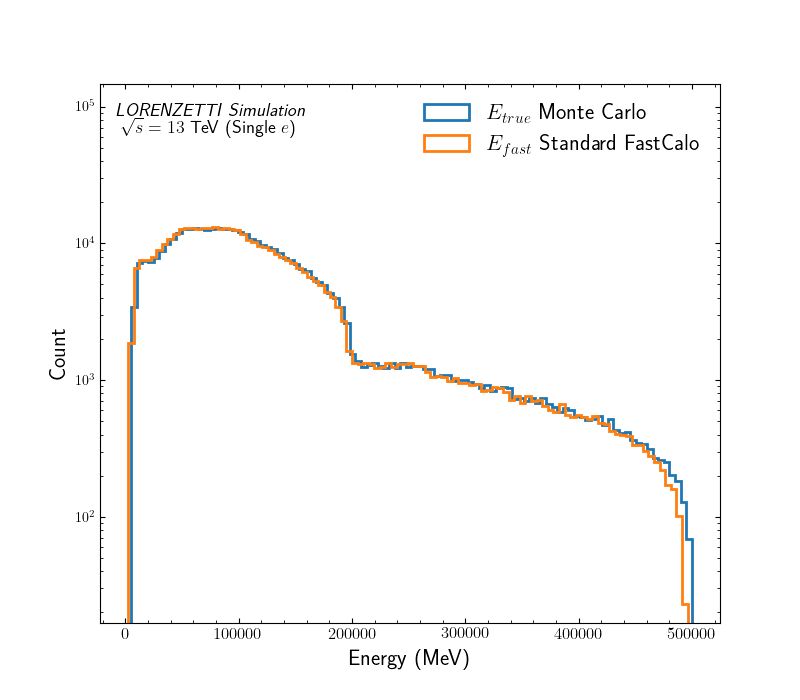

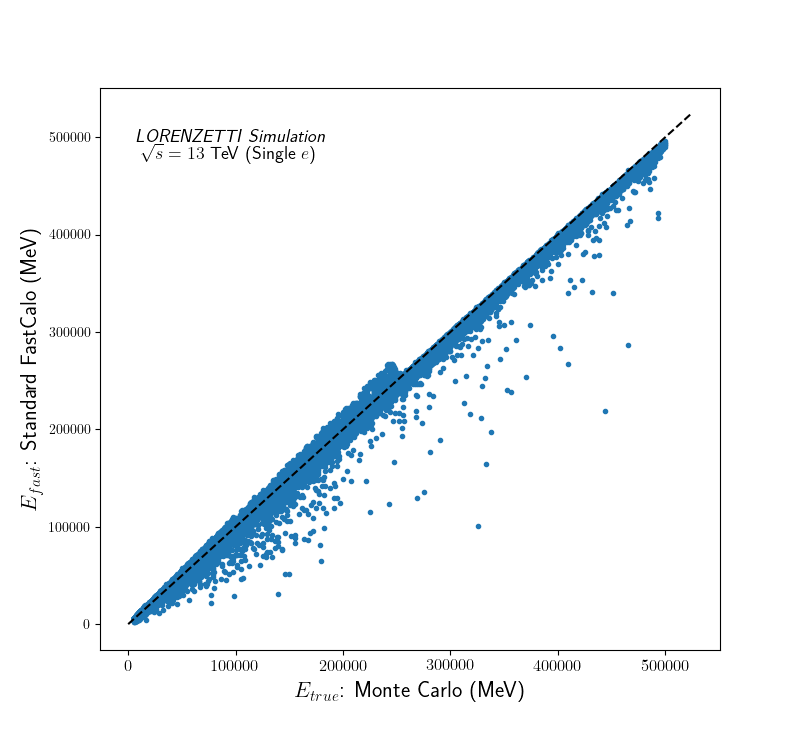

### Figure 6 — Standardized error and distribution goodness-of-fit

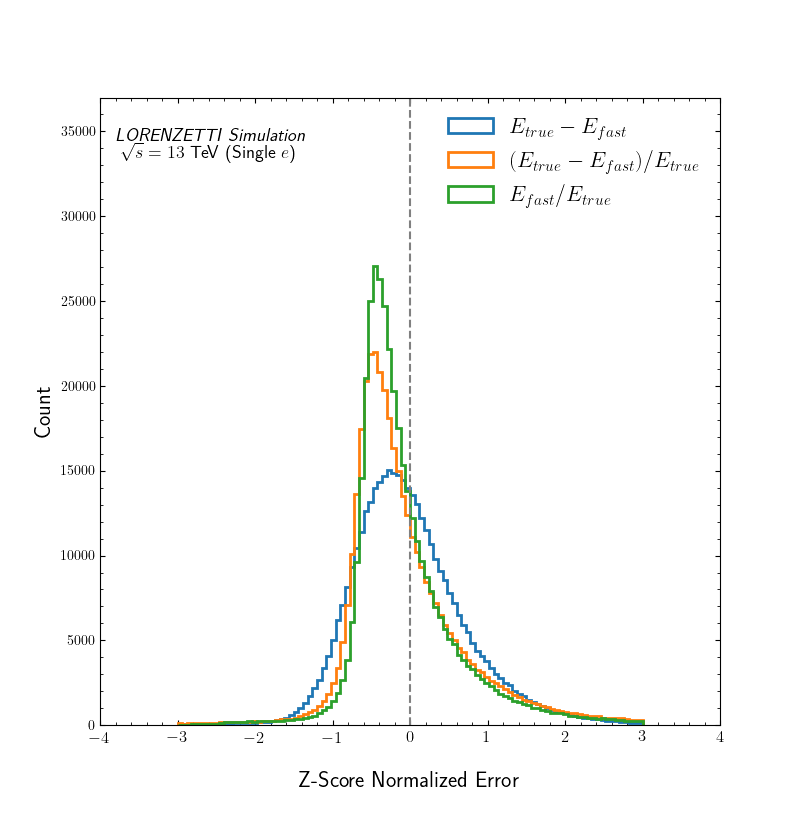

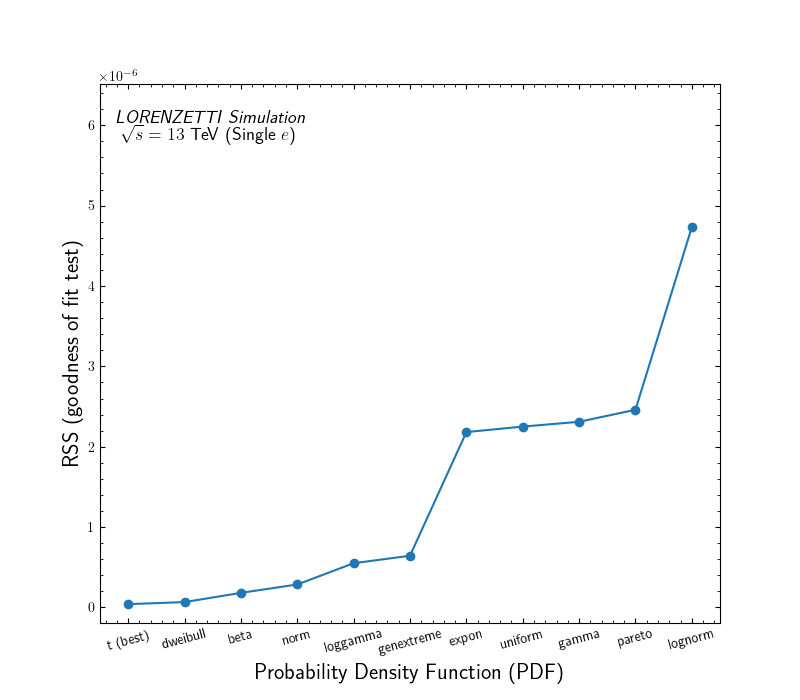

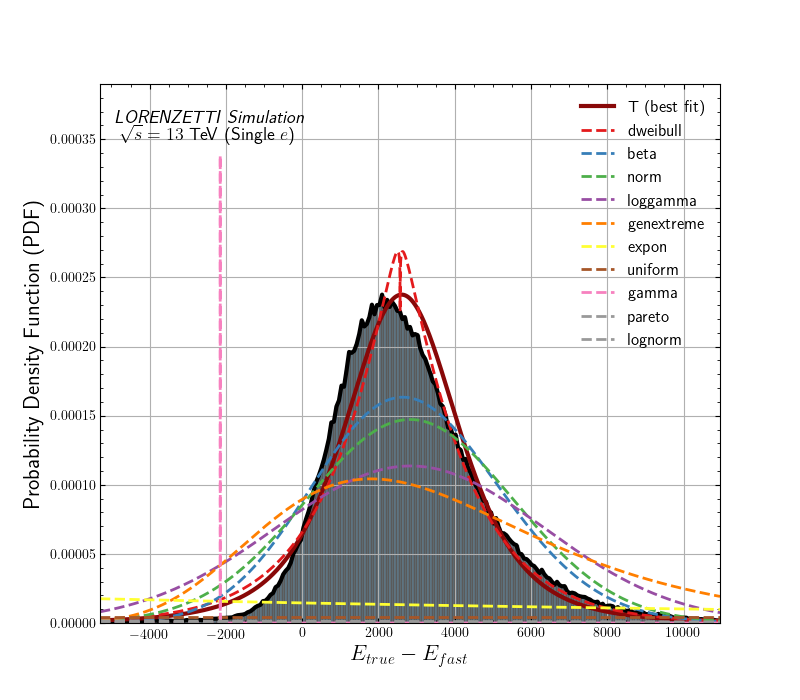

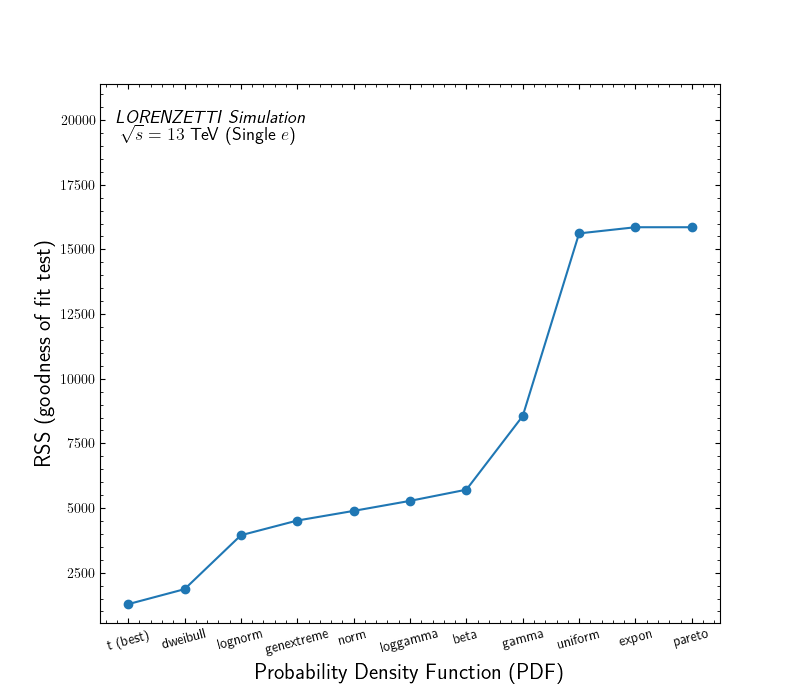

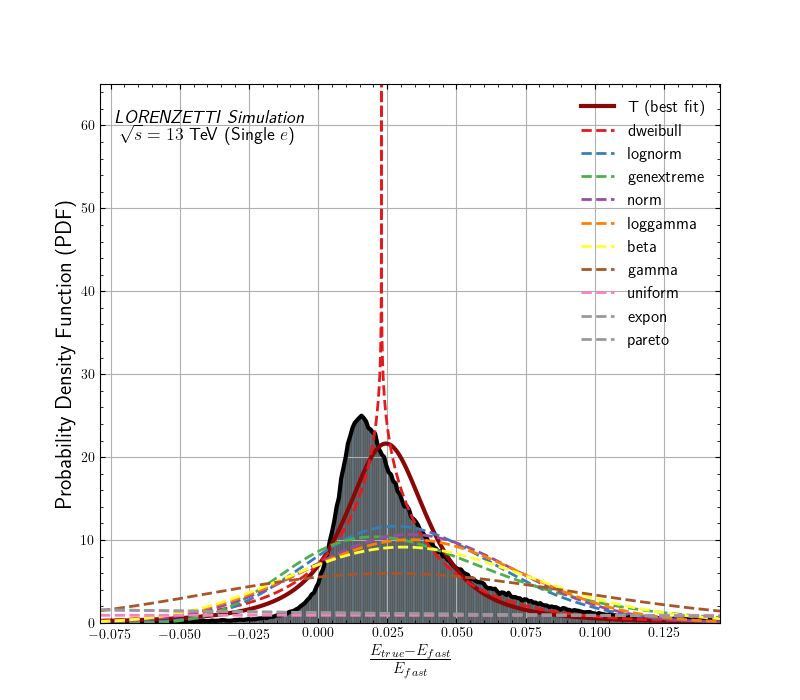

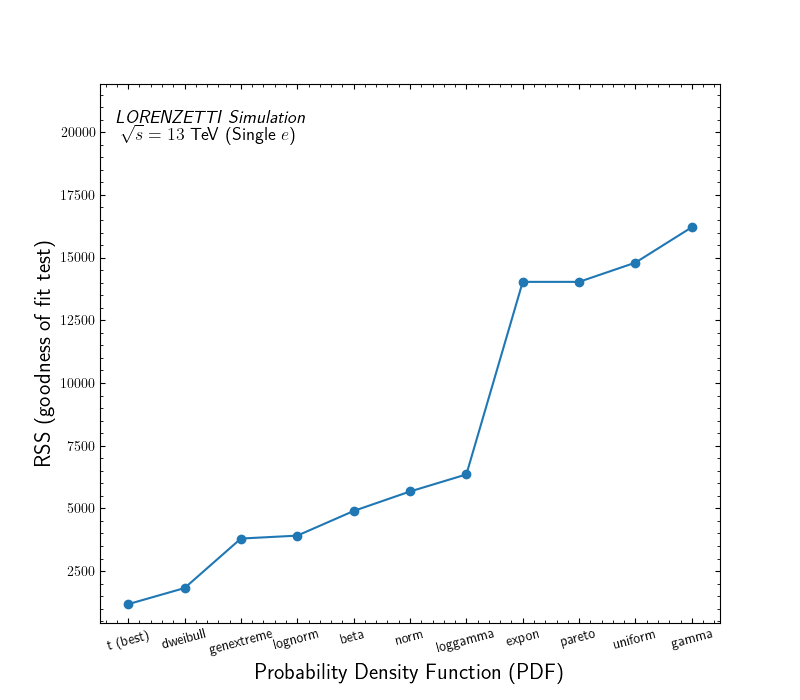

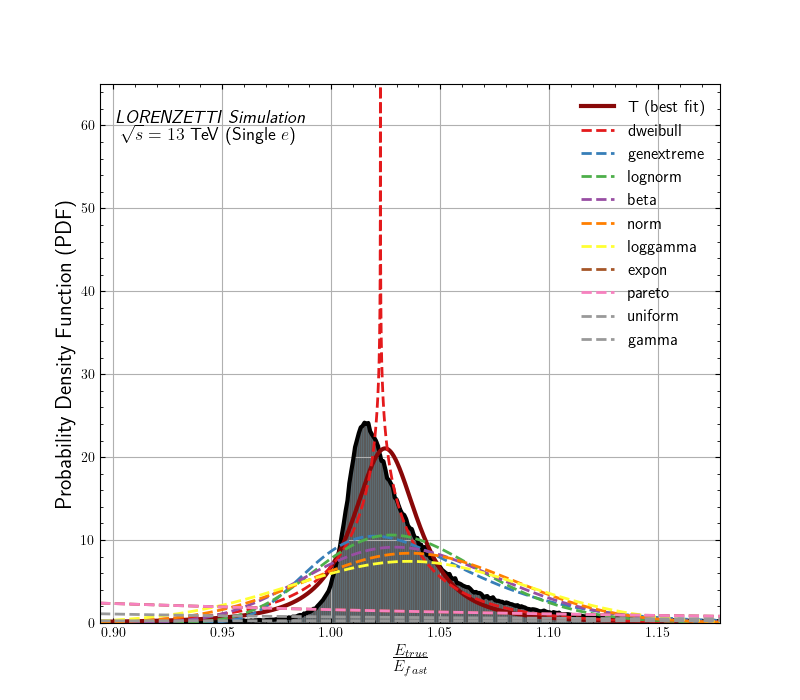

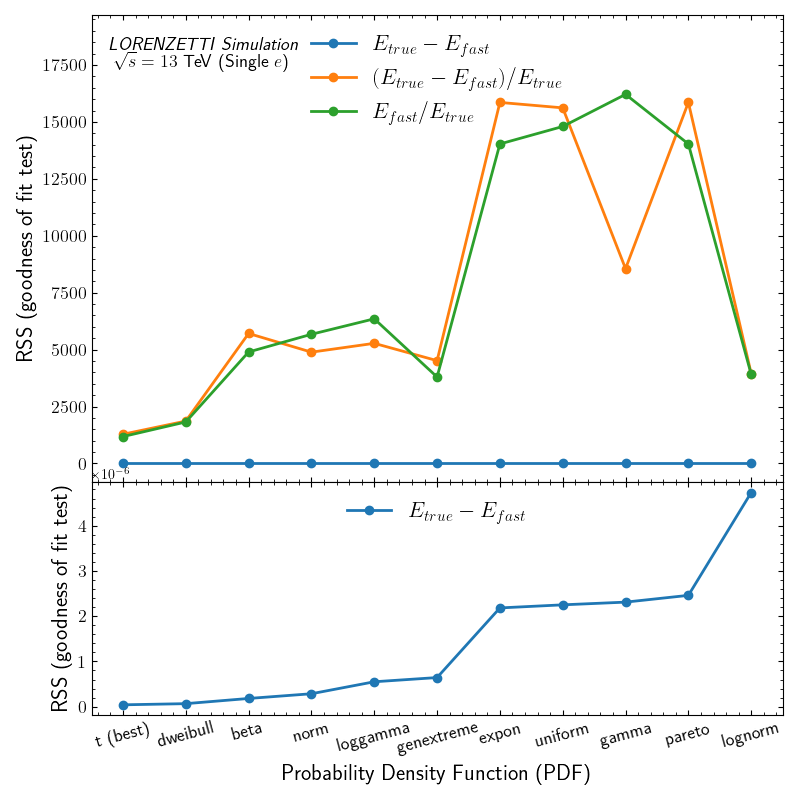

### Figure 7 — True calibration factor vs eta and ET

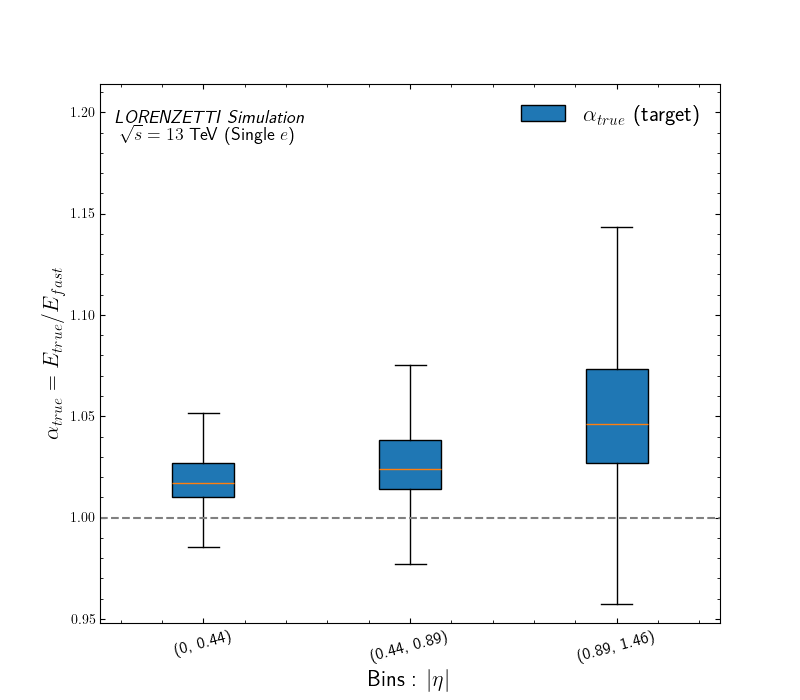

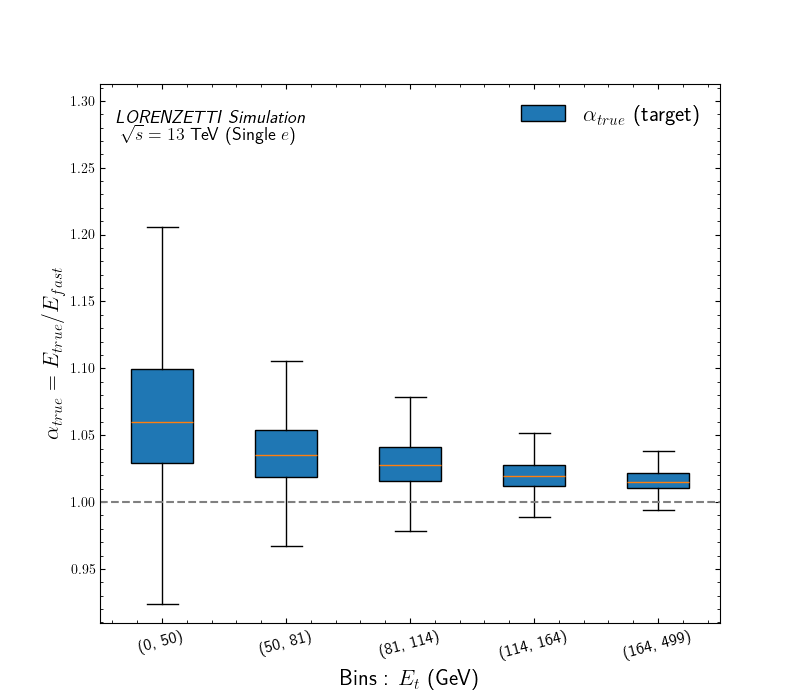

### Figure 8 — 100 ring distributions

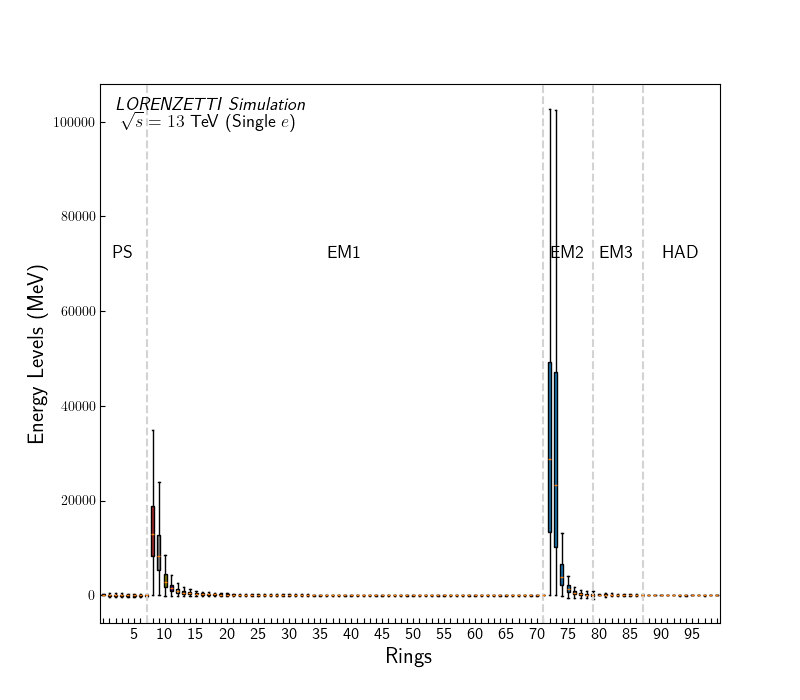

### Figure 9 — CORR, MI, PCA and ICA feature map

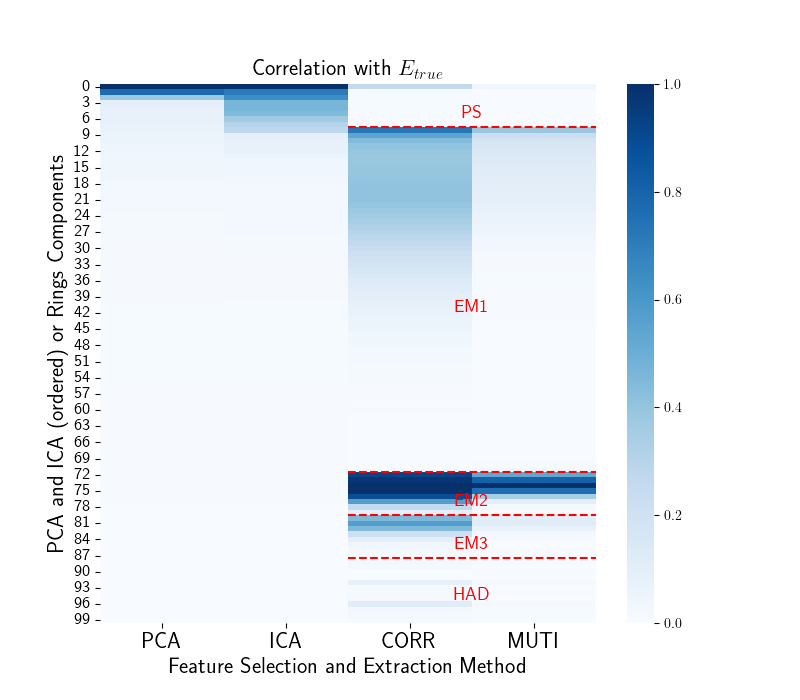

### Figure 10 — Calibration residual distributions by representation

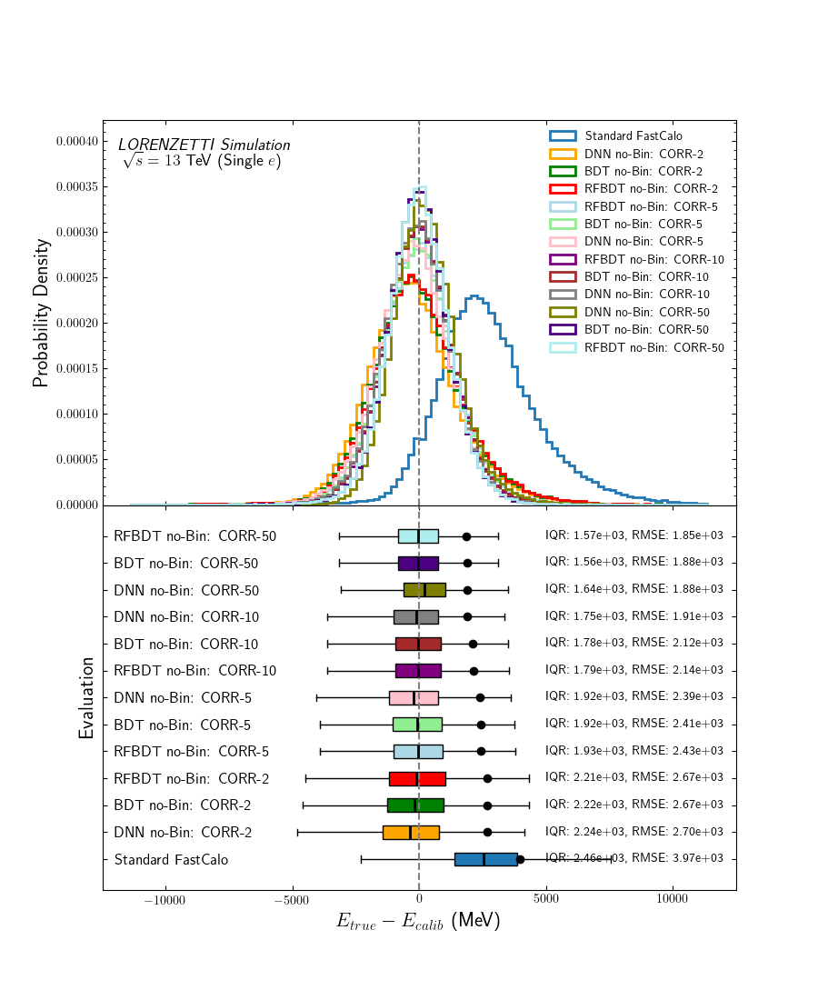

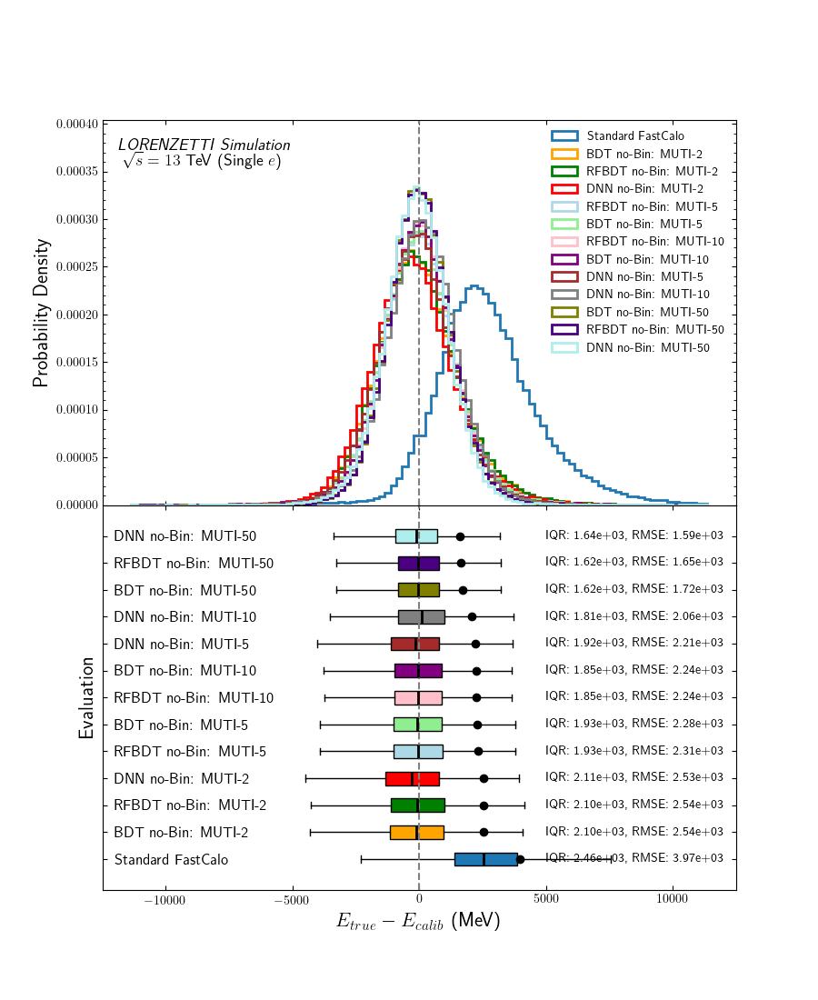

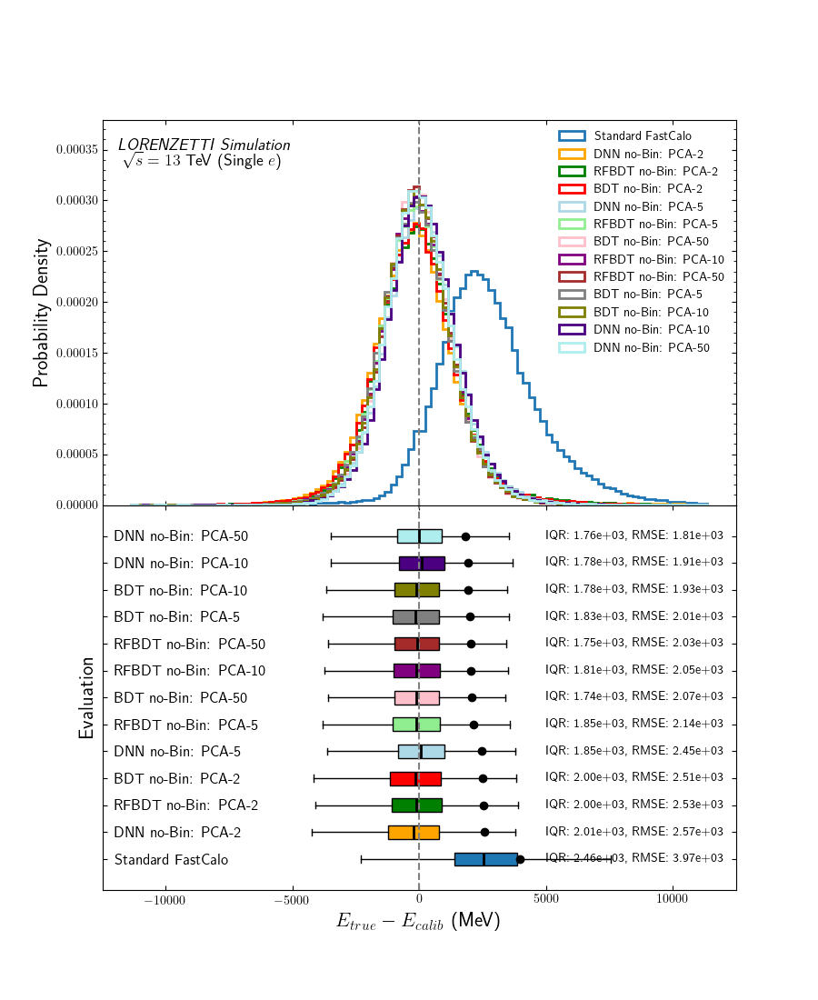

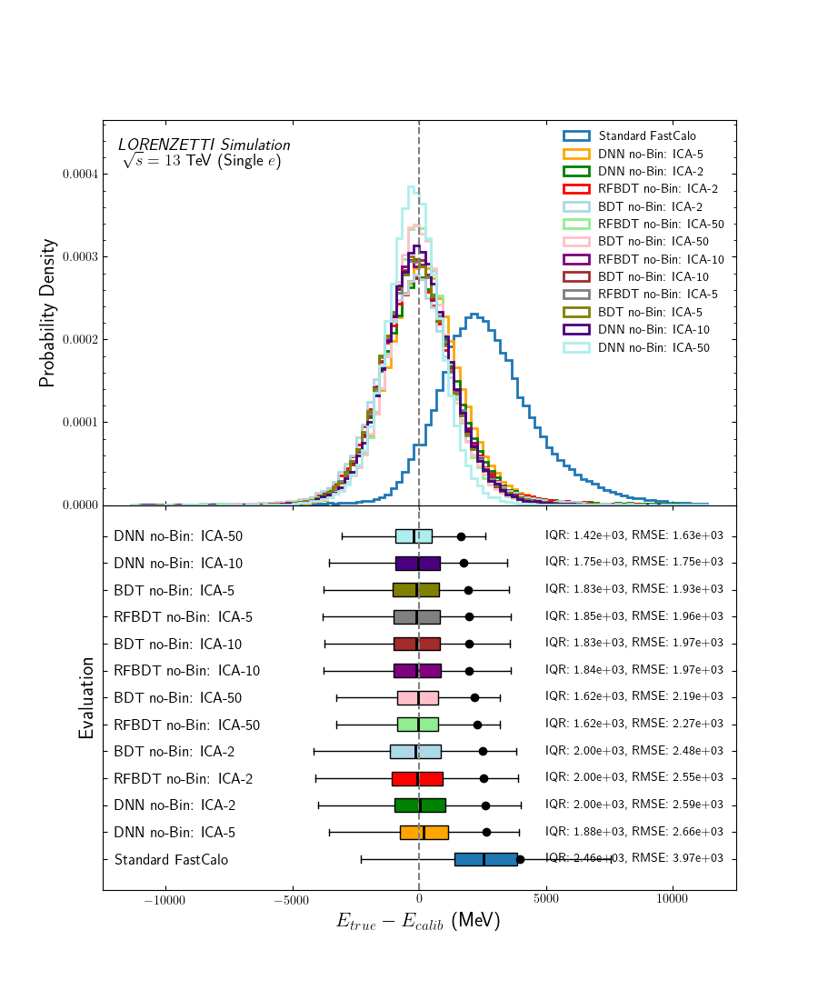

### Figure 11 — Joint error and complexity ranking

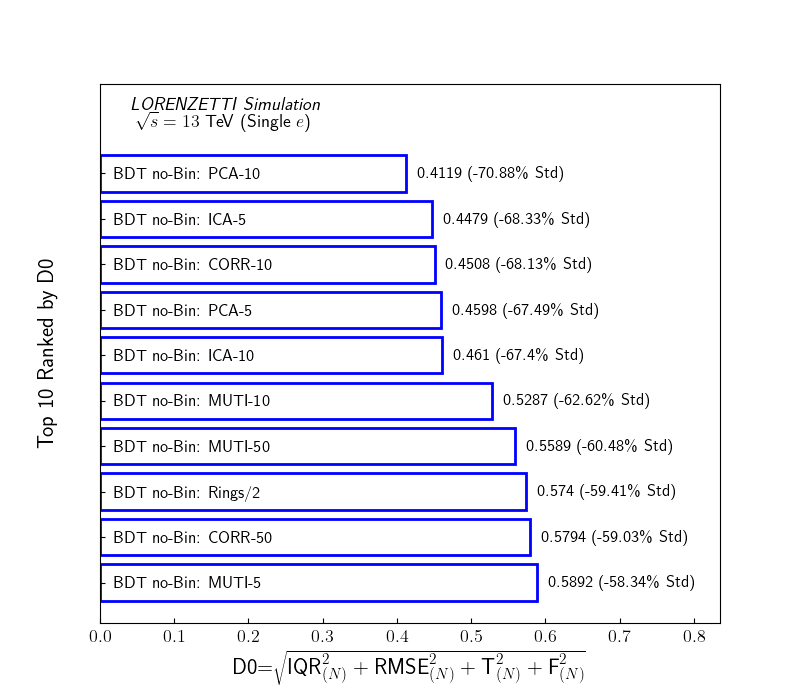

### Figure 12 — IQR in eta and energy regions

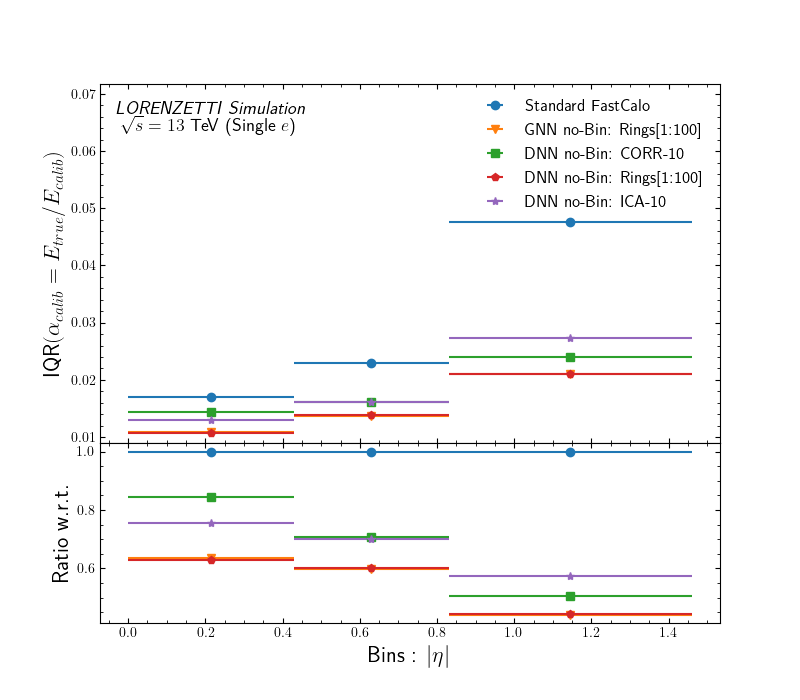

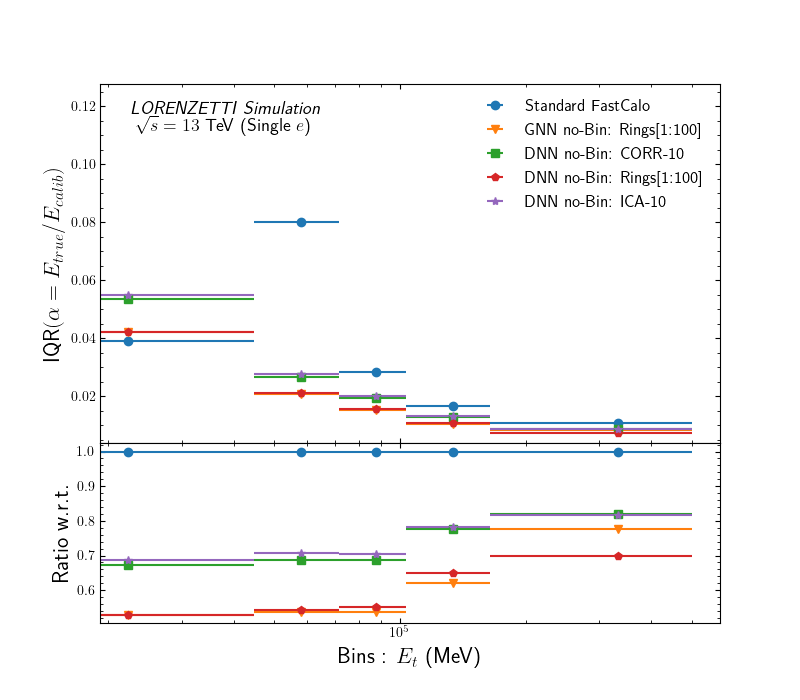

### Figure 13 — MAE and RMSE in eta and energy regions

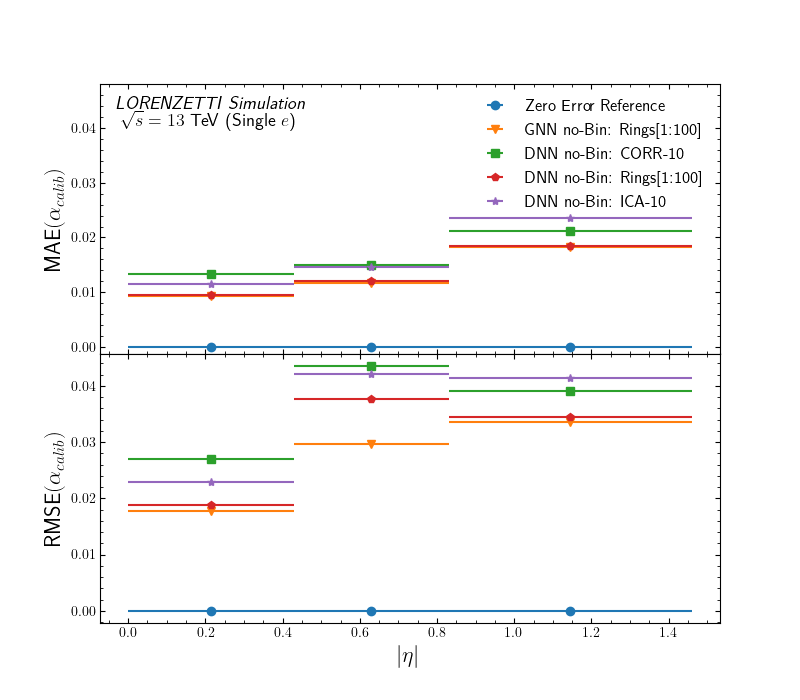

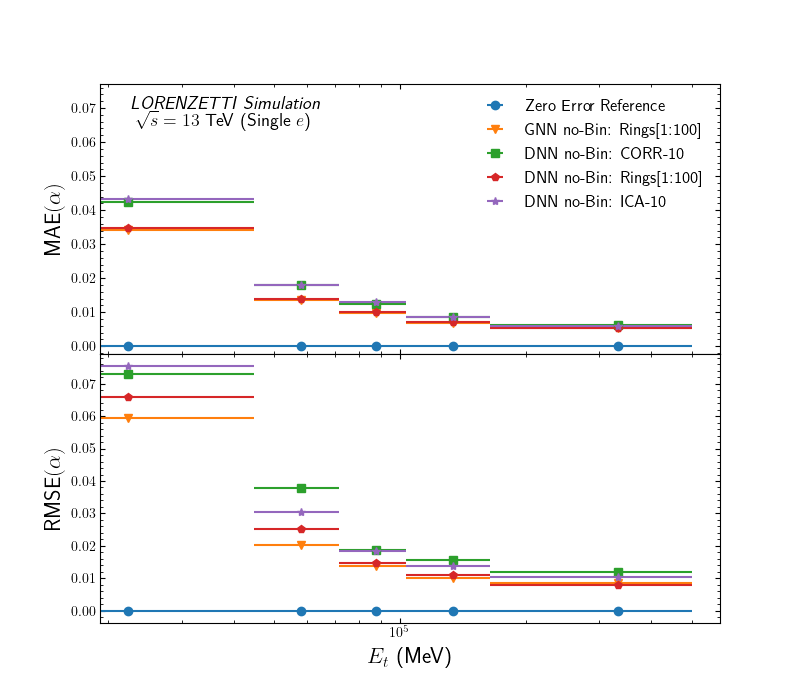

### Figure 14 — Calibration-factor regional boxplots

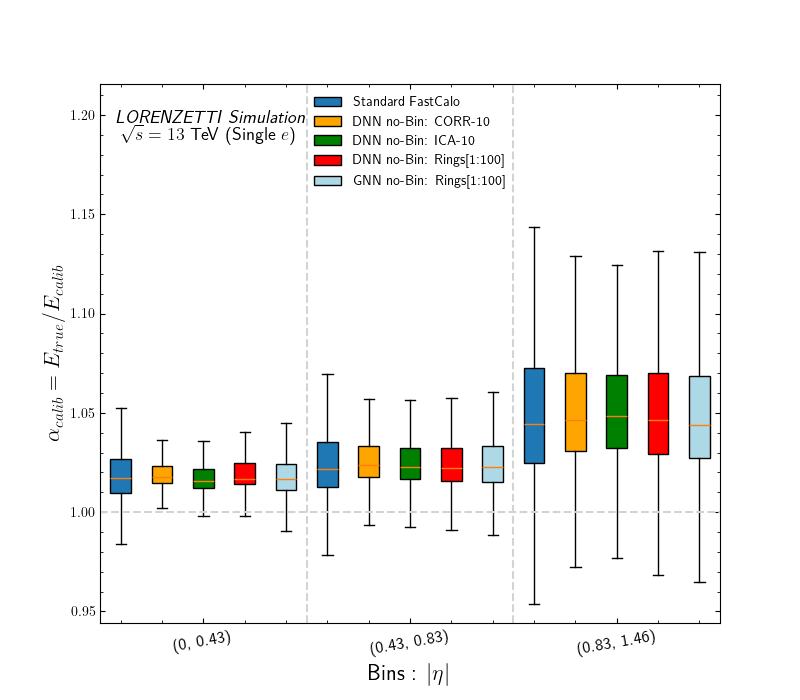

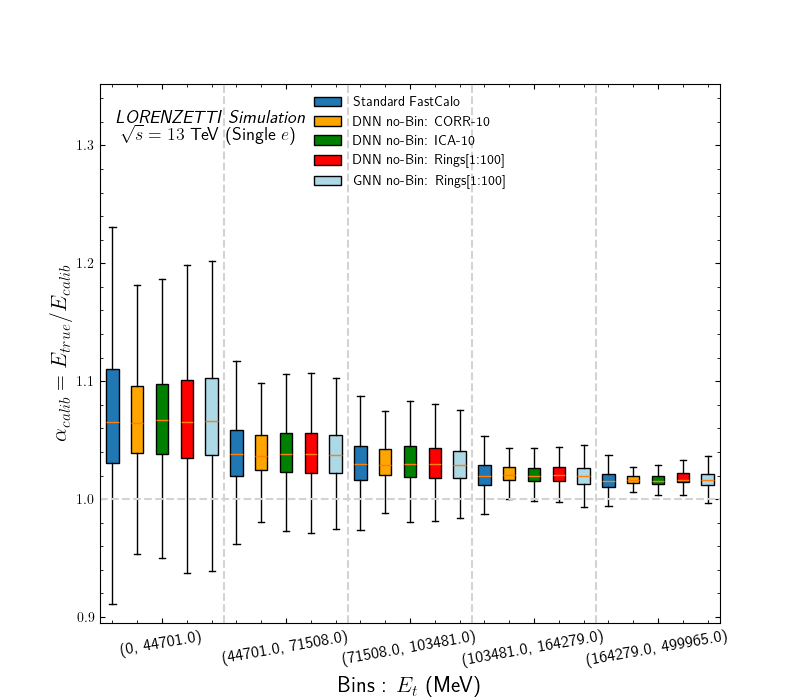

### Figure 15 — Relative energy resolution curves

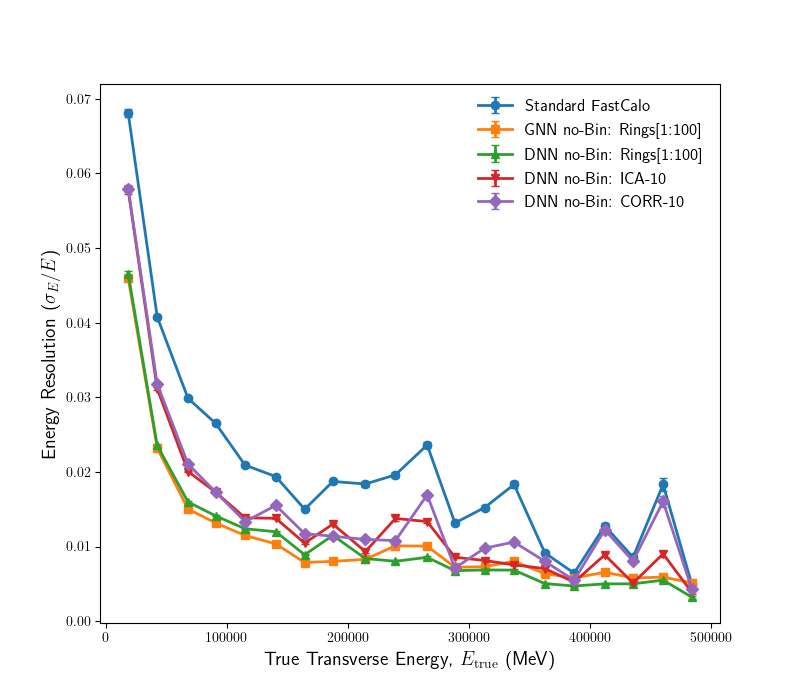

### Figure 16 — Threshold acceptance curves

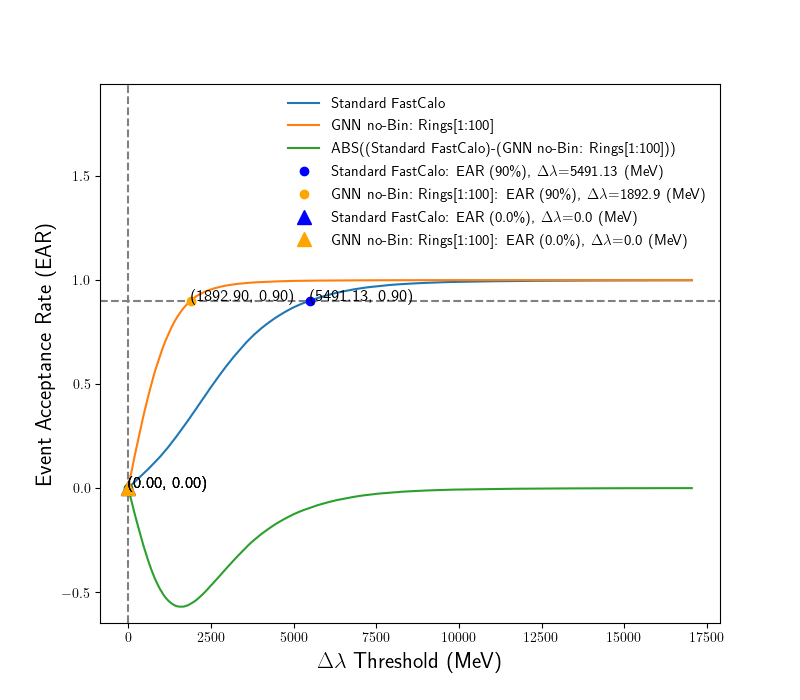

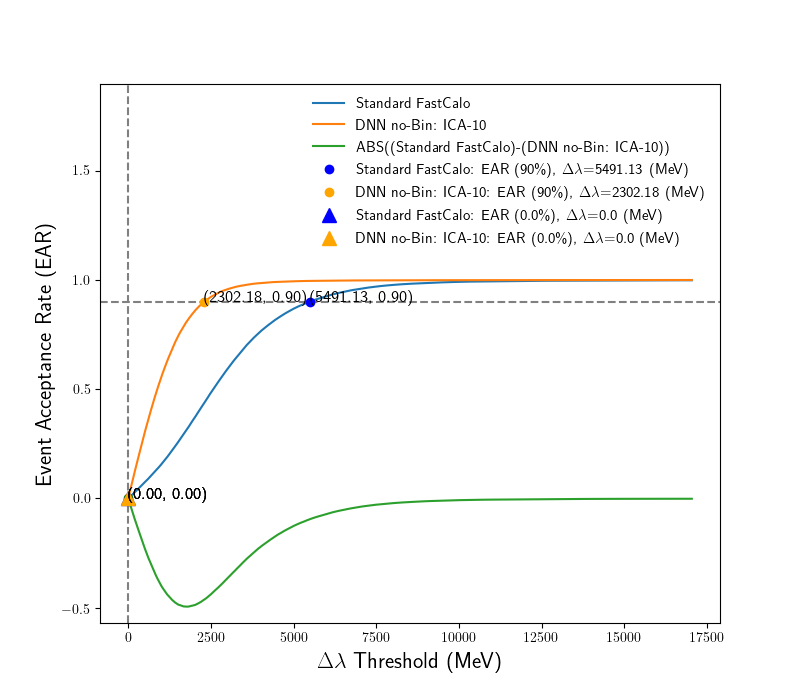

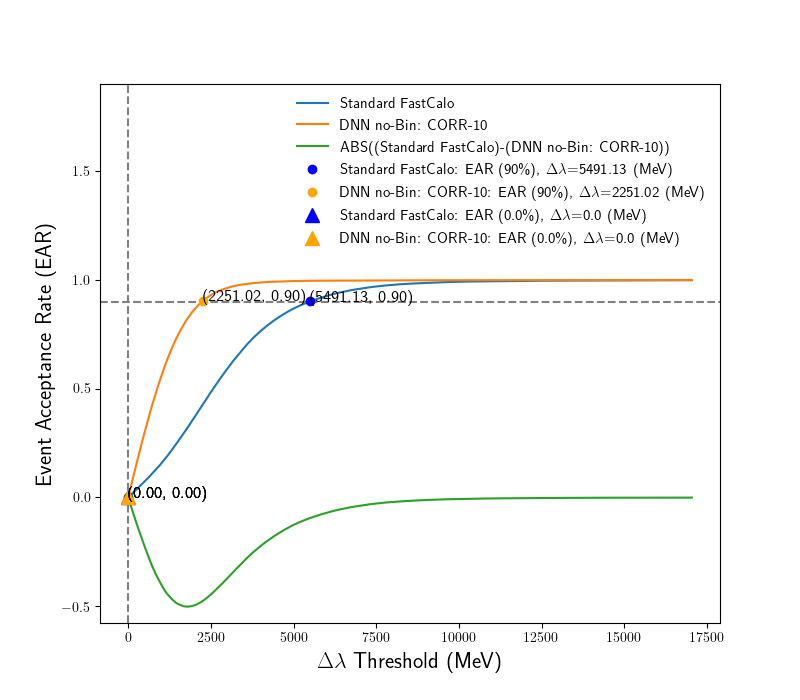

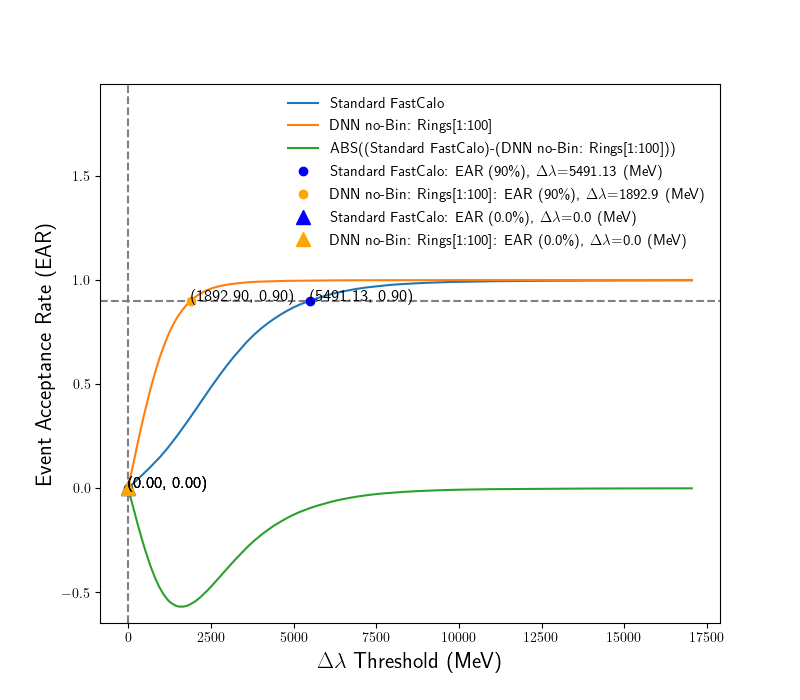

### Figure 17 — Fast versus calibrated energy scatter

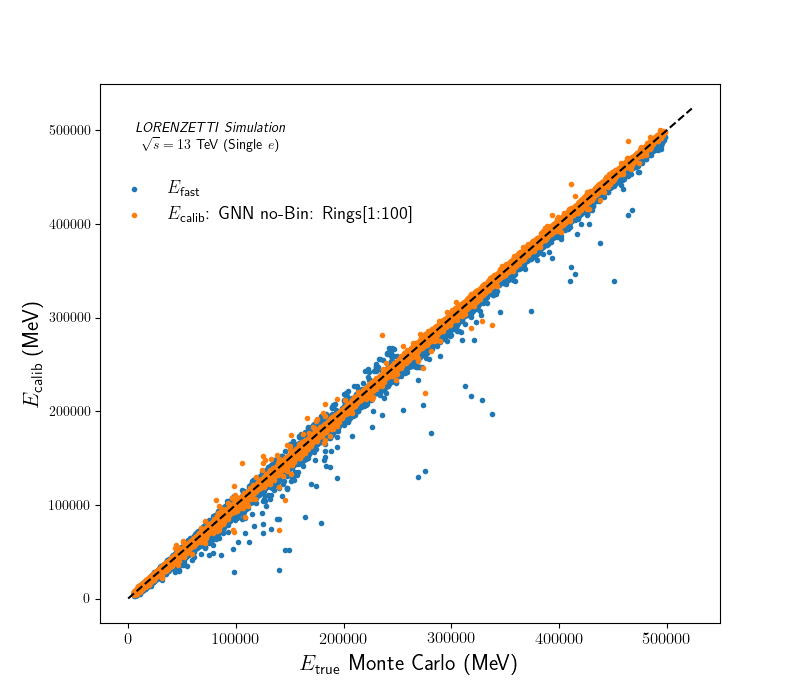

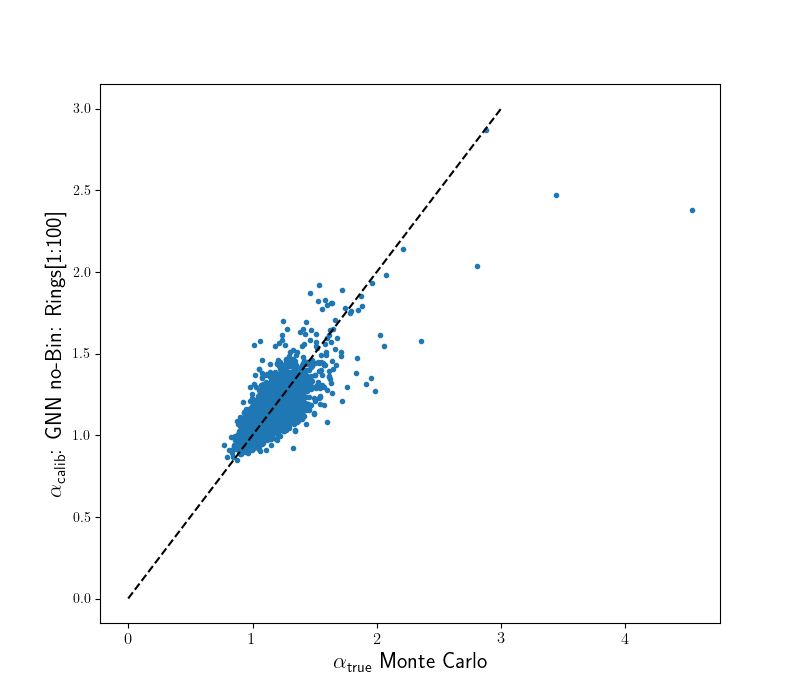

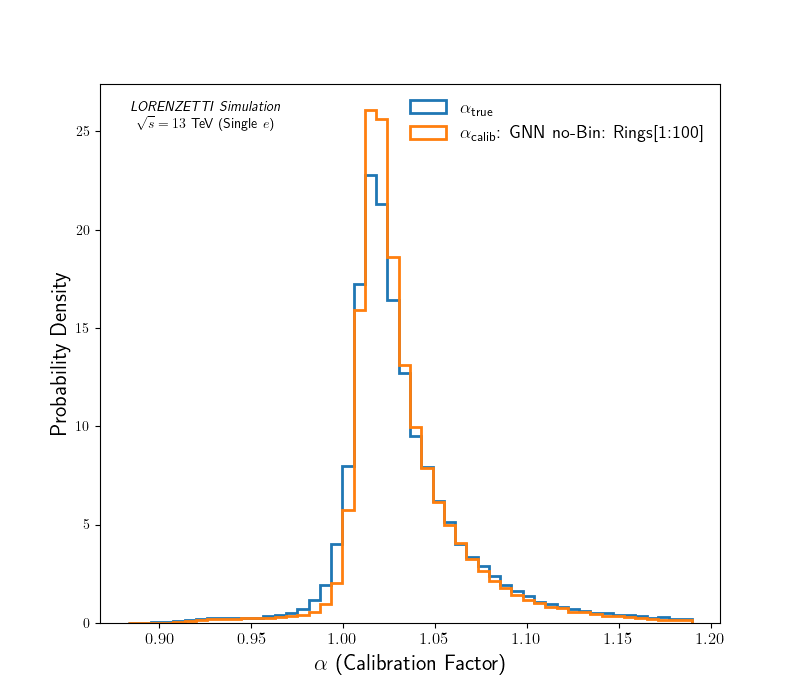

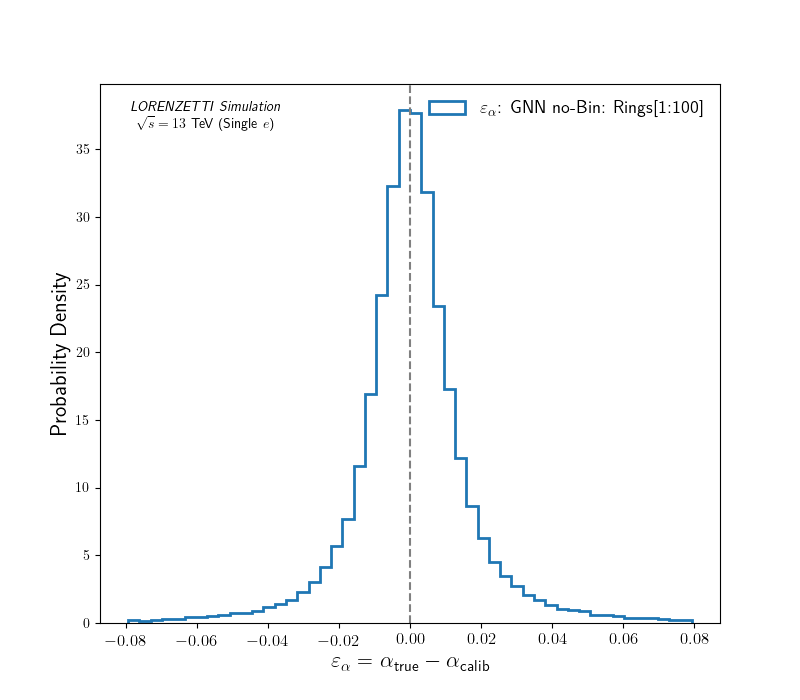

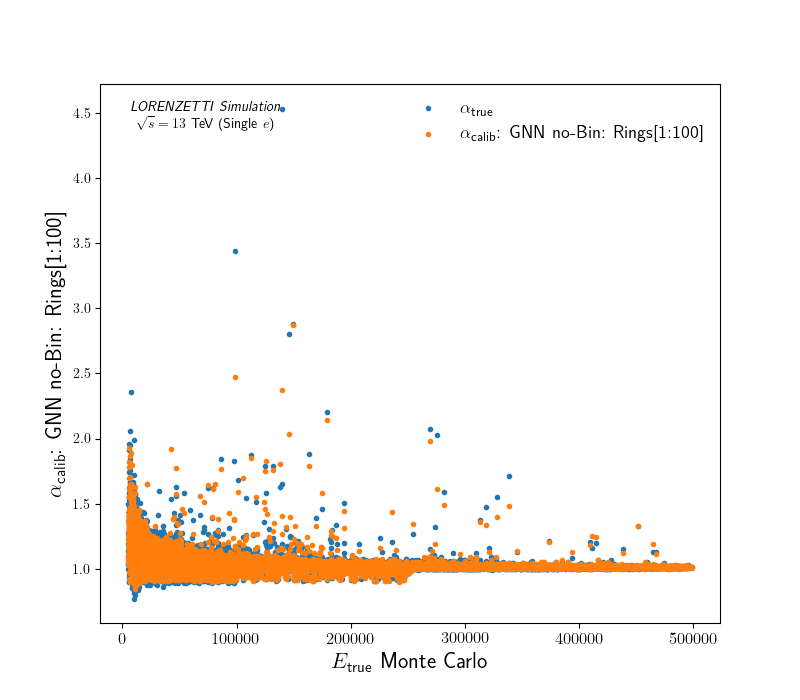

...

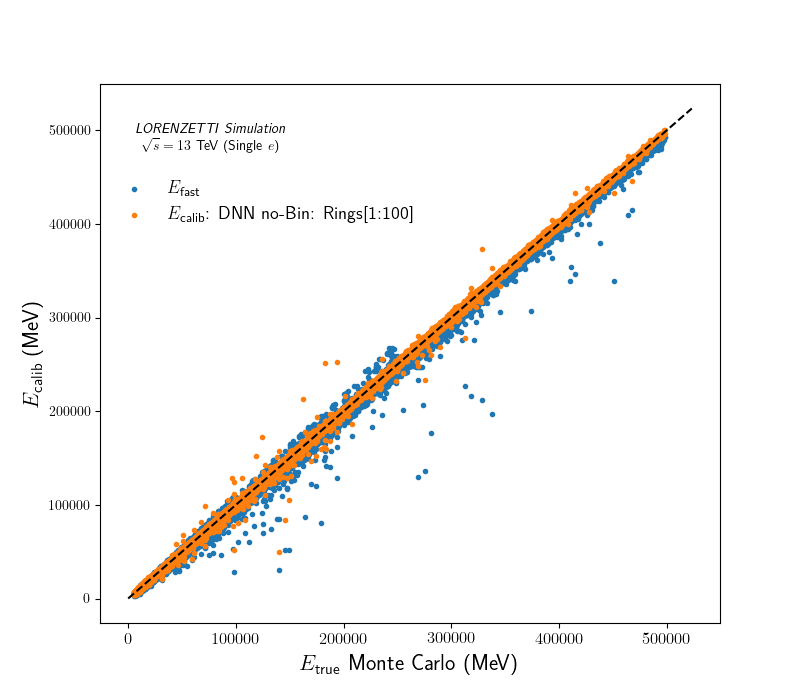

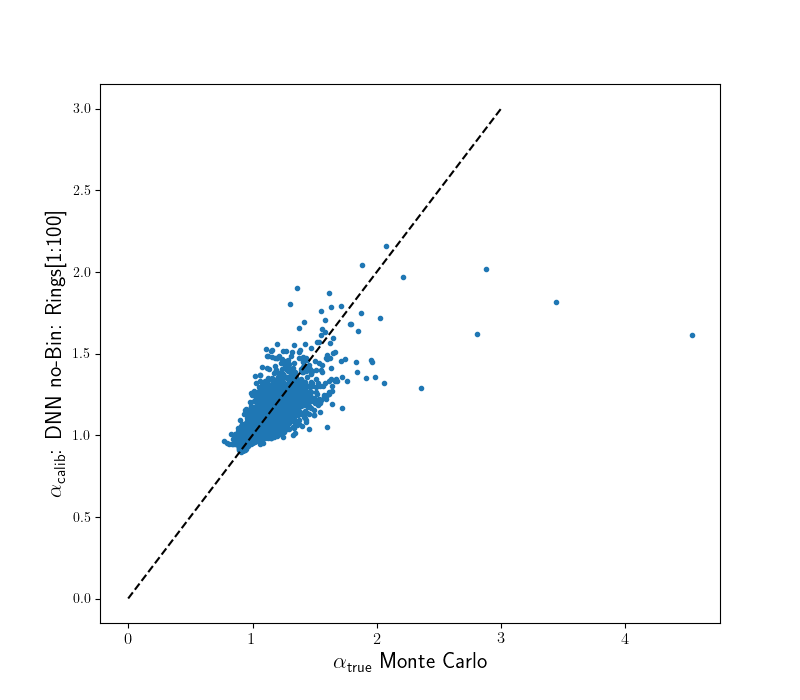

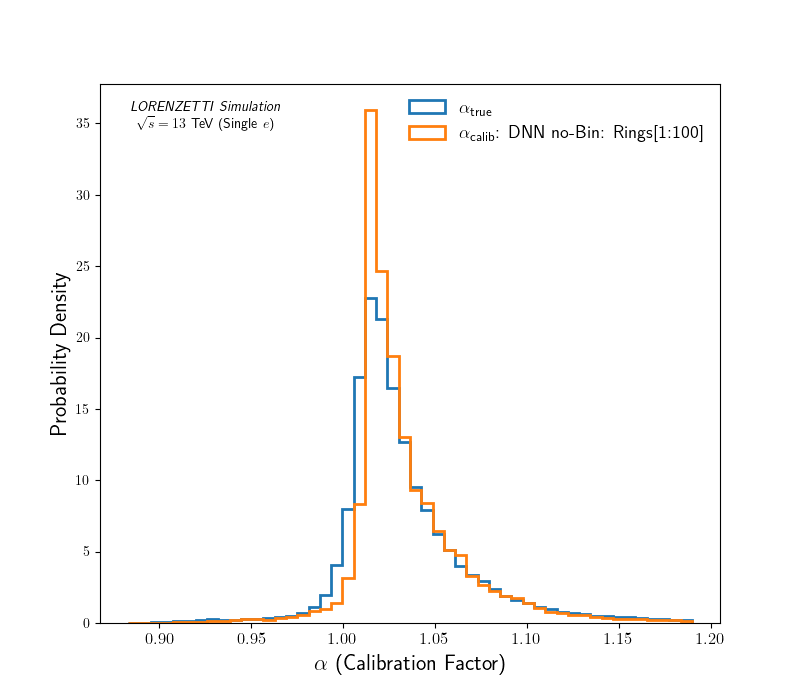

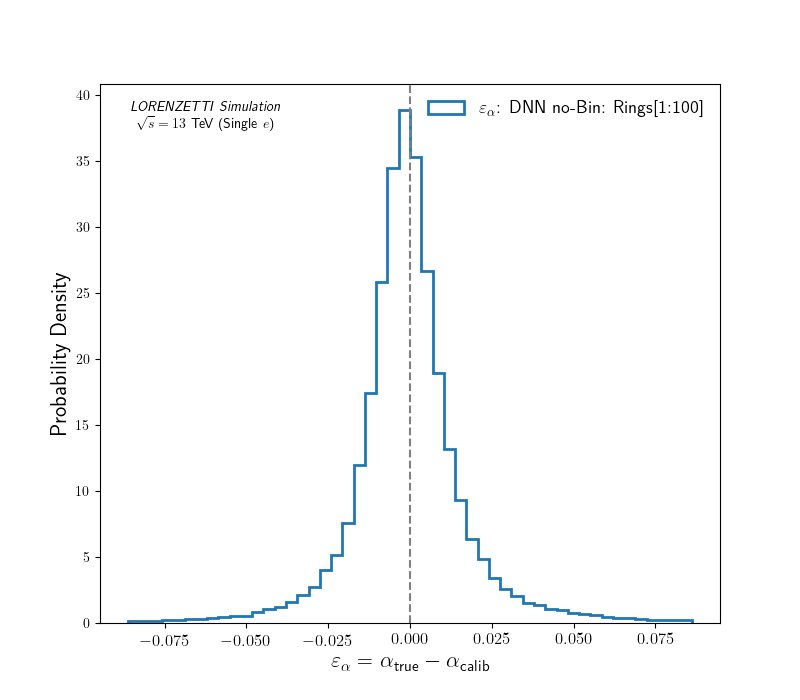

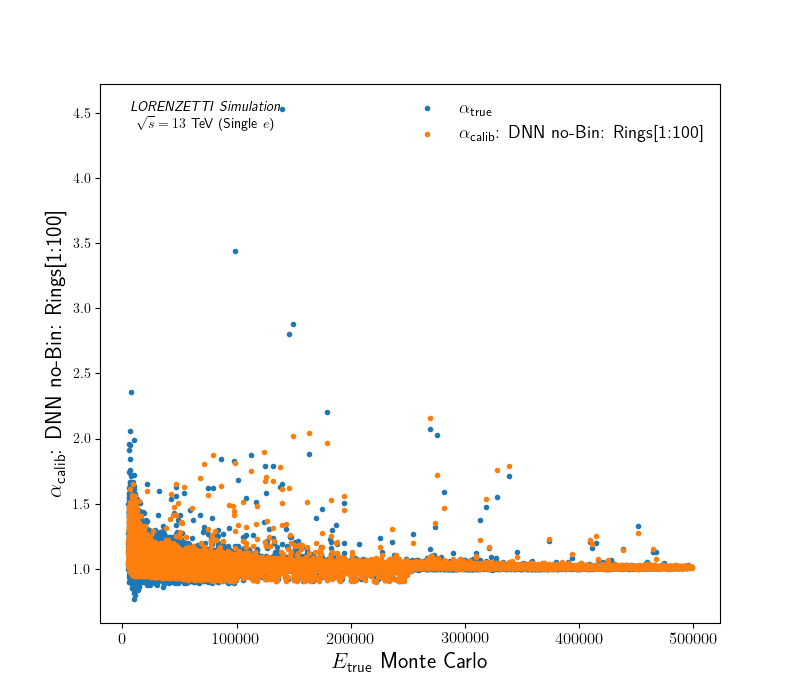

### Figure 18 — Compact neural calibration performance

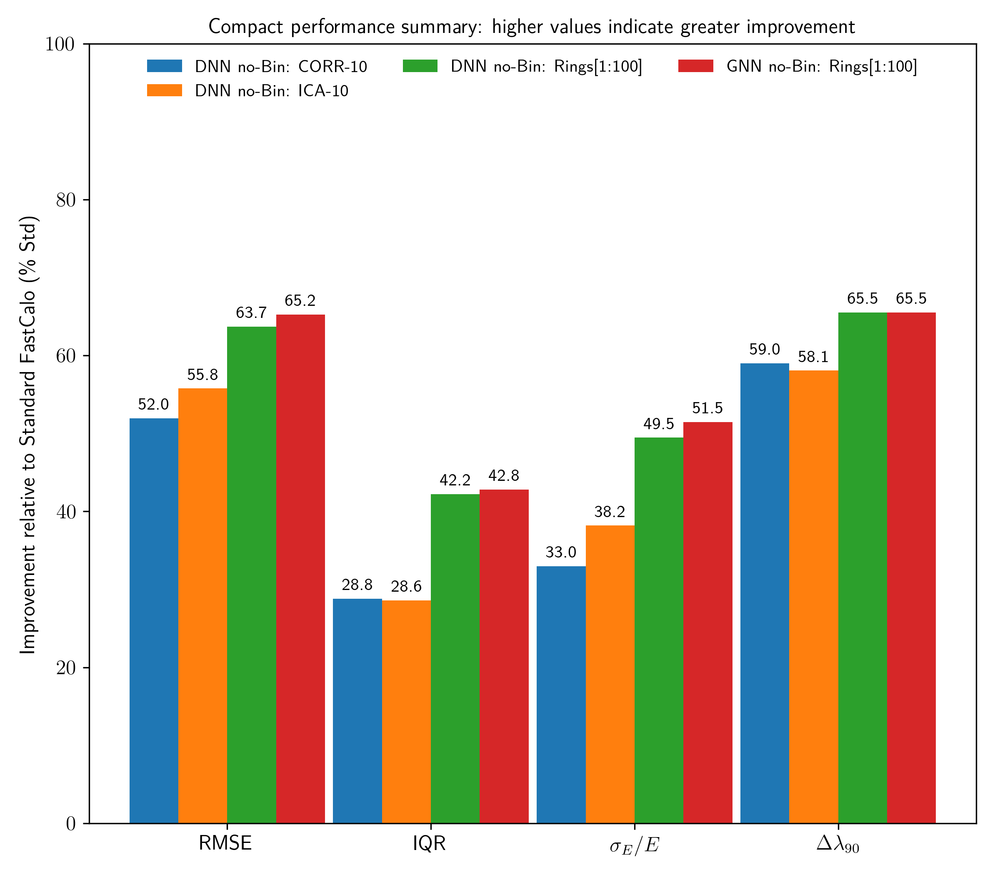

### Figure 19 — Neural accuracy–efficiency trade-off

Status: missing_input
Unresolved inputs: original_Fig38


### Figure 20 — Error normal Q-Q comparison

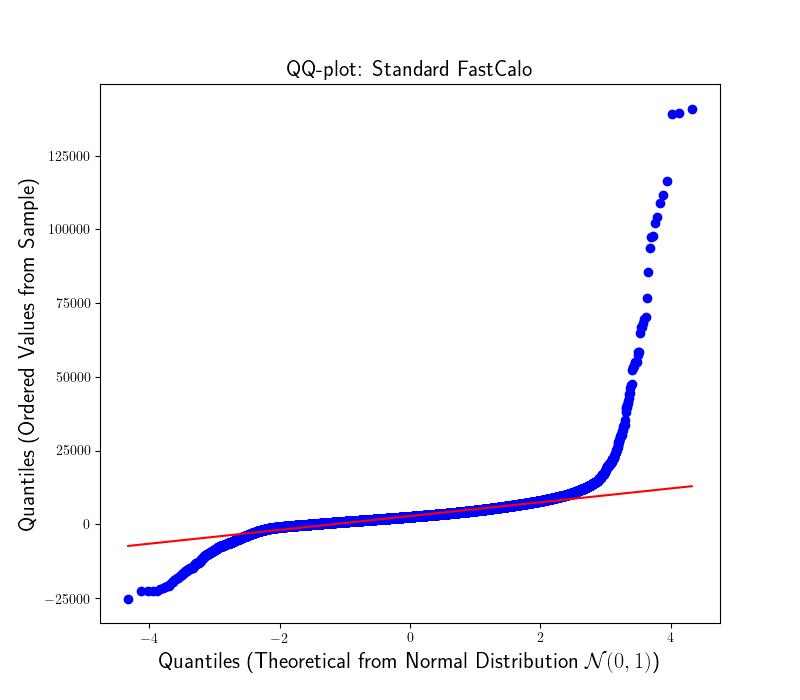

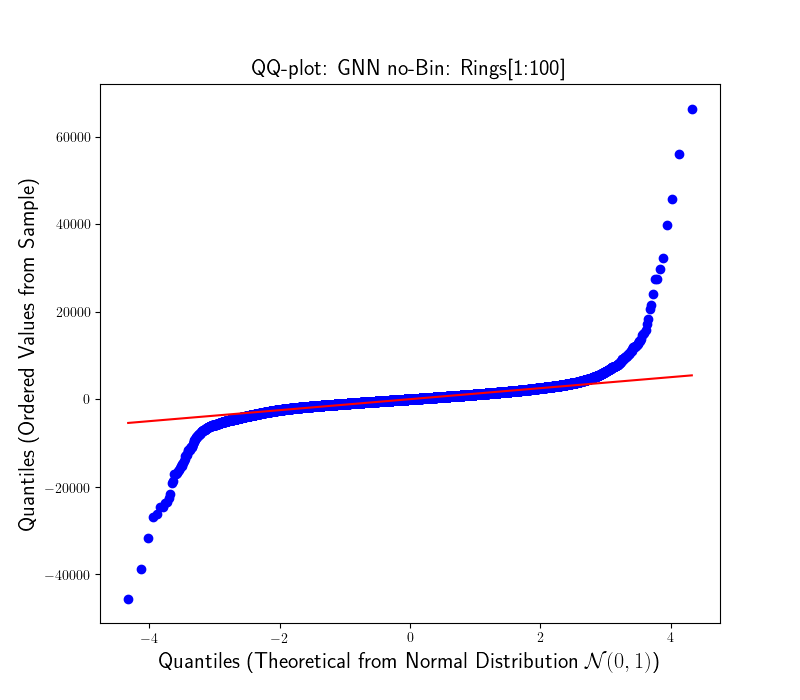

### Additional archived configurations

original_resolution_01.png


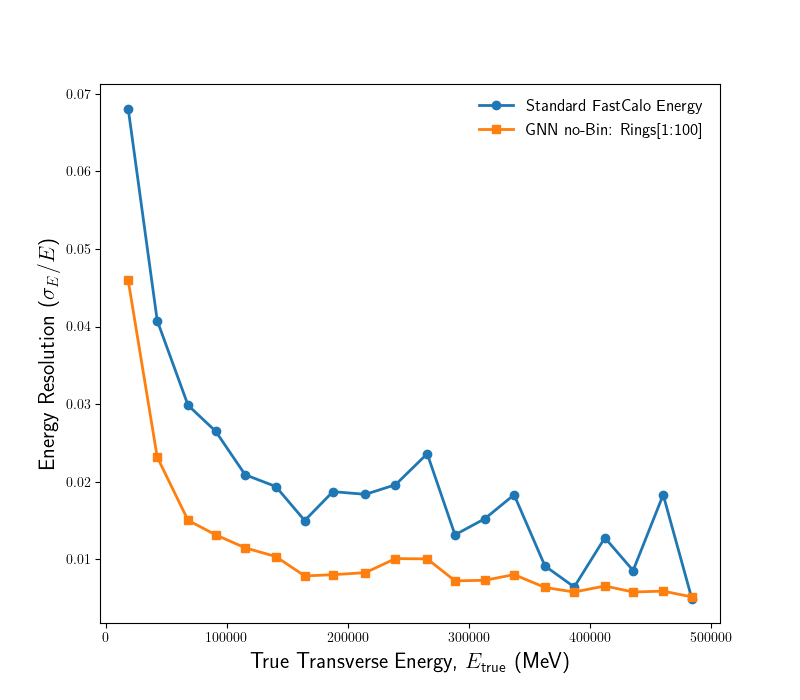

original_resolution_comparison_01_01.png


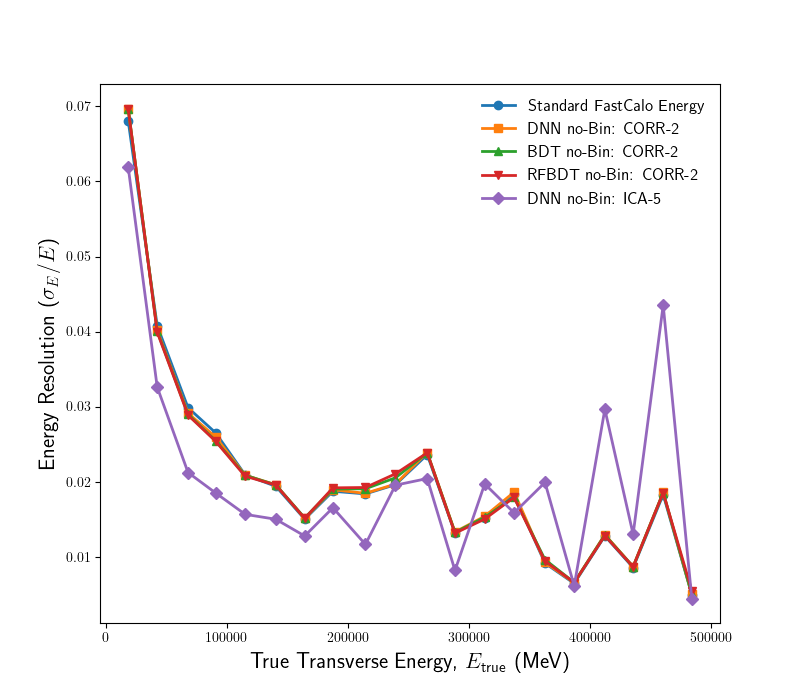

original_resolution_comparison_02_01.png


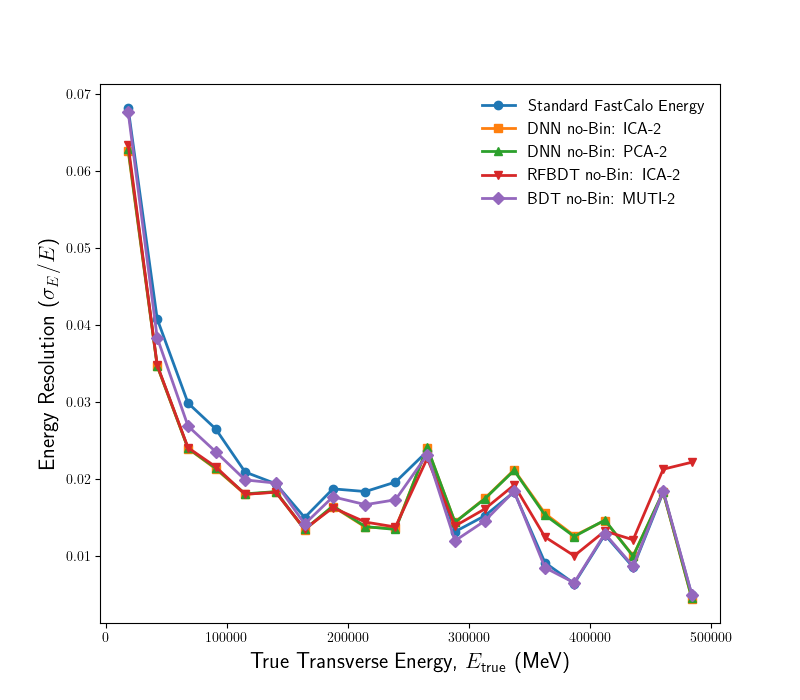

original_resolution_comparison_03_01.png


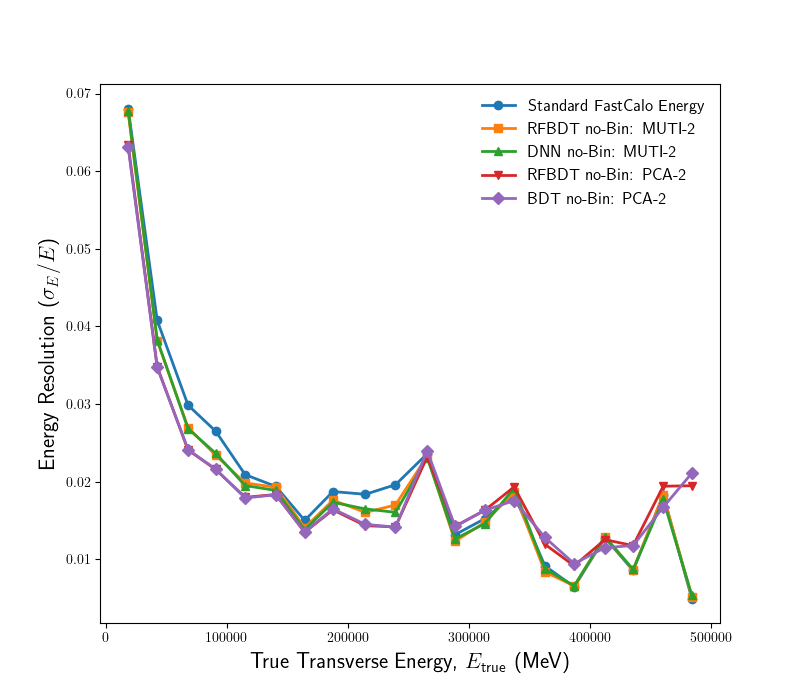

original_resolution_comparison_04_01.png


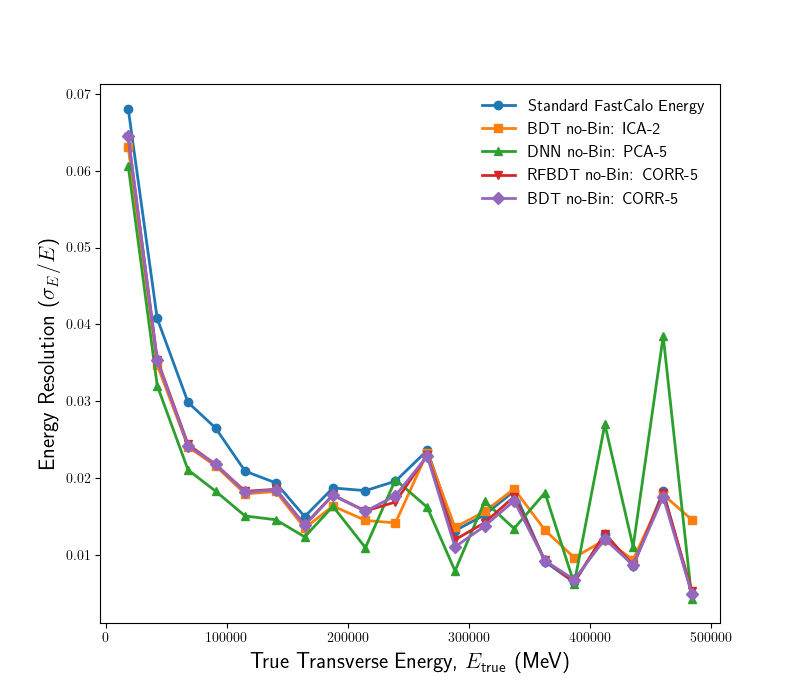

original_resolution_comparison_05_01.png


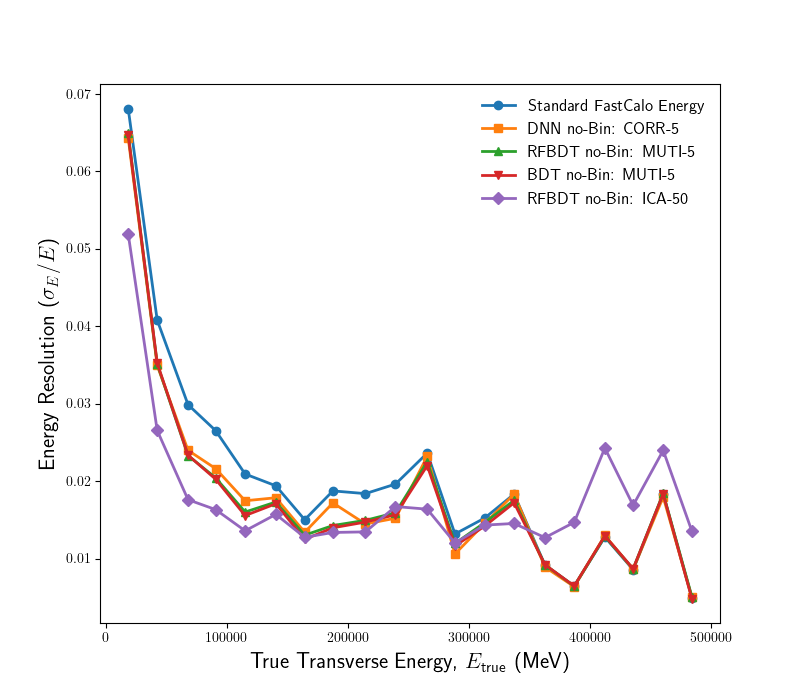

original_resolution_comparison_06_01.png


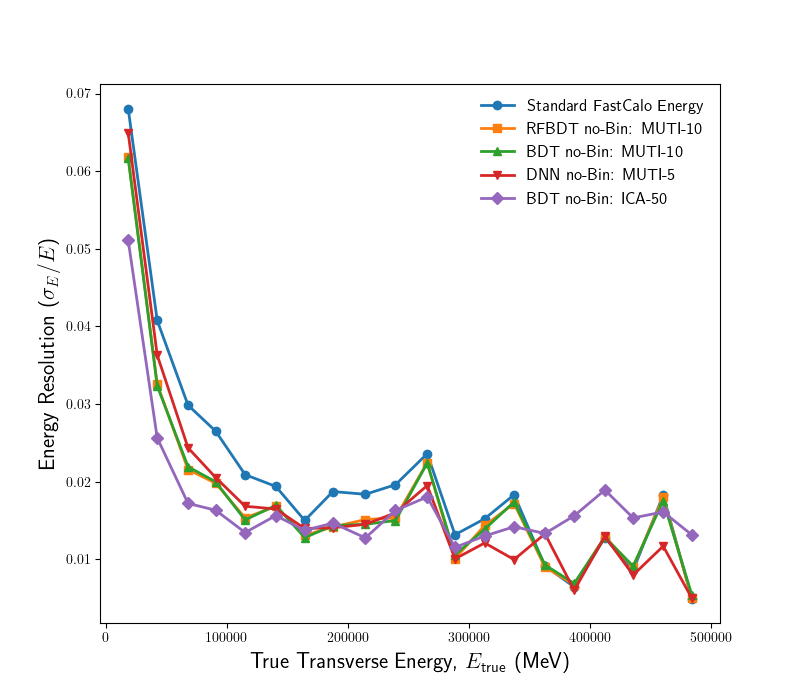

original_resolution_comparison_07_01.png


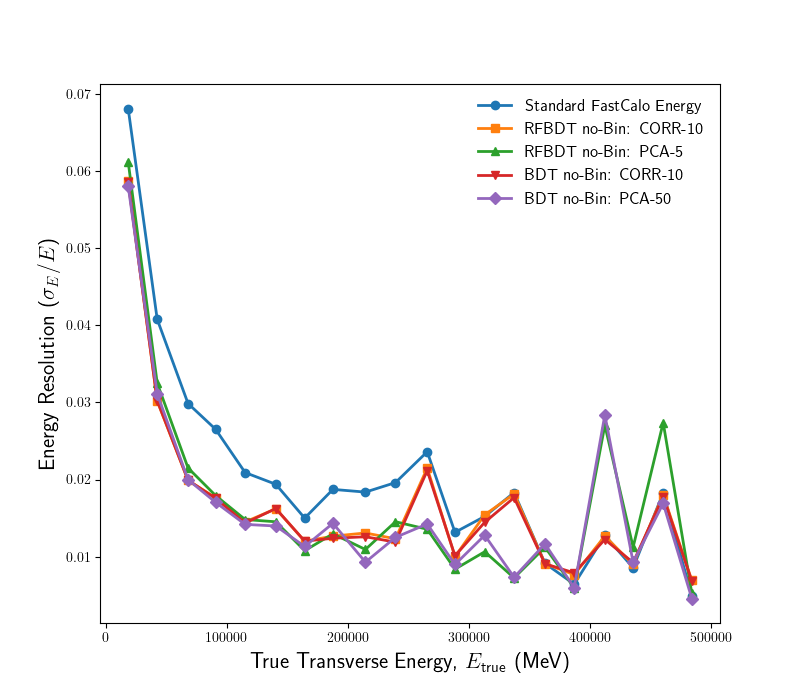

original_resolution_comparison_08_01.png


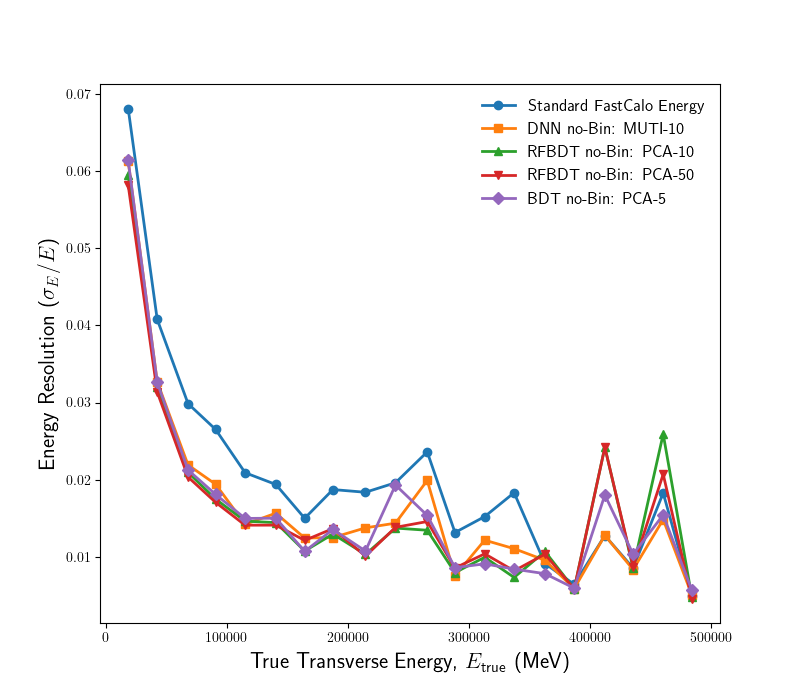

original_resolution_comparison_09_01.png


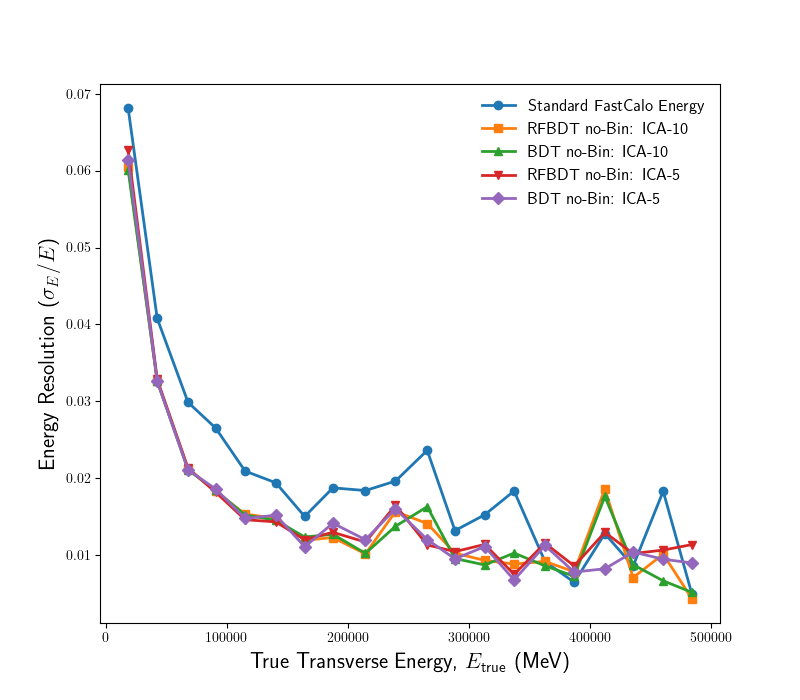

original_resolution_comparison_10_01.png


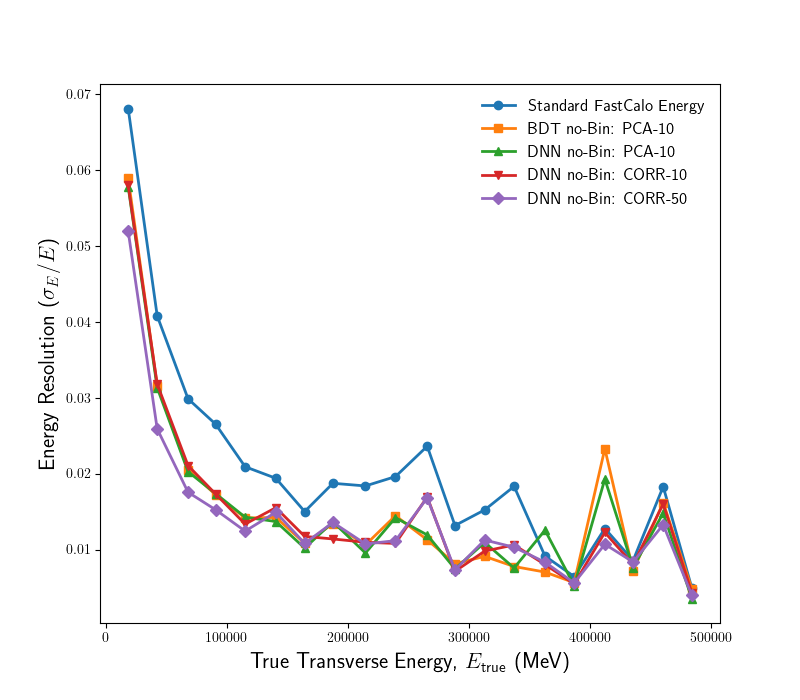

original_resolution_comparison_11_01.png


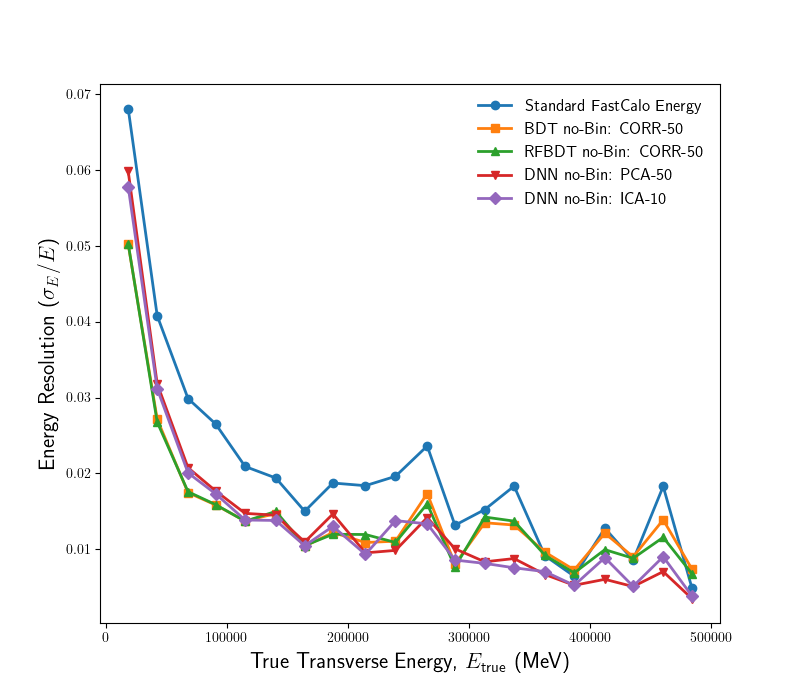

original_resolution_comparison_12_01.png


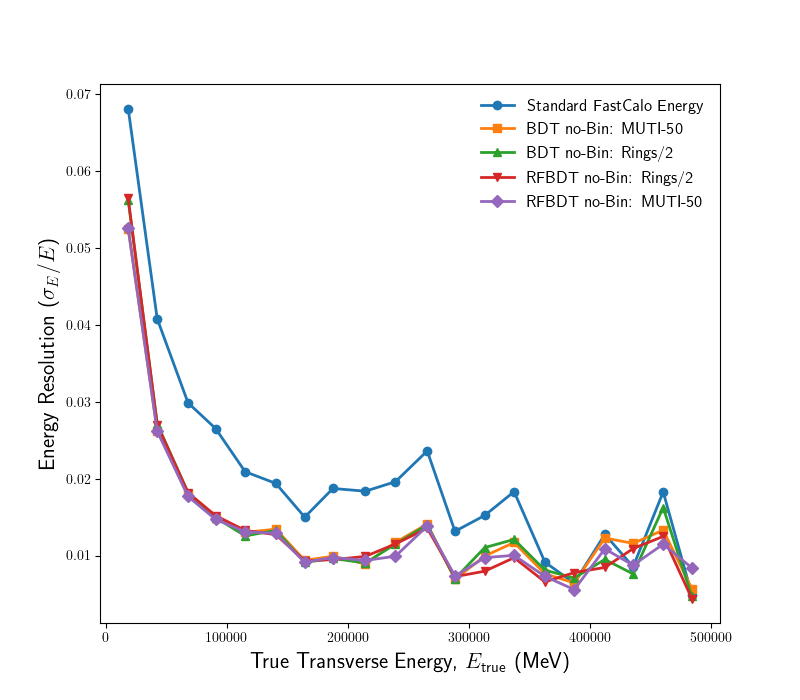

original_resolution_comparison_13_01.png


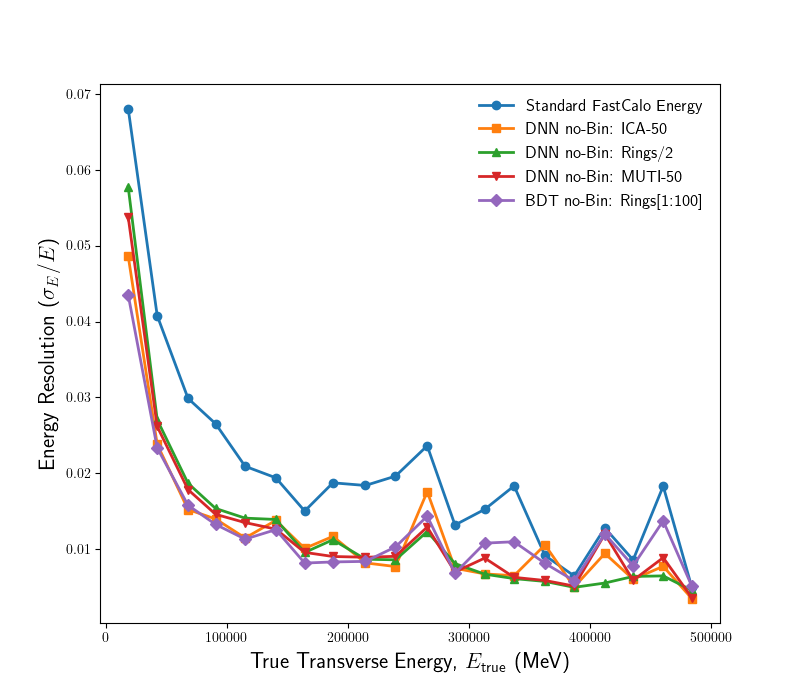

original_resolution_comparison_14_01.png


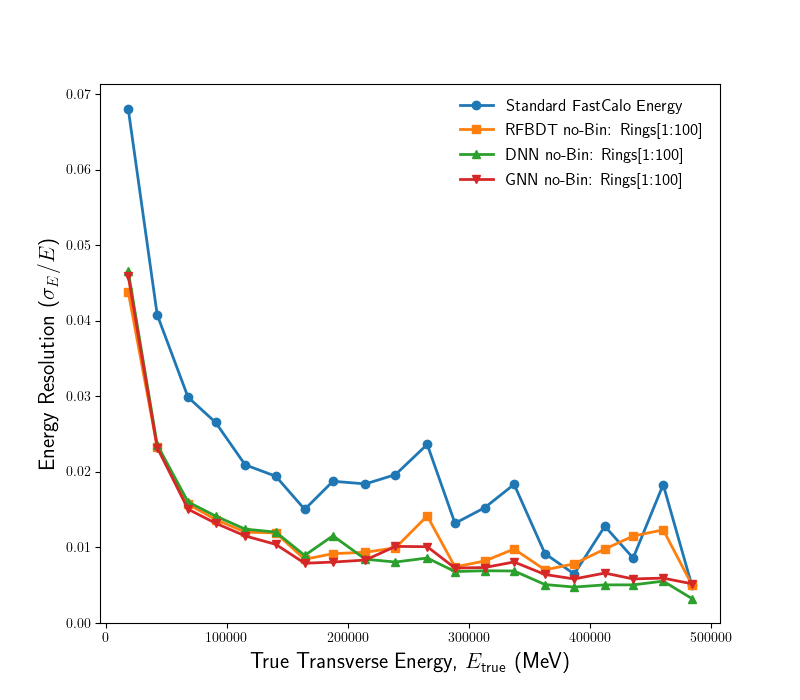

original_resolution_DNN_no-Bin__ICA-10_01.png


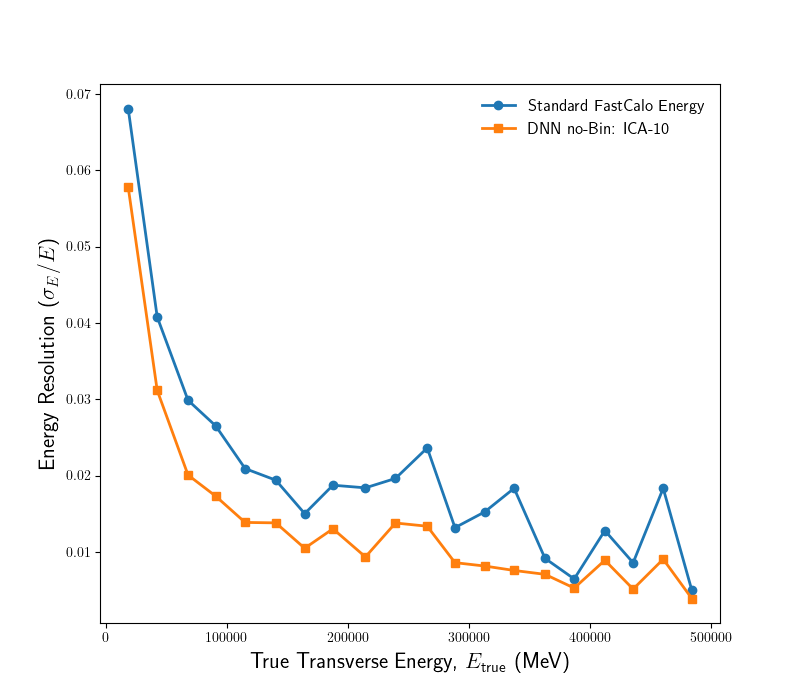

original_qq_DNN_no-Bin__ICA-10_01.png


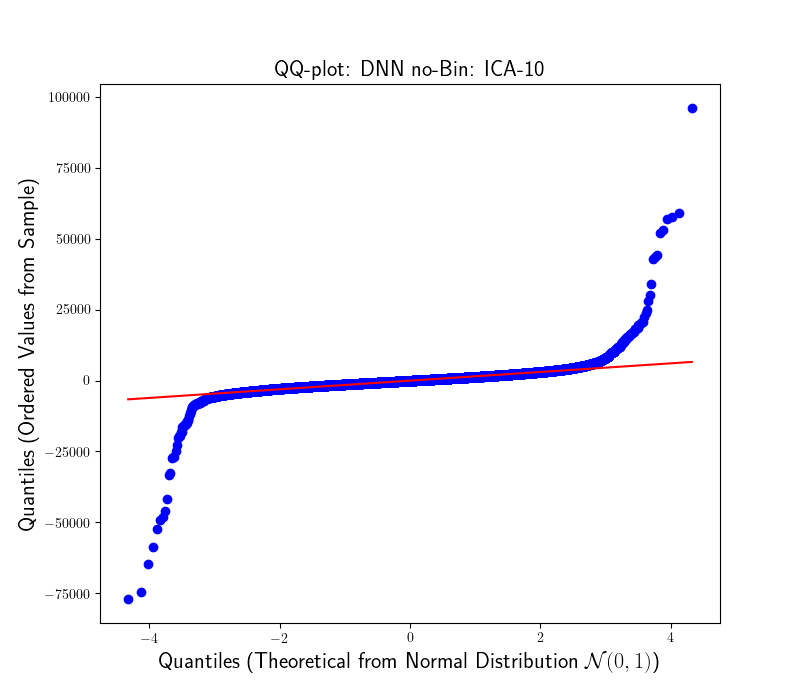

original_resolution_DNN_no-Bin__CORR-10_01.png


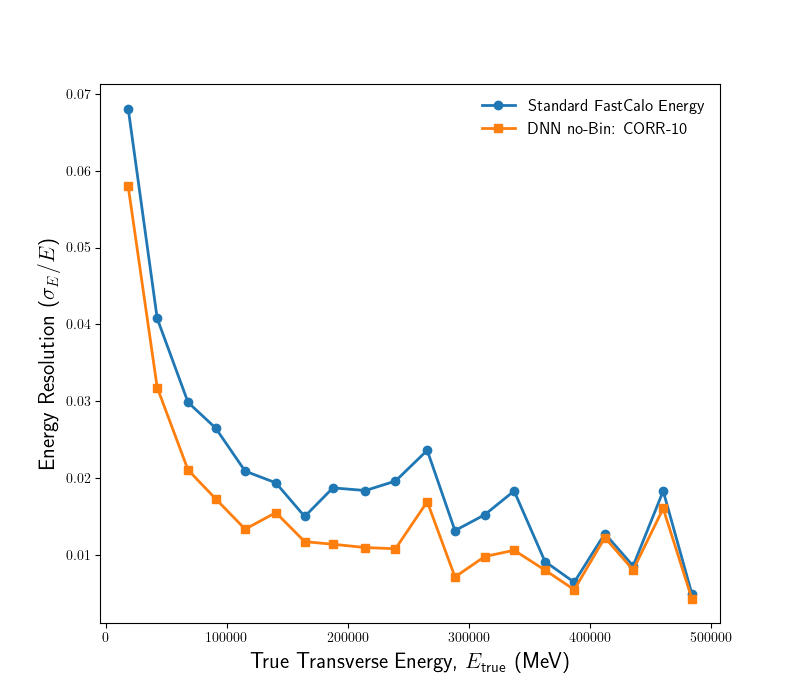

original_qq_DNN_no-Bin__CORR-10_01.png


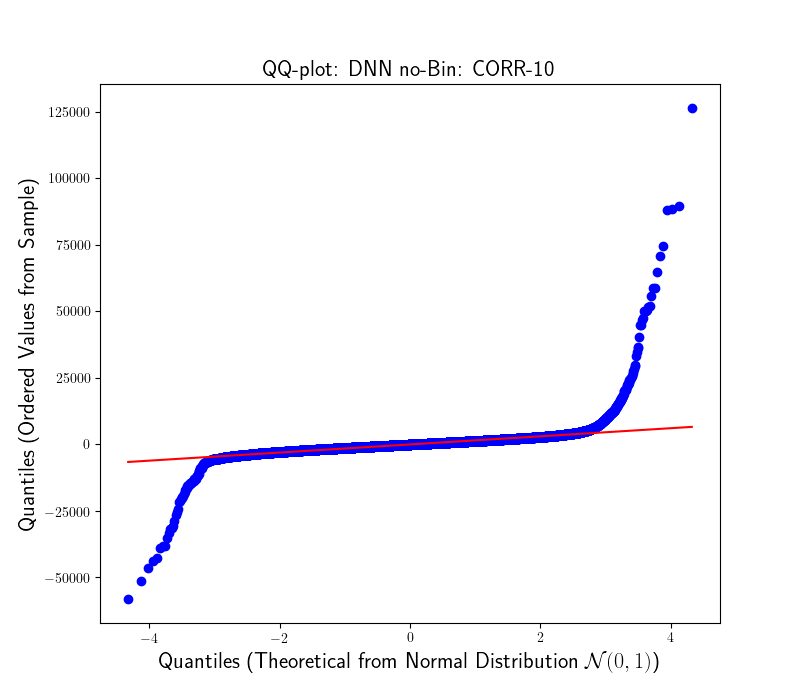

original_resolution_DNN_no-Bin__Rings_1_100__01.png


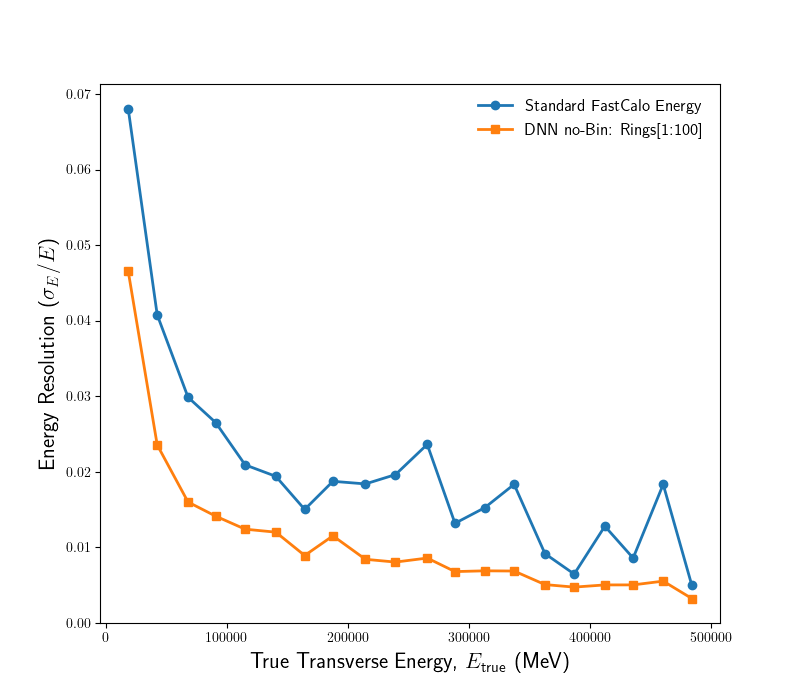

original_qq_DNN_no-Bin__Rings_1_100__01.png


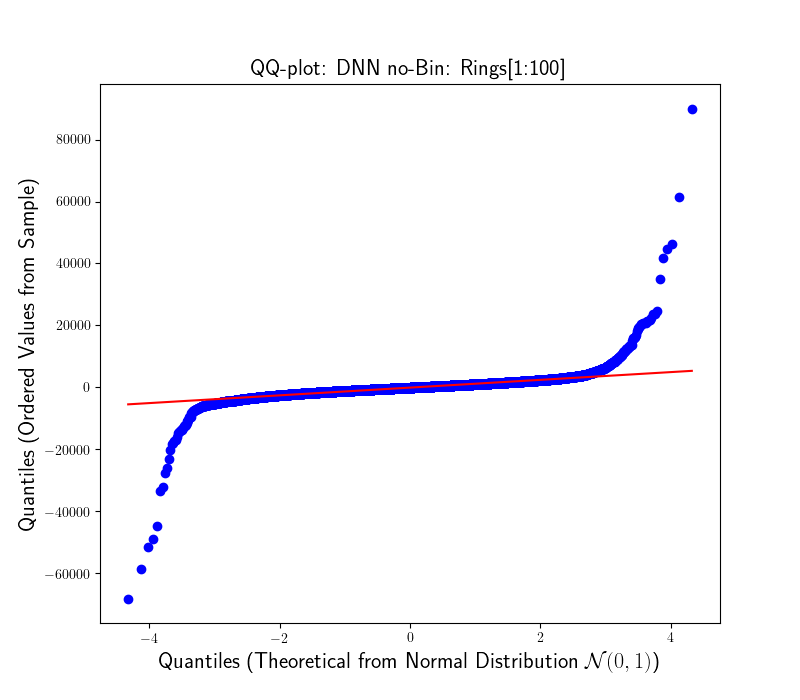

original_segmented_02.png


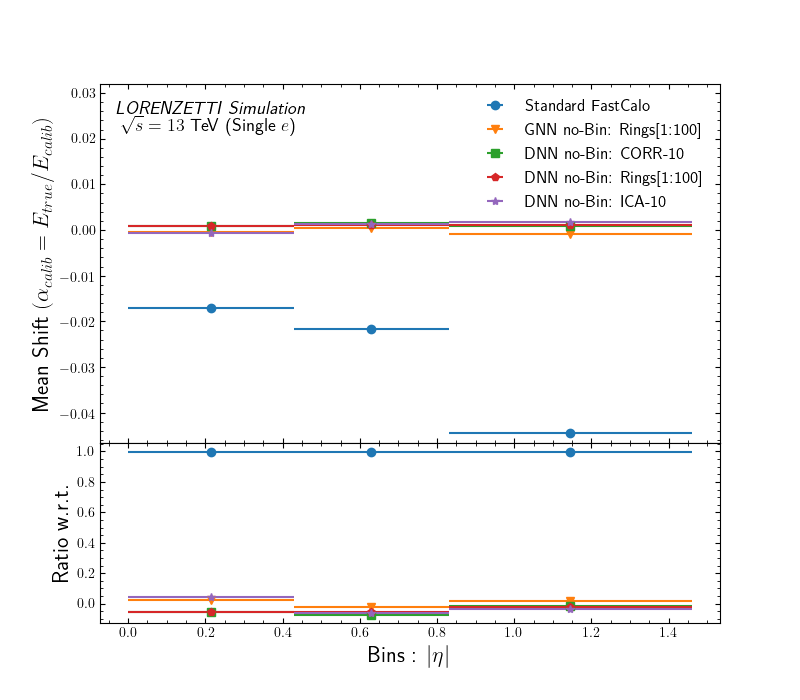

original_segmented_04.png


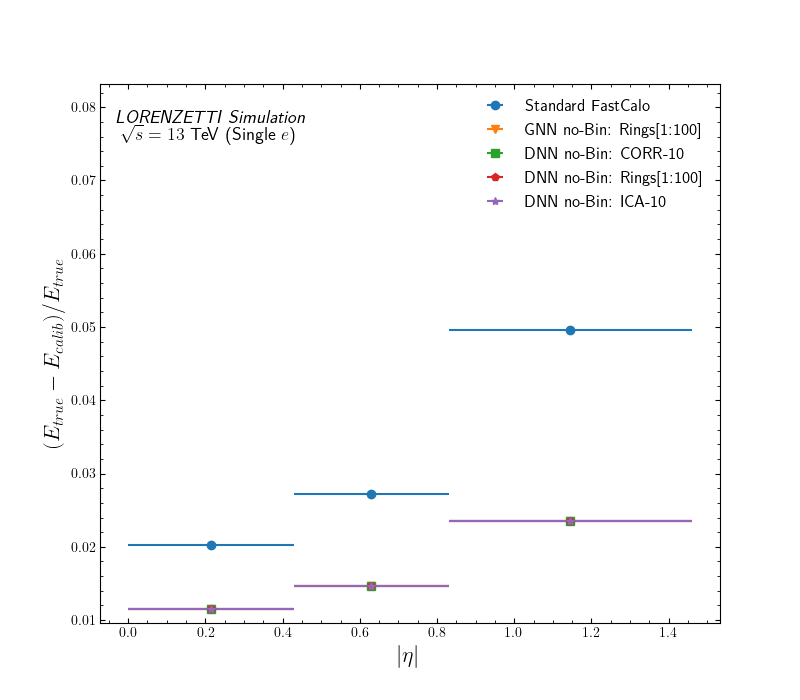

original_segmented_05.png


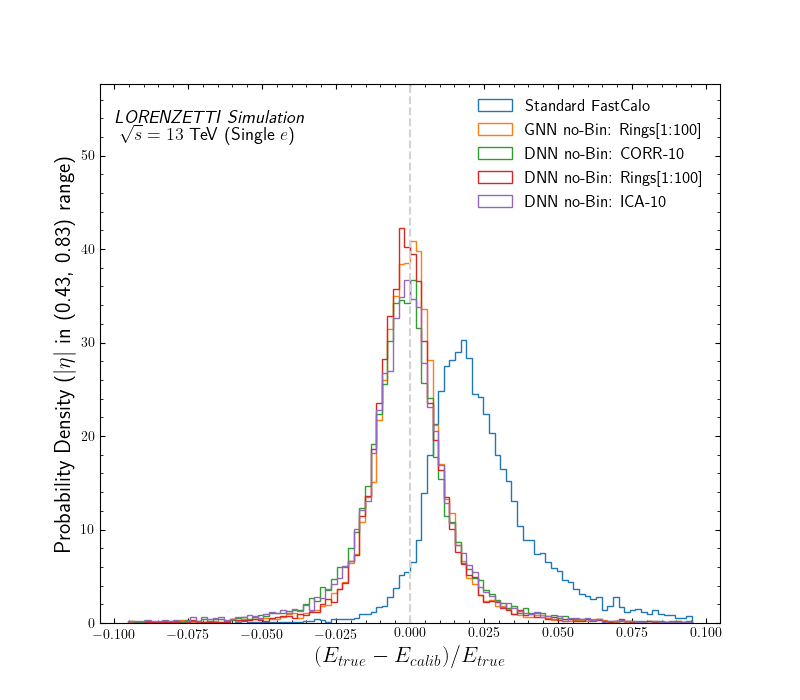

original_segmented_06.png


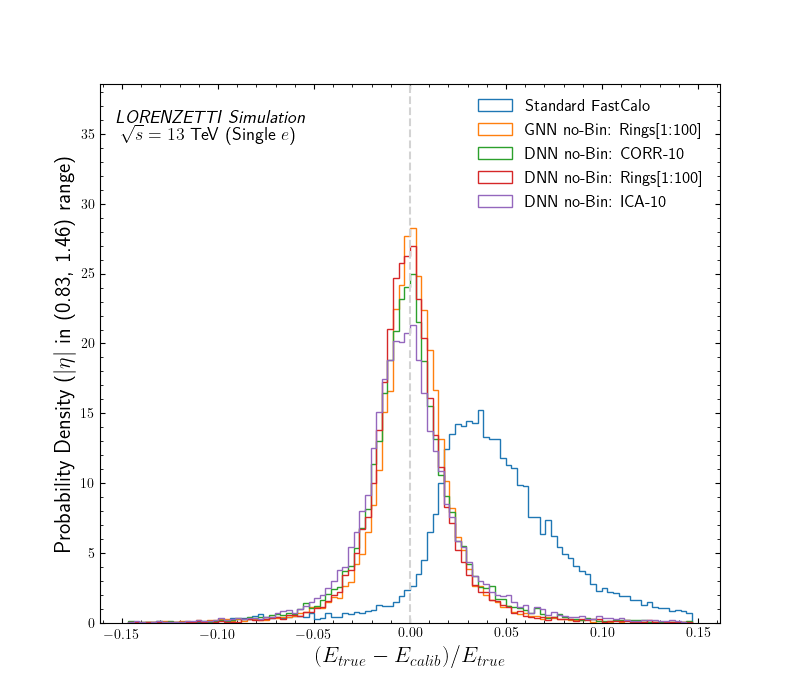

original_segmented_07.png


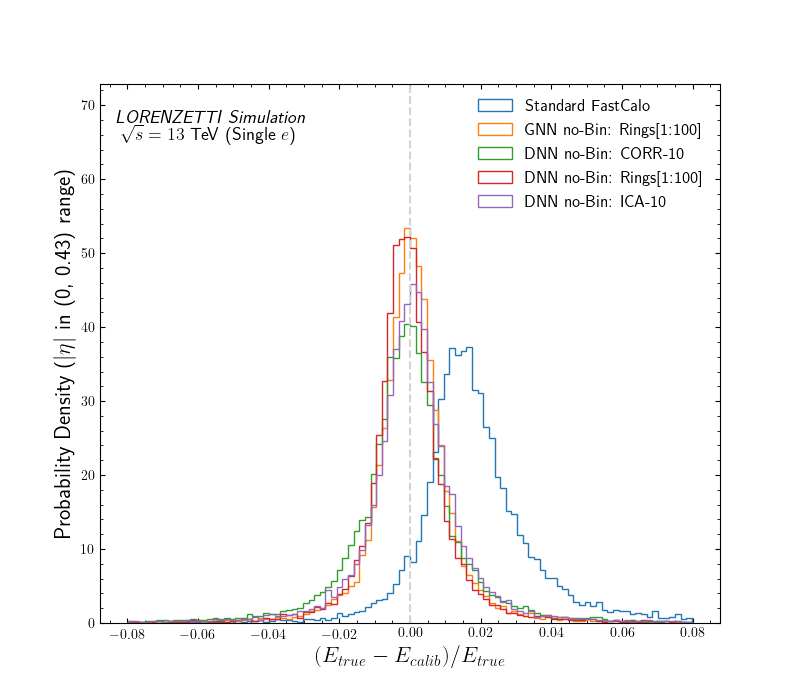

original_segmented_09.png


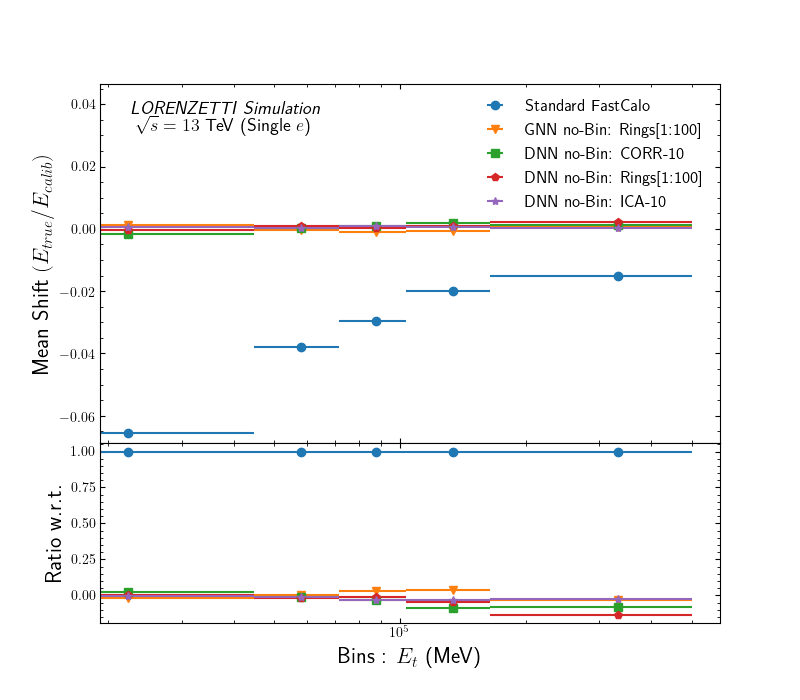

original_segmented_11.png


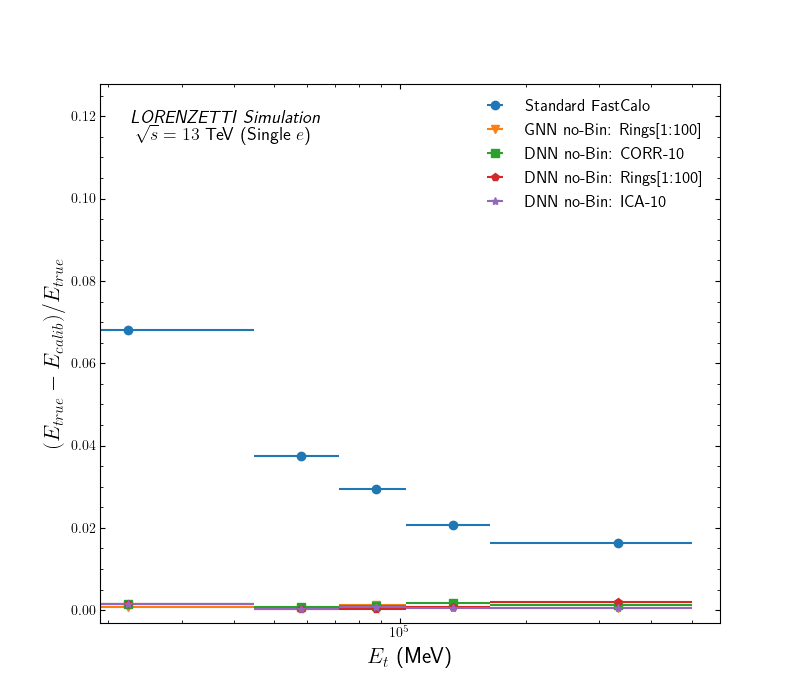

original_segmented_12.png


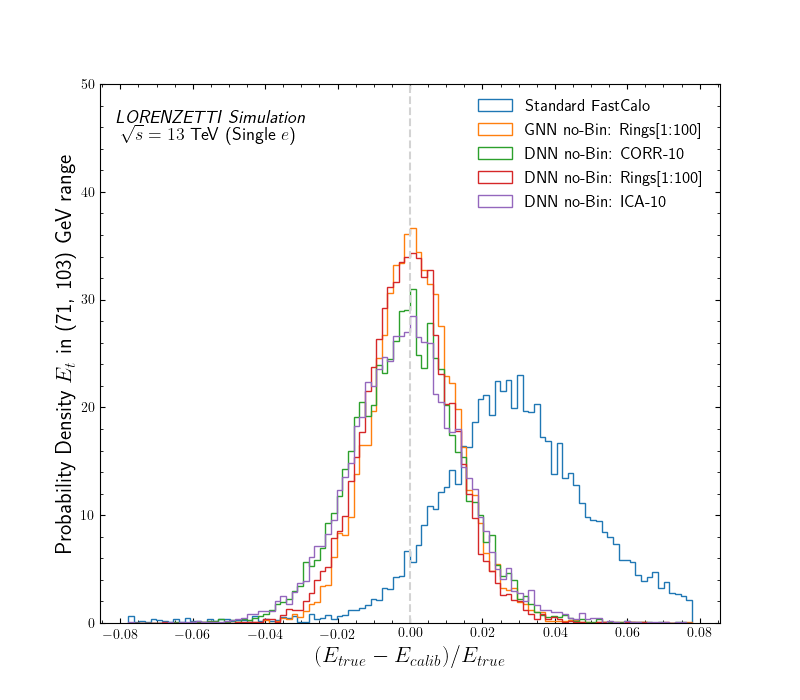

original_segmented_13.png


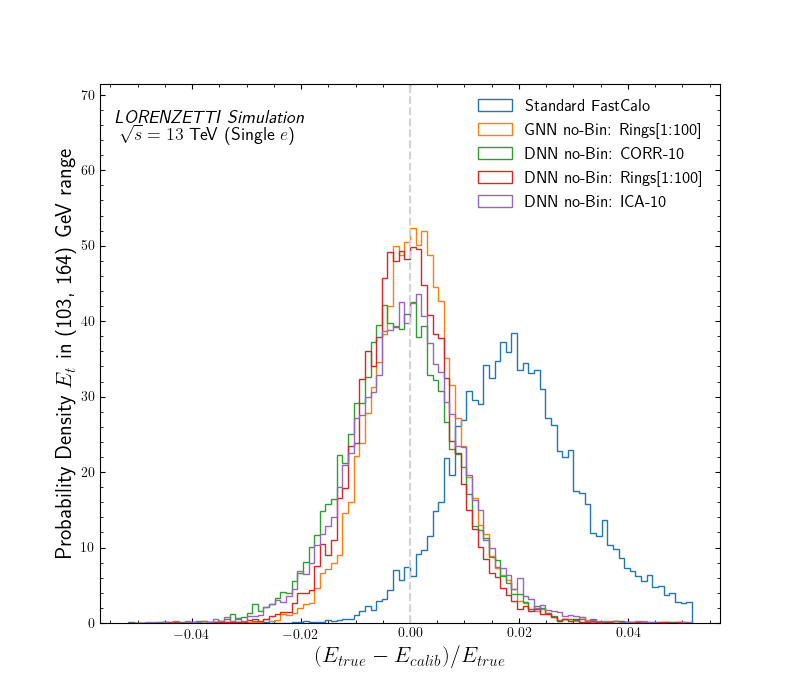

original_segmented_14.png


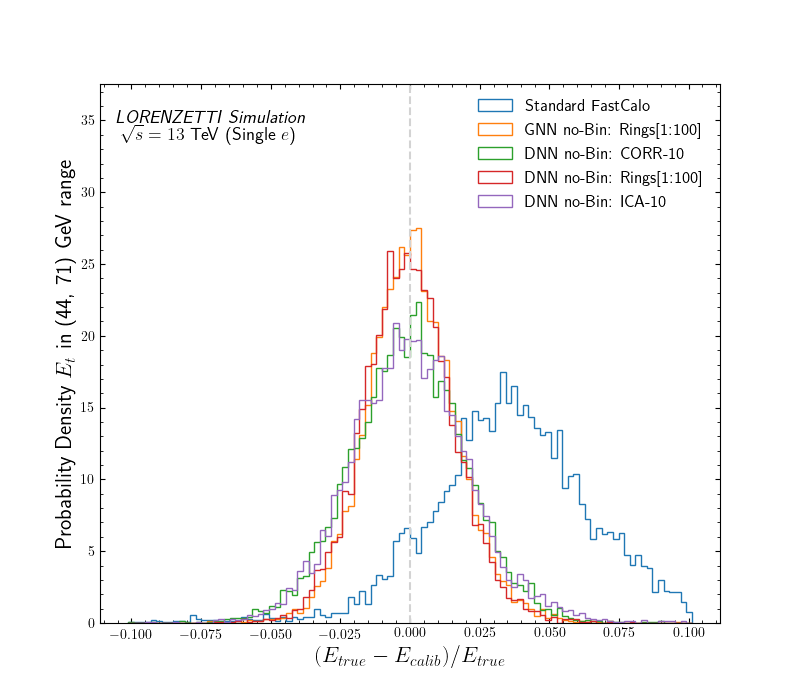

original_segmented_15.png


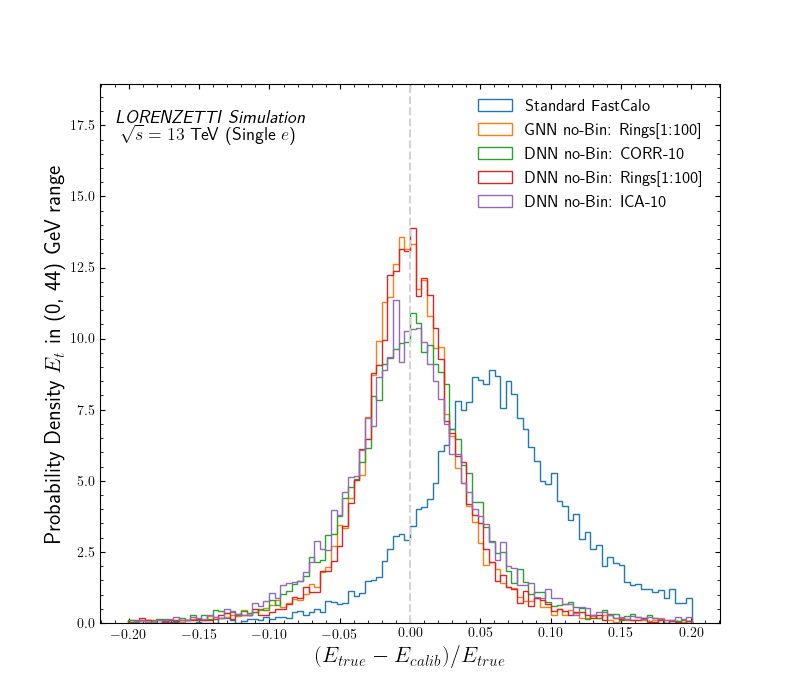

original_segmented_16.png


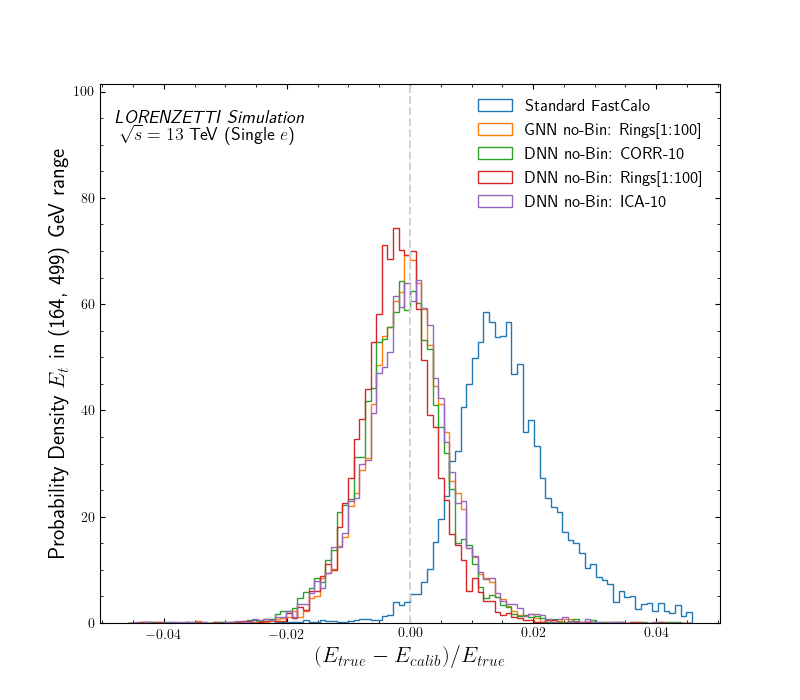

original_segmented_17.png


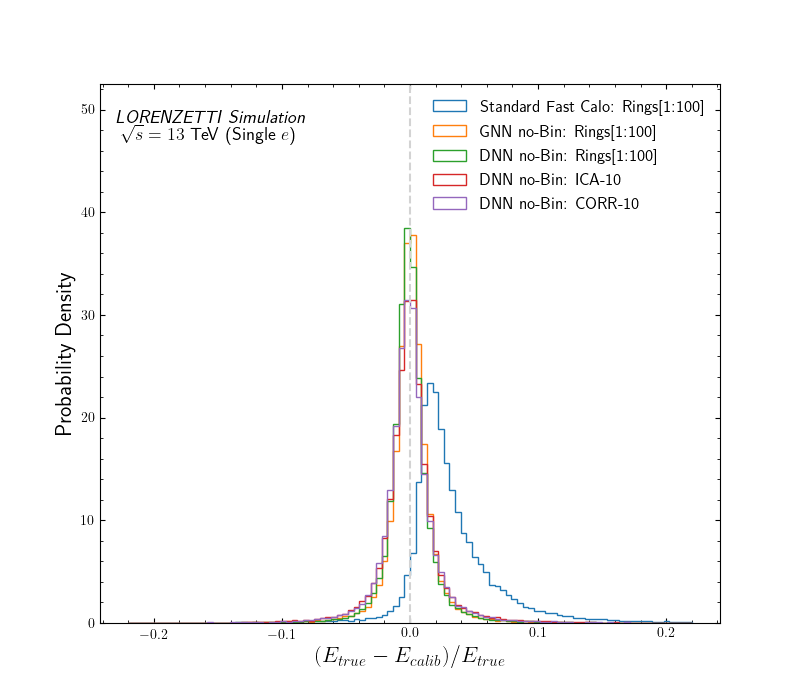

original_segmented_18.png


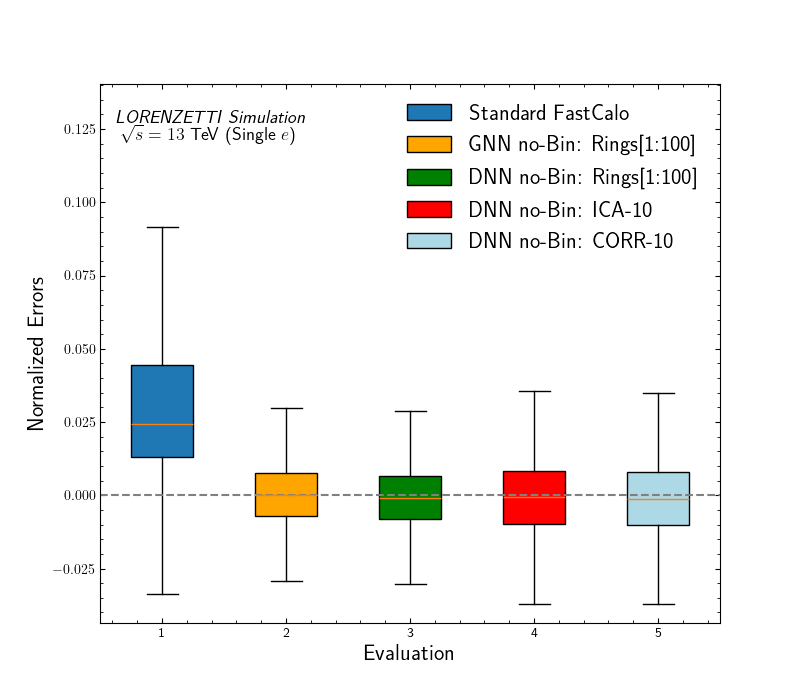

original_top10_residual_hist_box_01.png


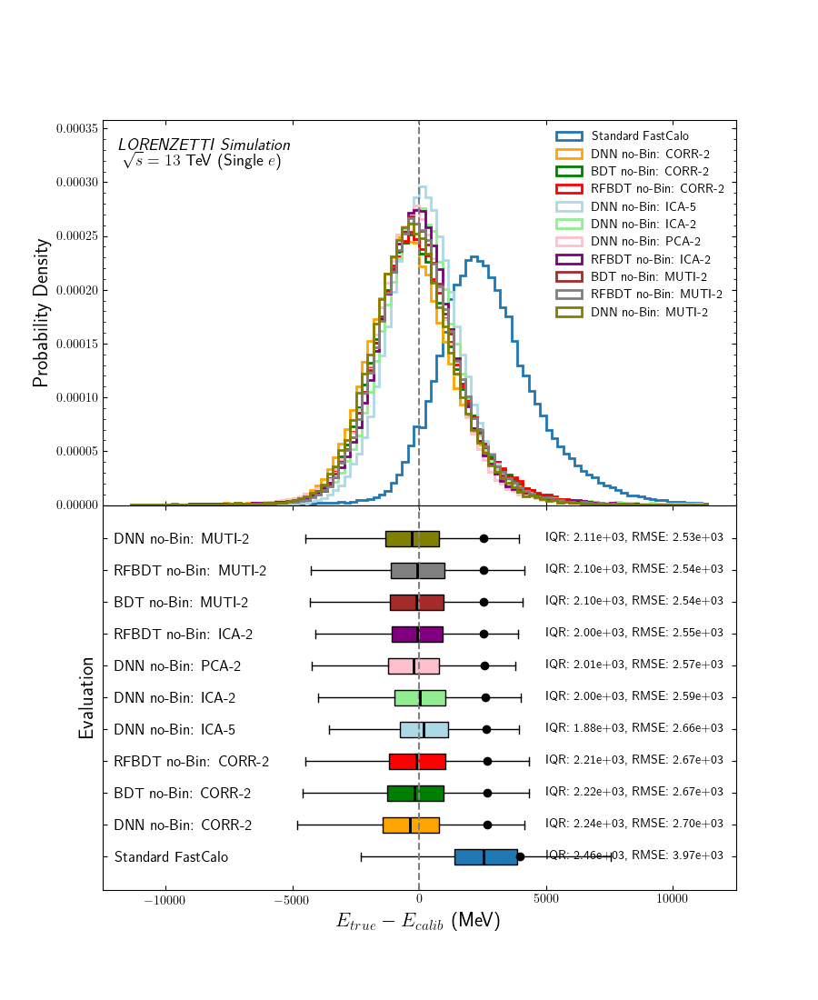

original_top10_boxplot_01.png


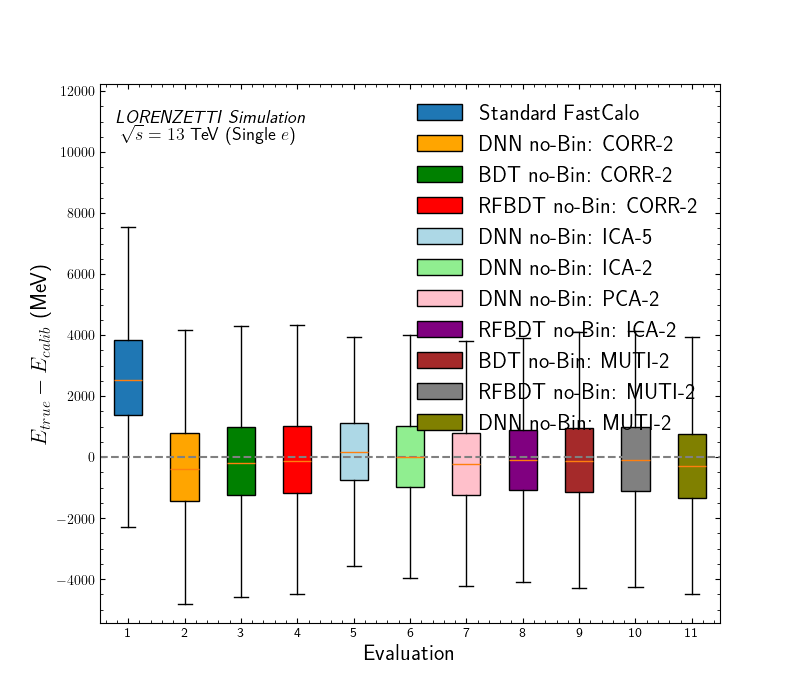

original_resolution_errorbars_01.png


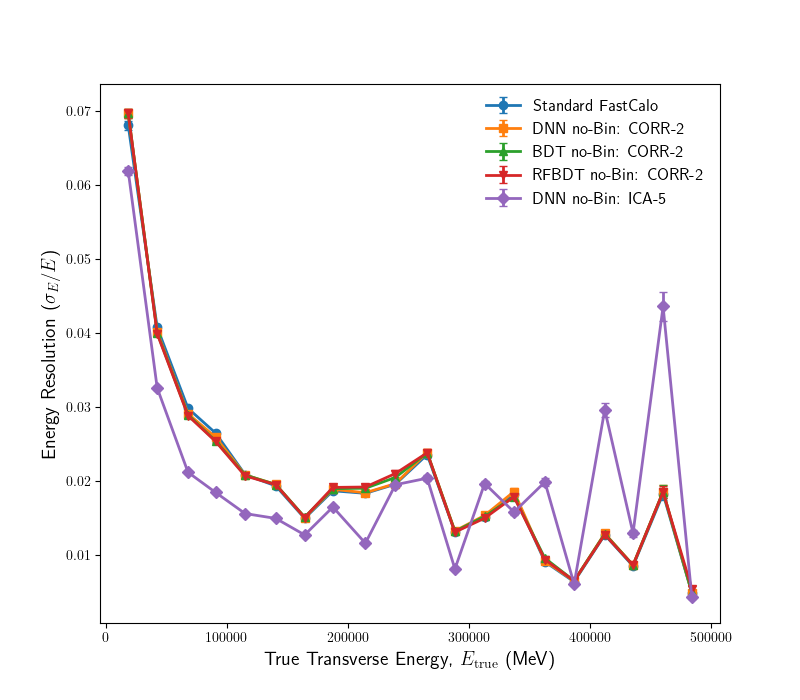

original_ranked_histogram_01.png


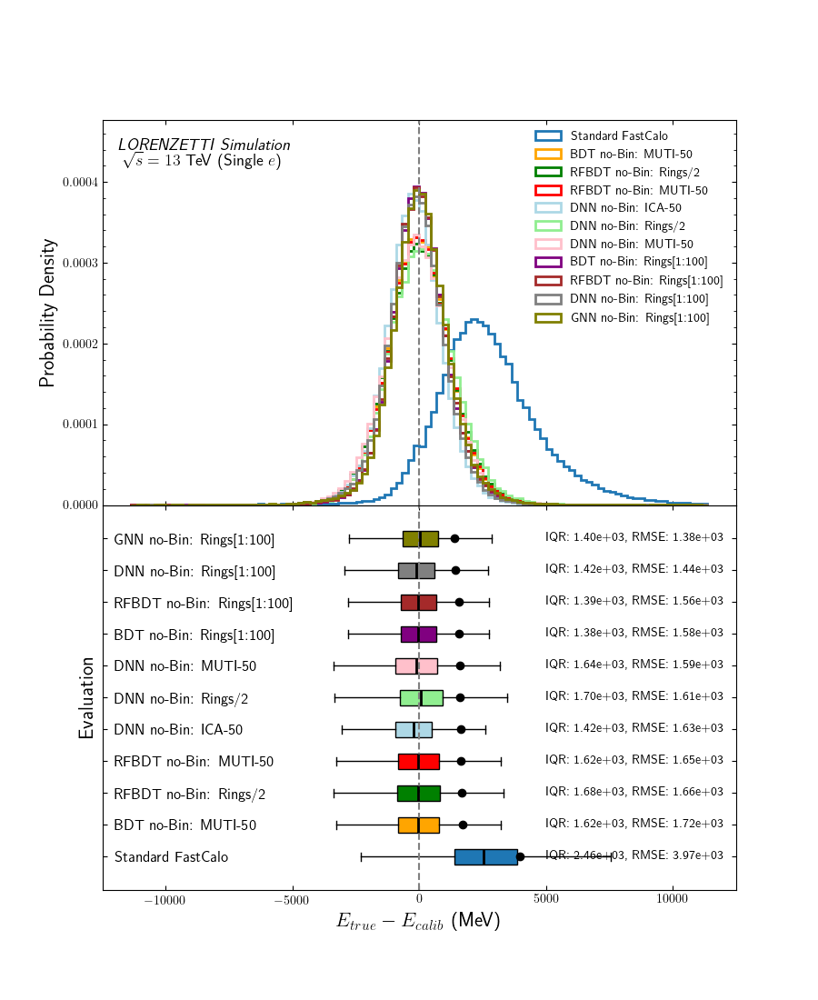

original_D0_ranked_d0_01.png


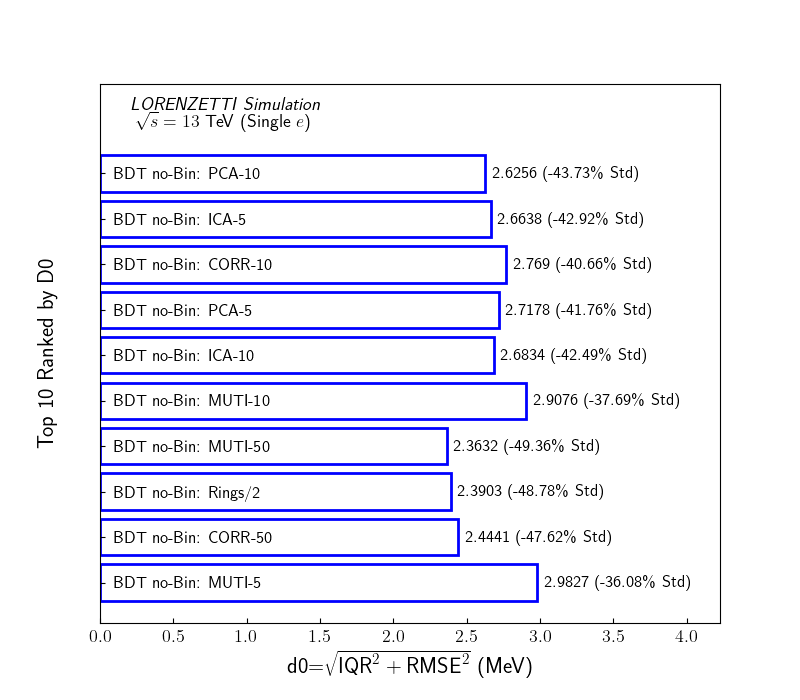

original_all_d0_comparison_01.png


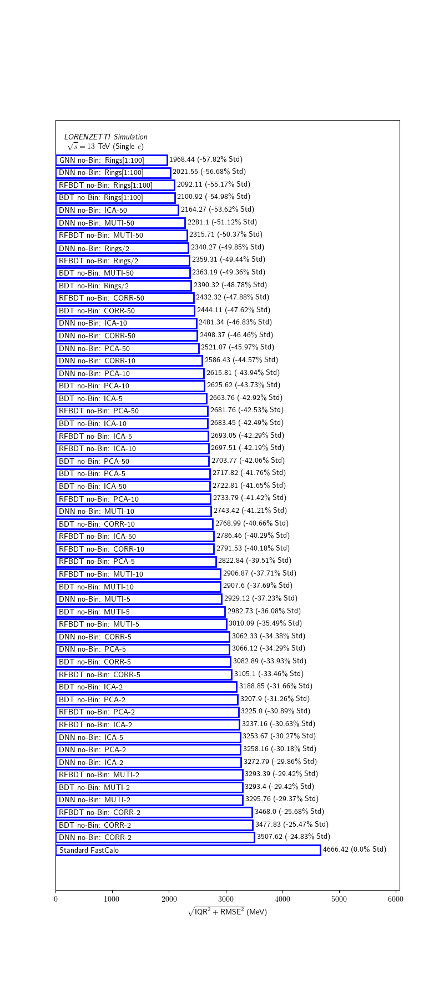

original_all_prediction_times_01.png


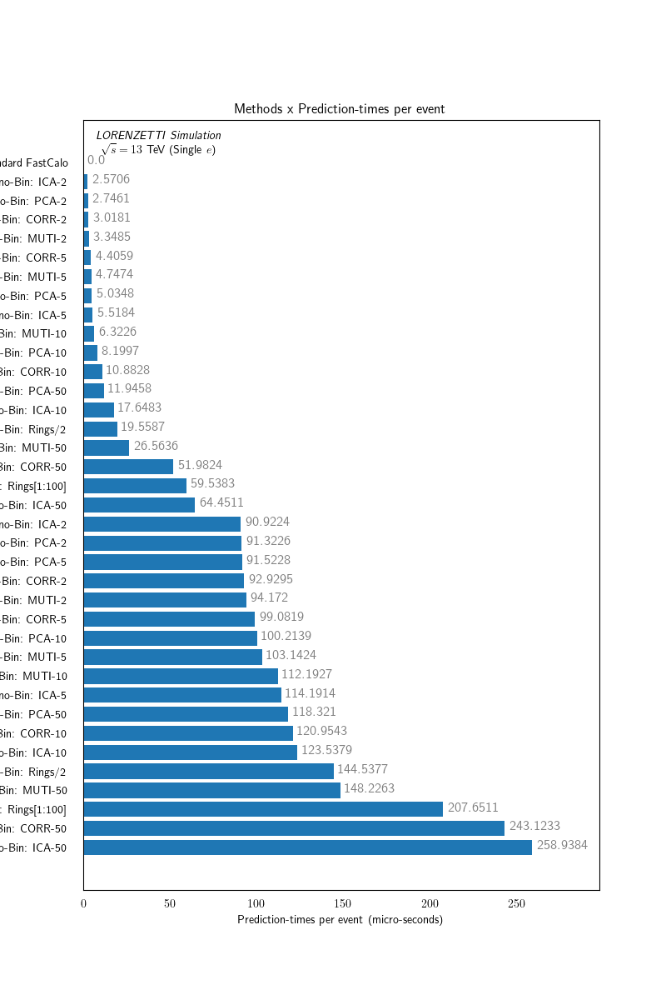

comparison_metric_cell702_01.png


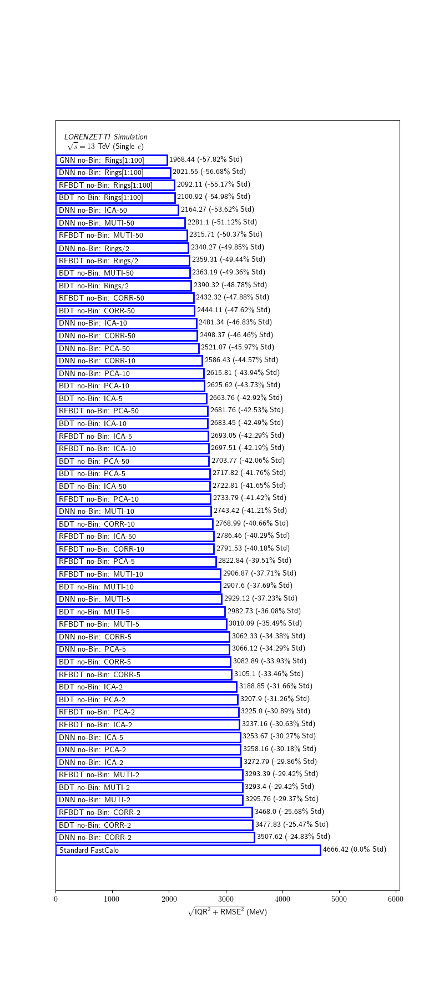

comparison_metric_all_cell705_01.png


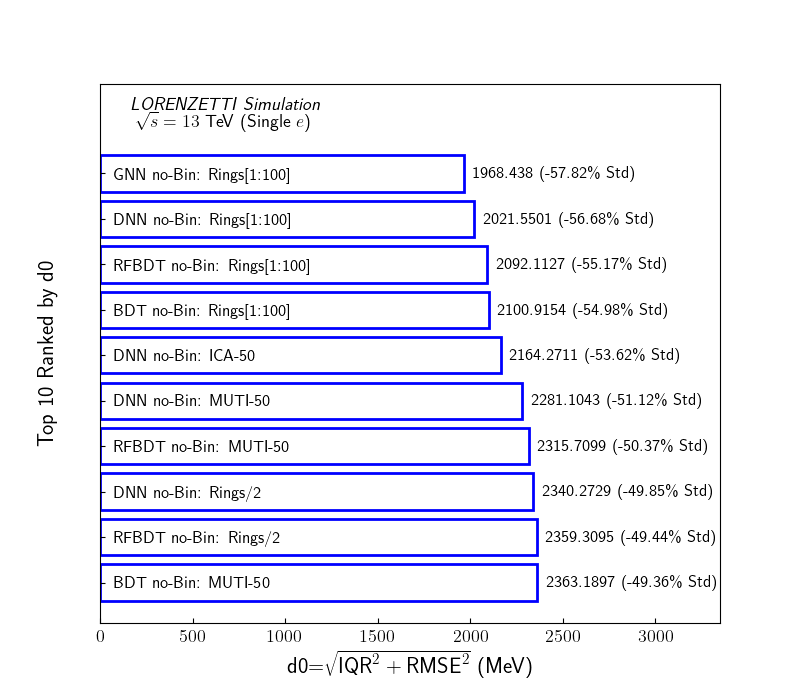

top_ten_residuals_cell749_01.png


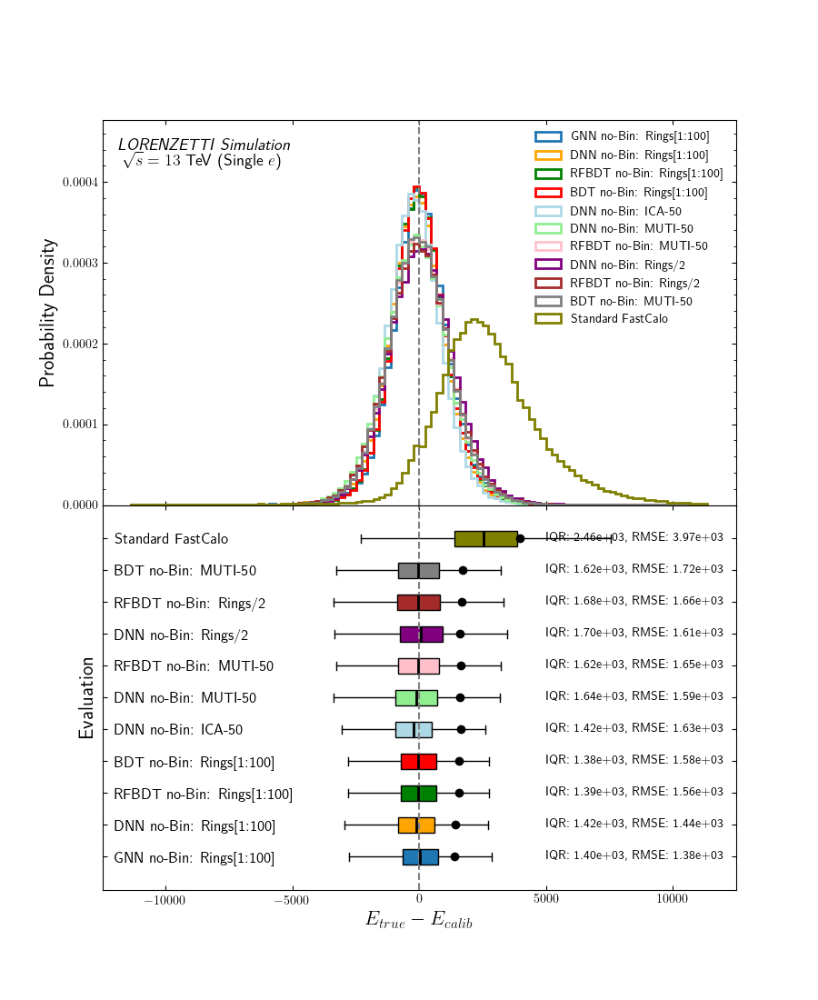

rmse_iqr_quadrant_cell767_01.png


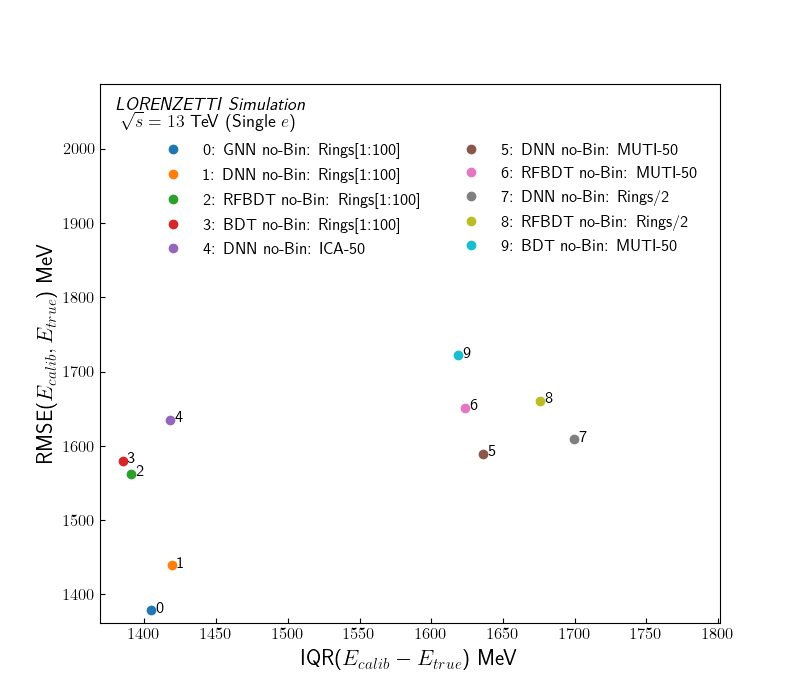

comparison_by_representation_CORR_10_01.png


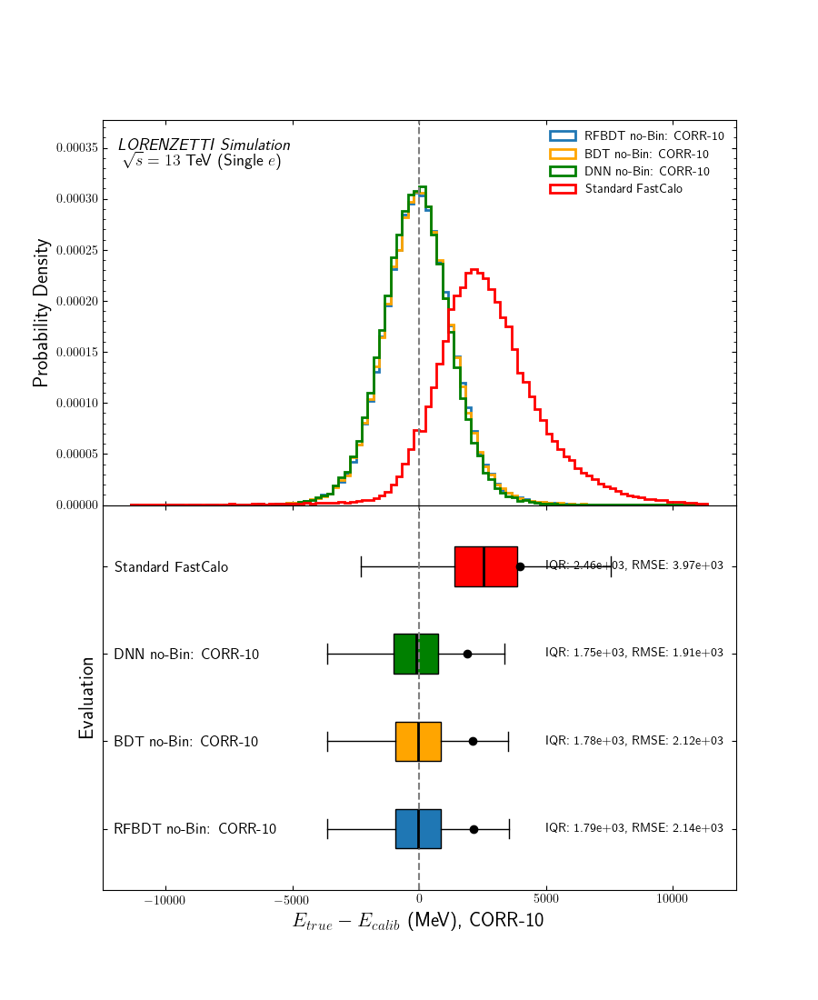

comparison_by_representation_CORR_2_01.png


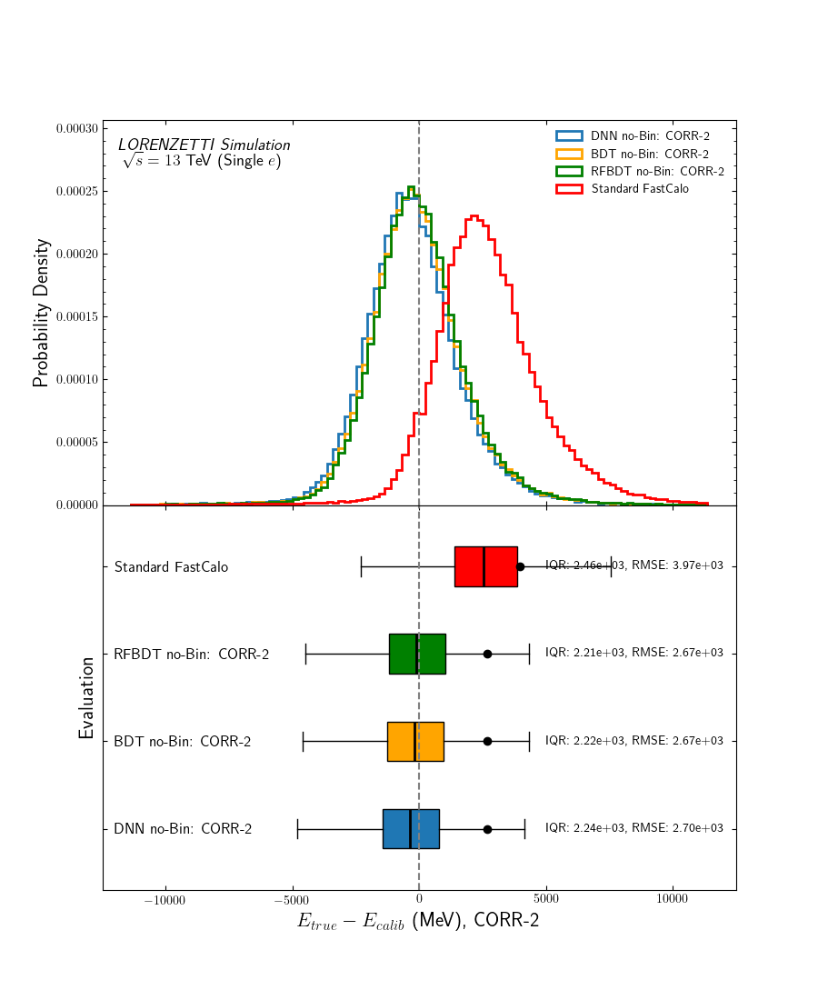

comparison_by_representation_CORR_5_01.png


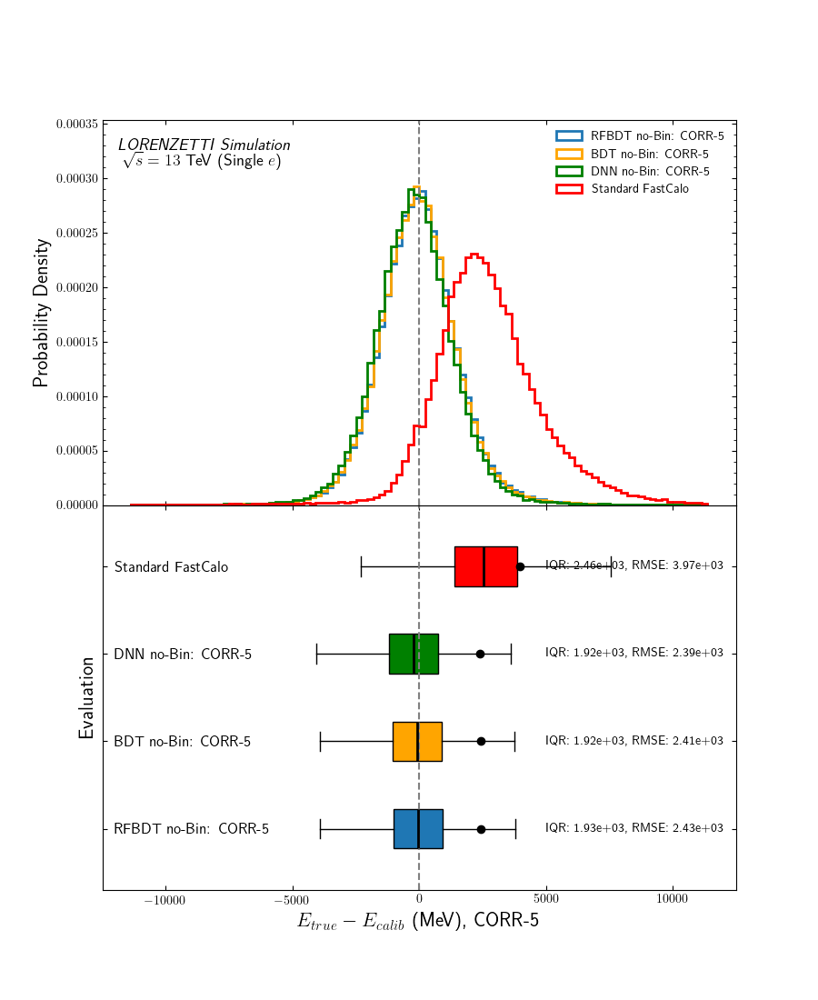

comparison_by_representation_CORR_50_01.png


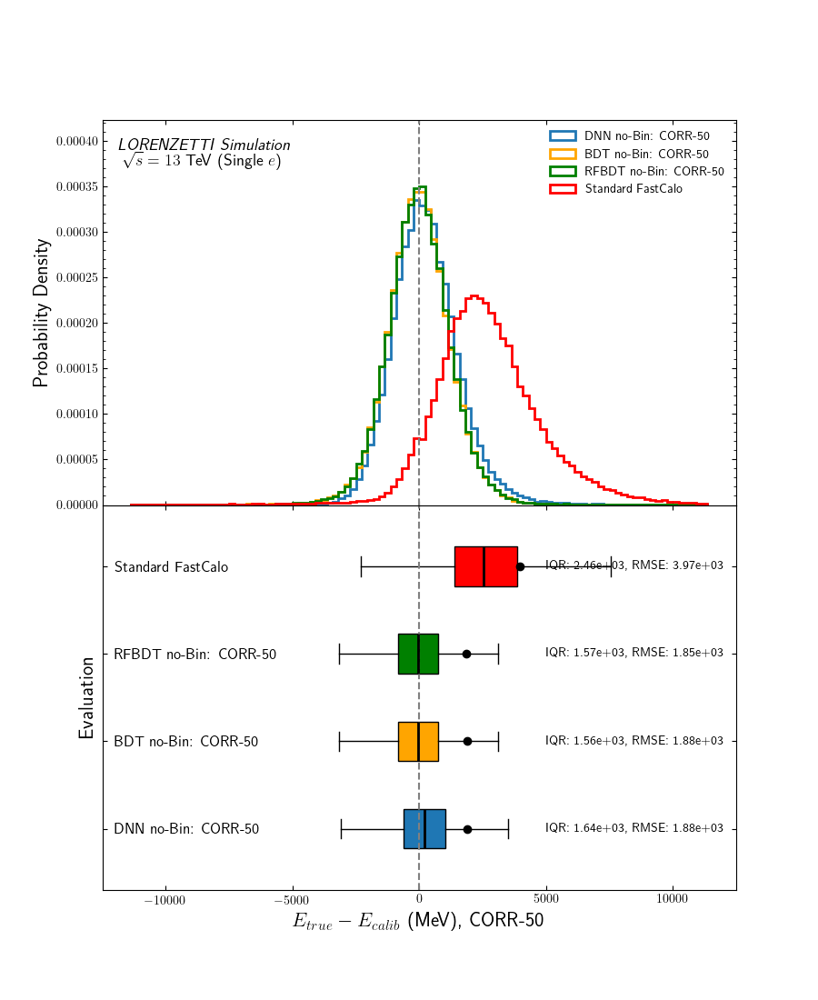

comparison_by_representation_ICA_10_01.png


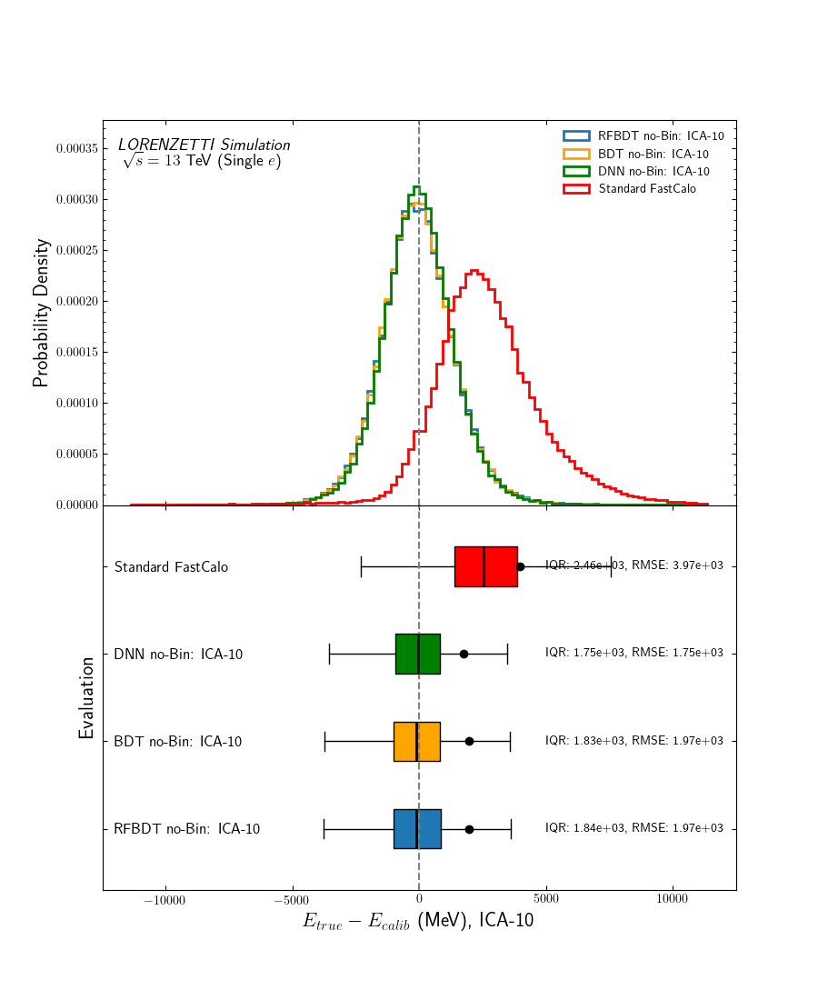

comparison_by_representation_ICA_2_01.png


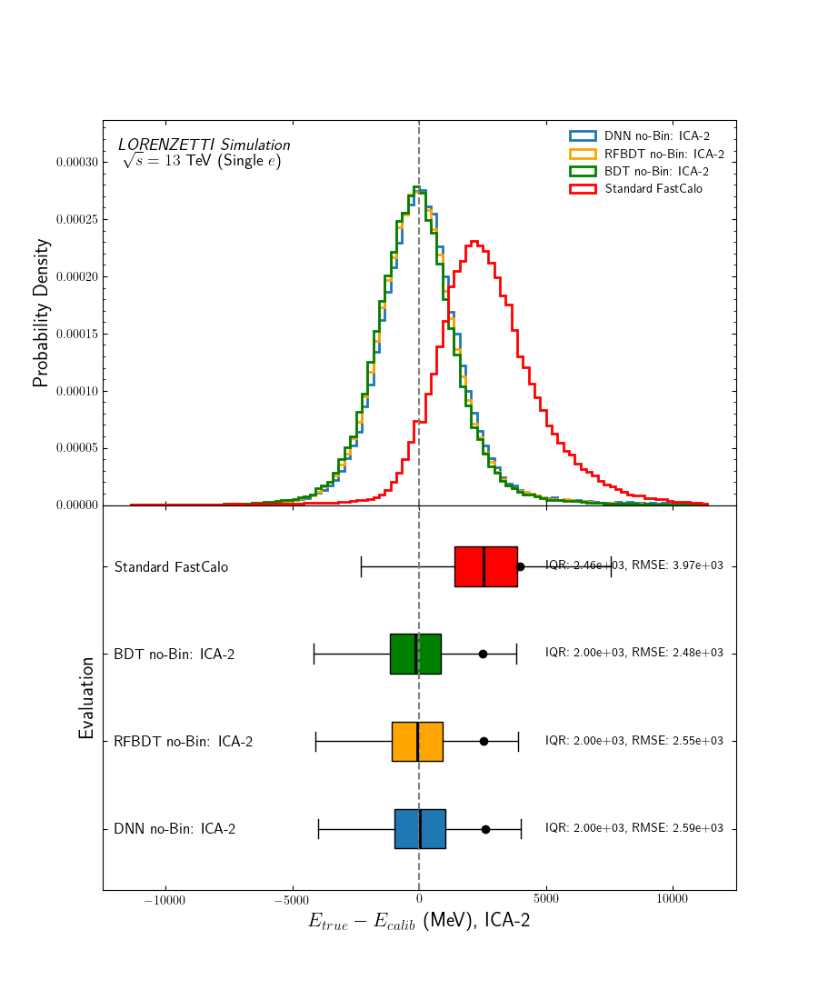

comparison_by_representation_ICA_5_01.png


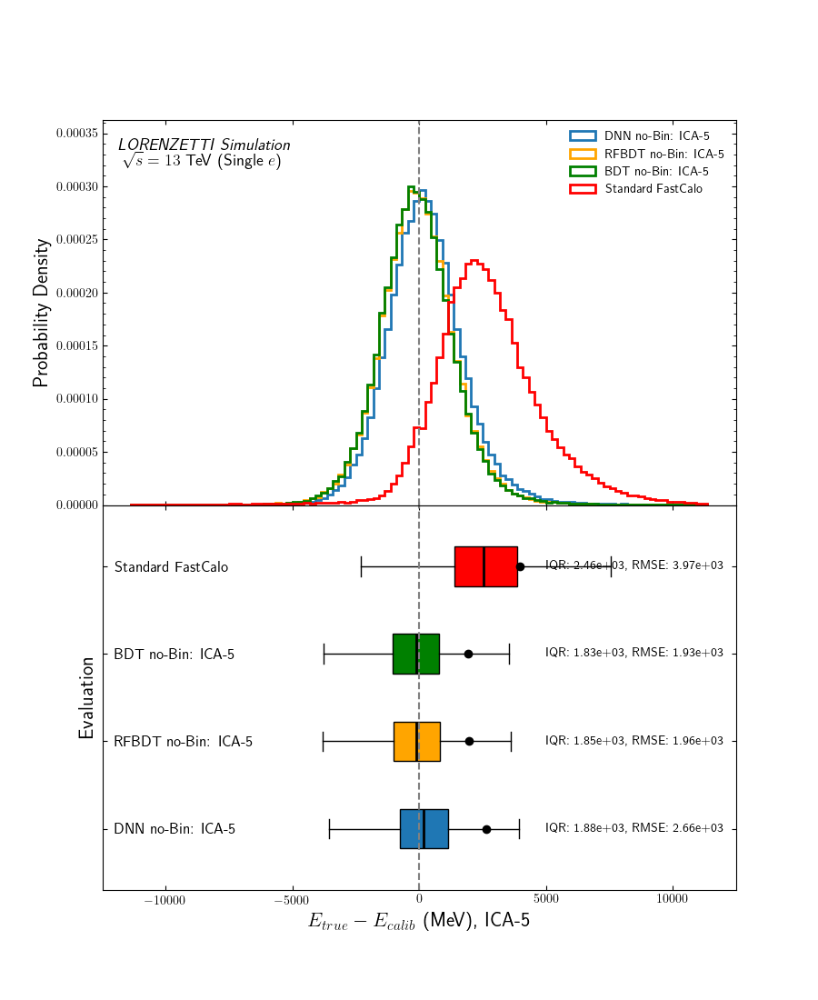

comparison_by_representation_ICA_50_01.png


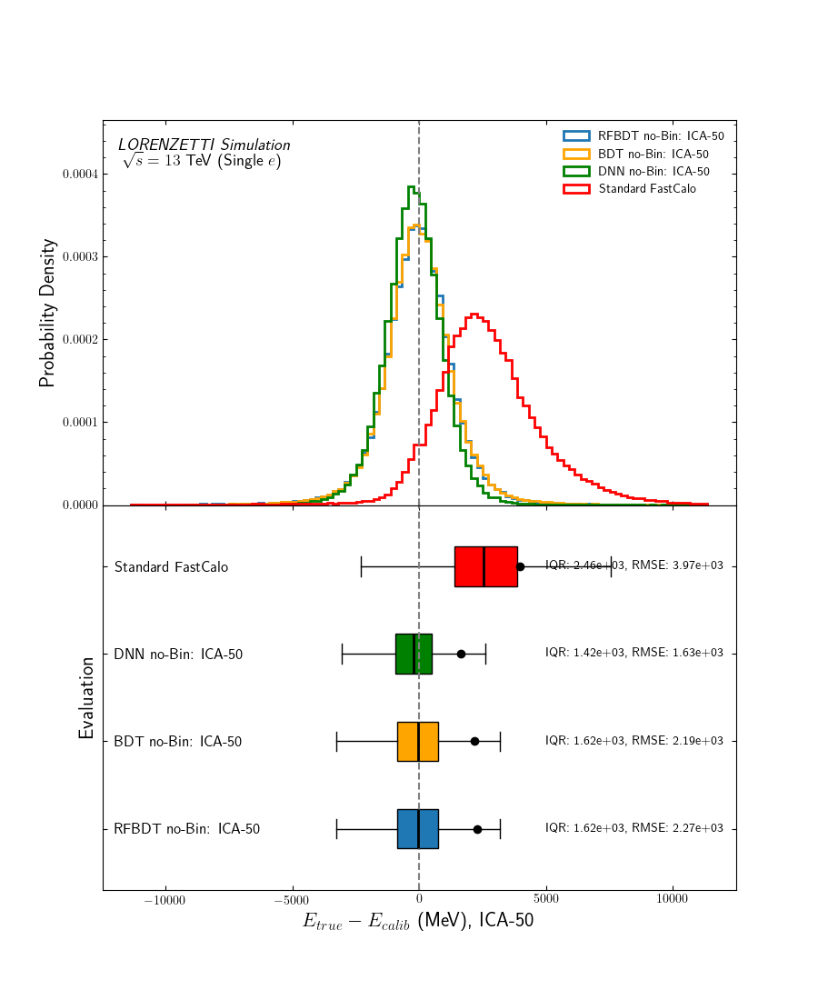

comparison_by_representation_MUTI_10_01.png


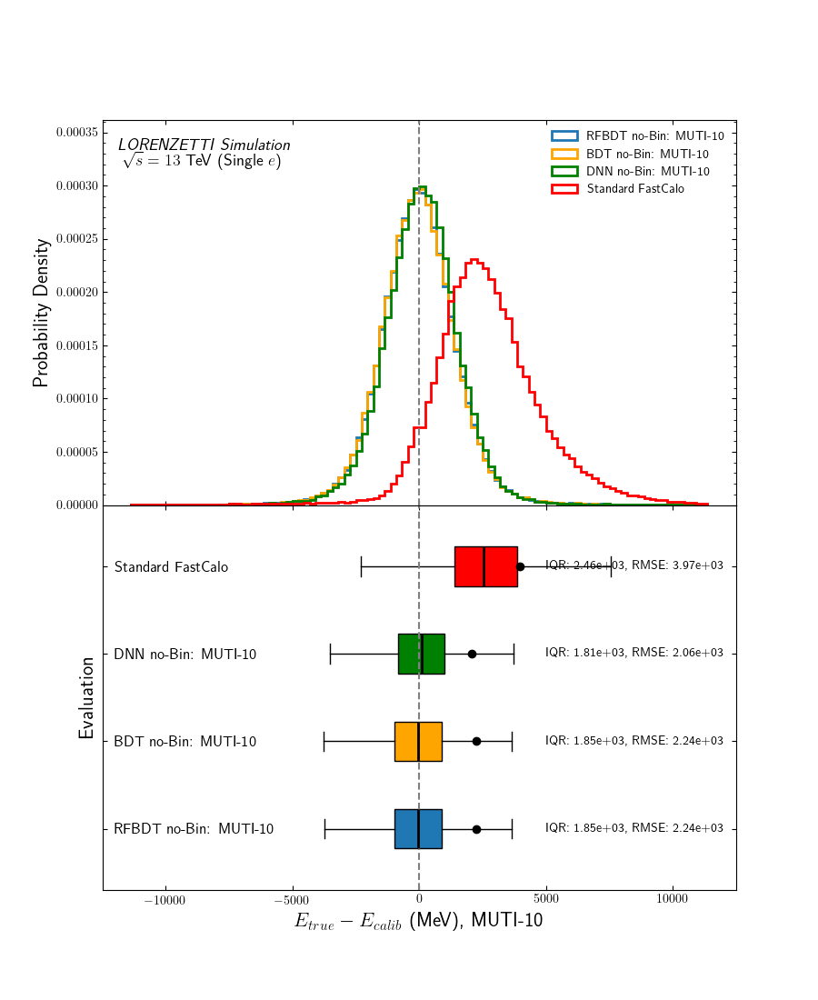

comparison_by_representation_MUTI_2_01.png


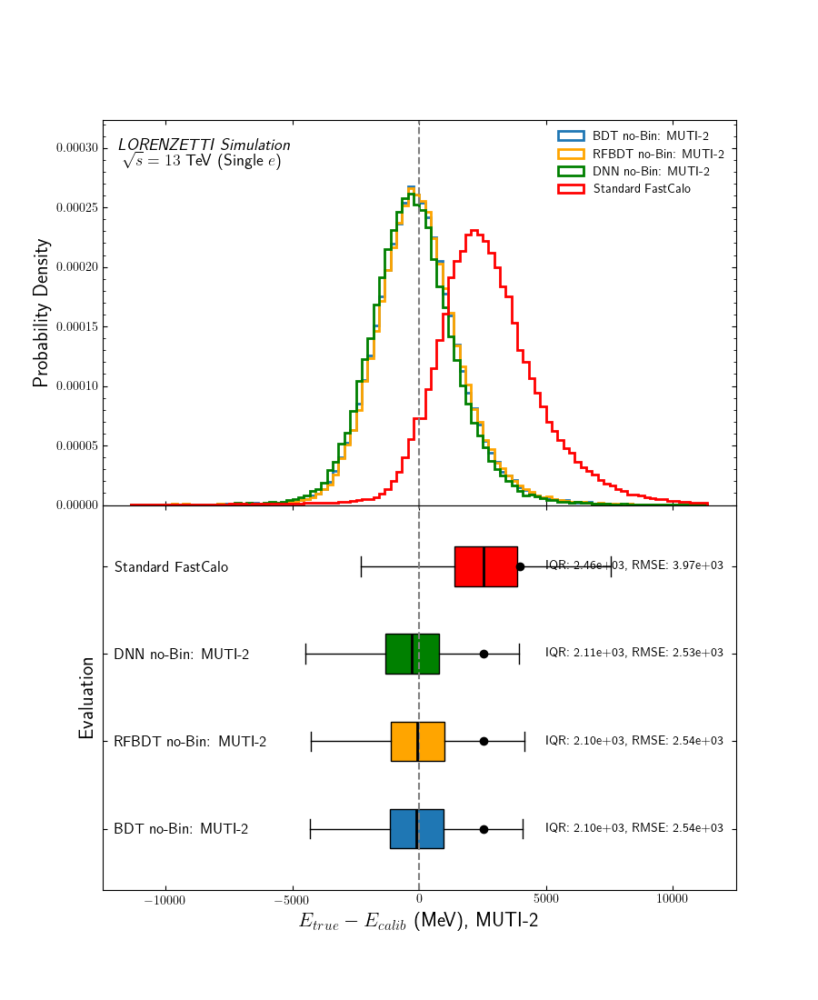

comparison_by_representation_MUTI_5_01.png


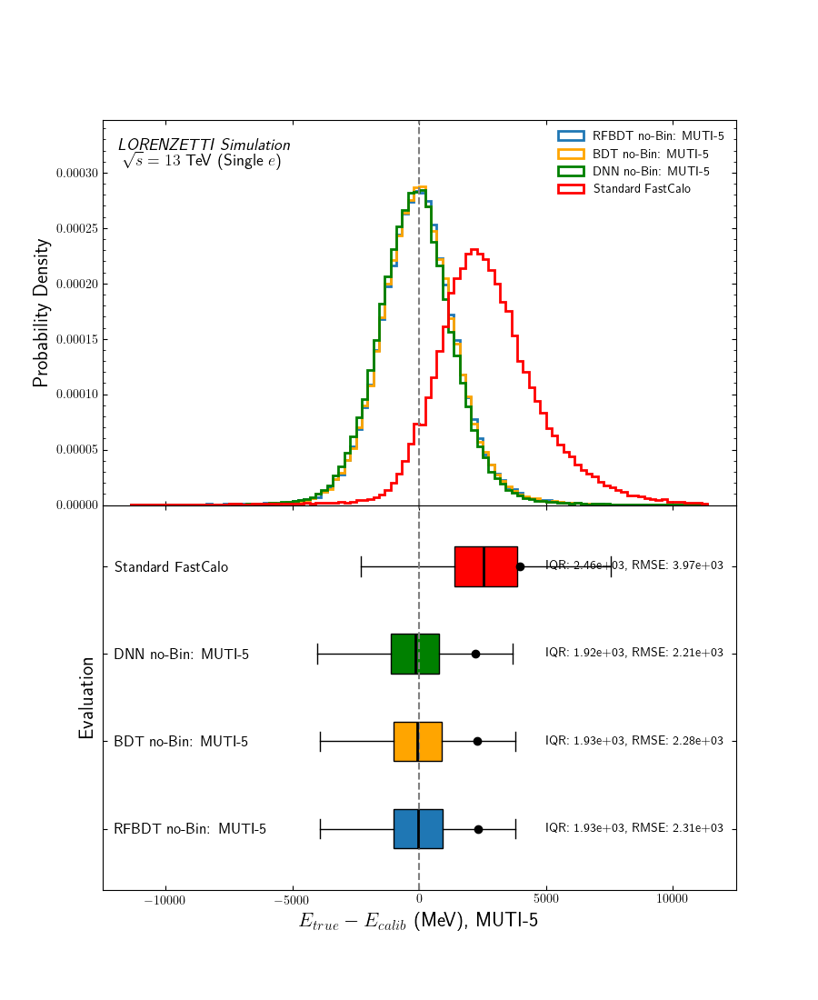

comparison_by_representation_MUTI_50_01.png


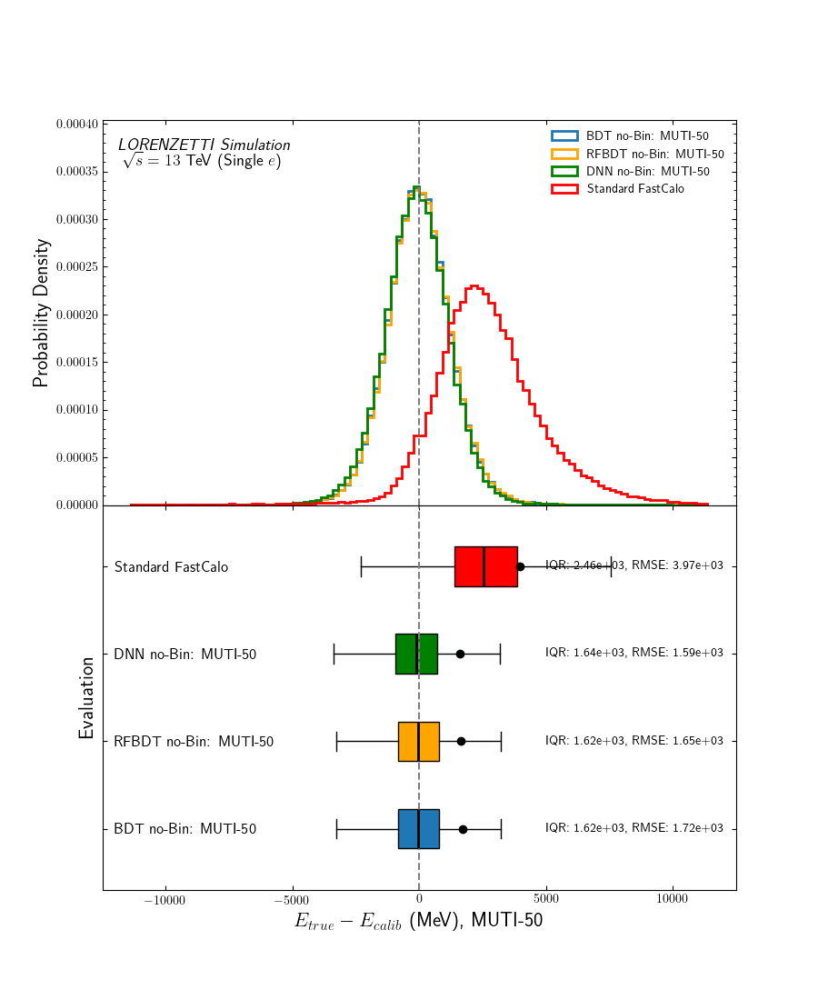

comparison_by_representation_PCA_10_01.png


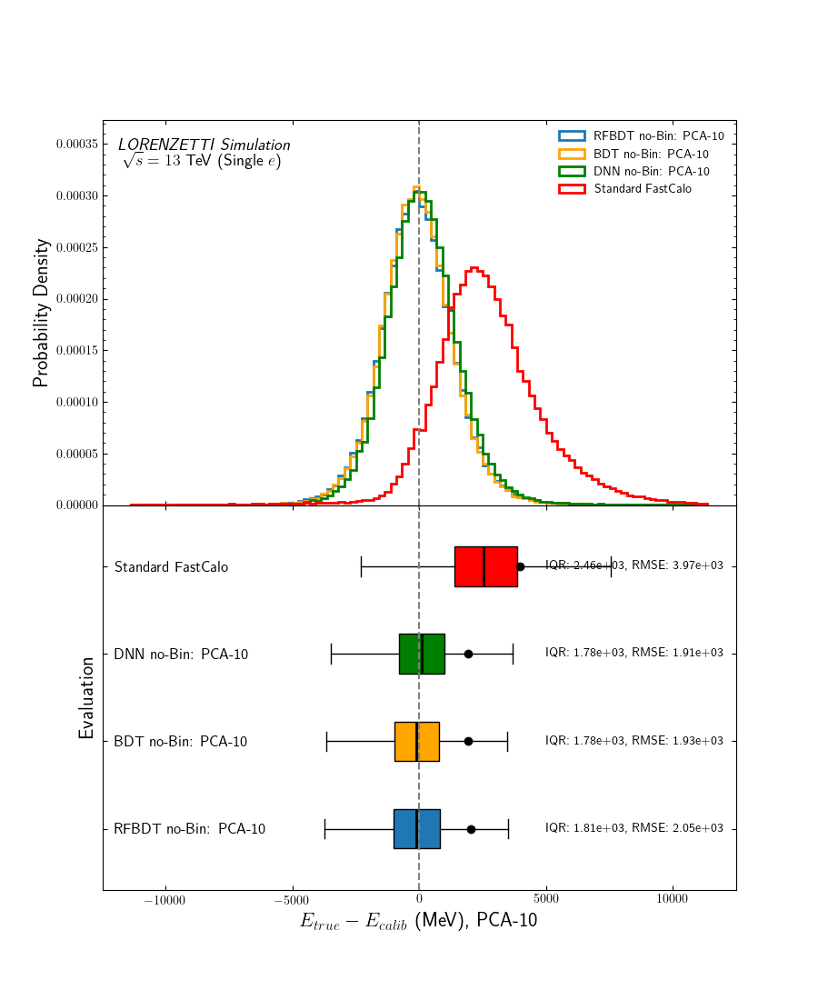

comparison_by_representation_PCA_2_01.png


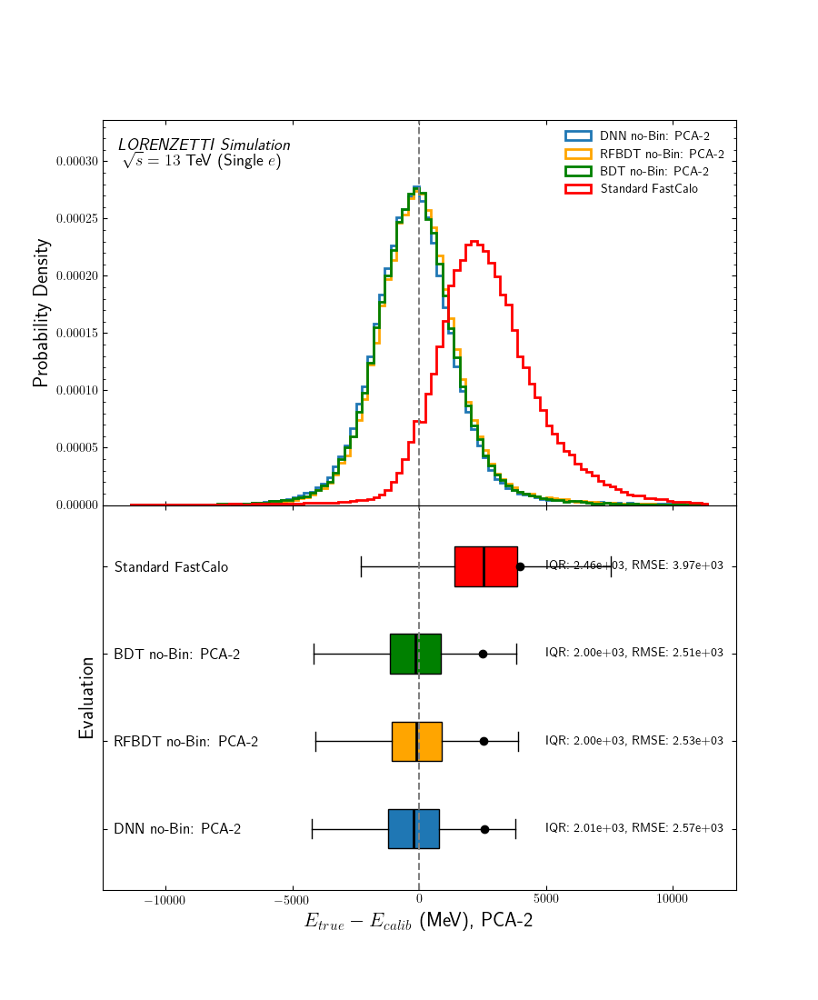

comparison_by_representation_PCA_5_01.png


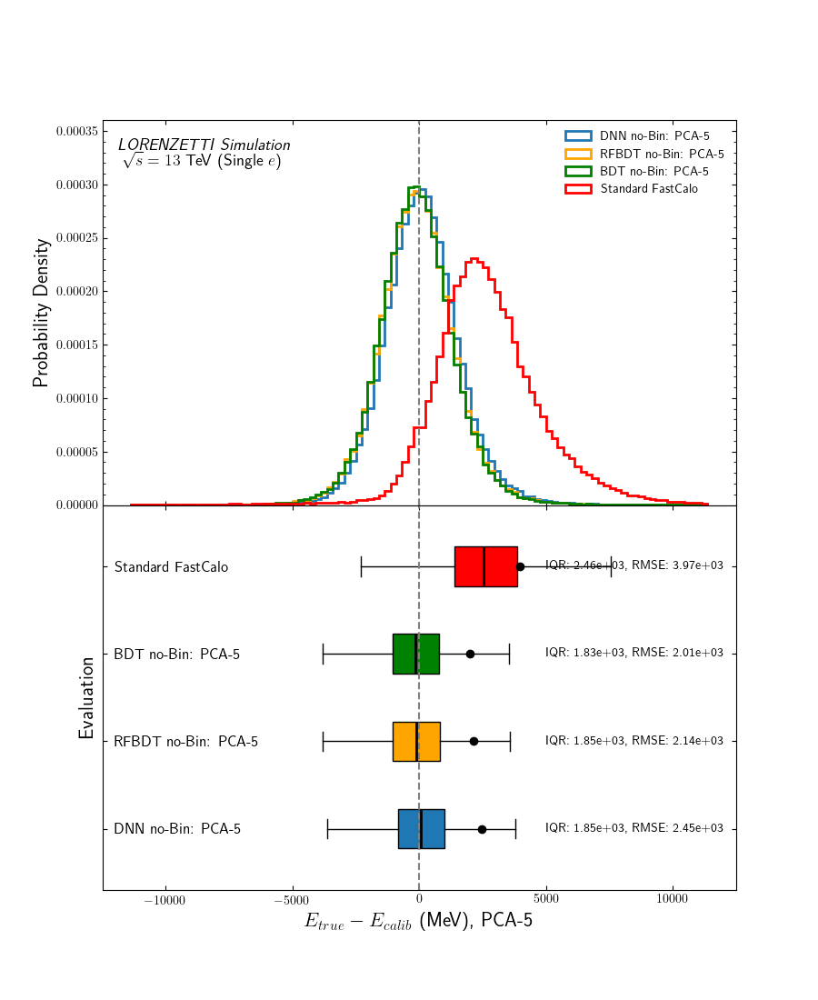

comparison_by_representation_PCA_50_01.png


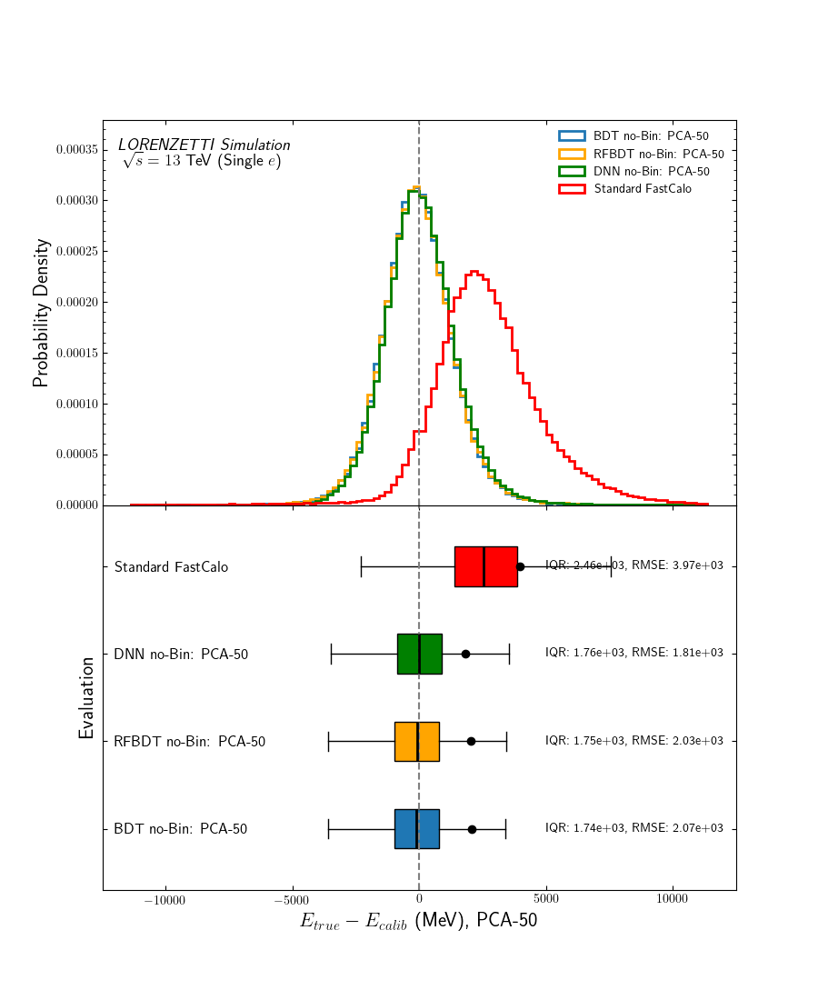

comparison_by_representation_Rings_2_01.png


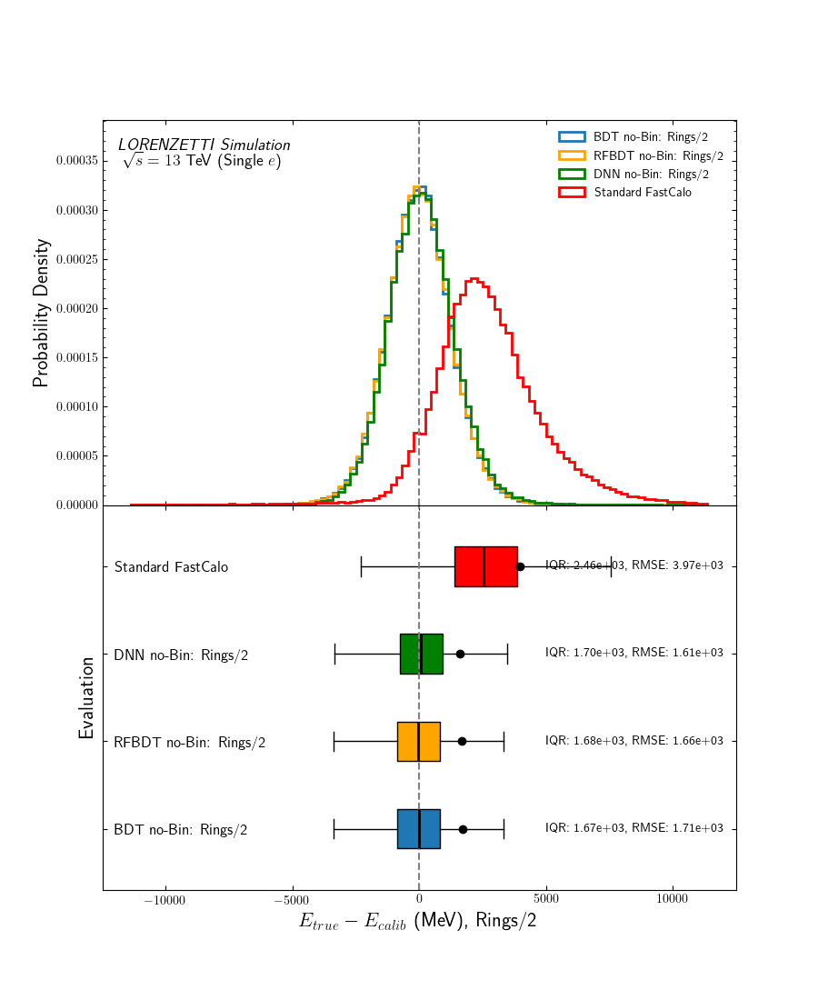

comparison_by_representation_Rings_1_100_01.png


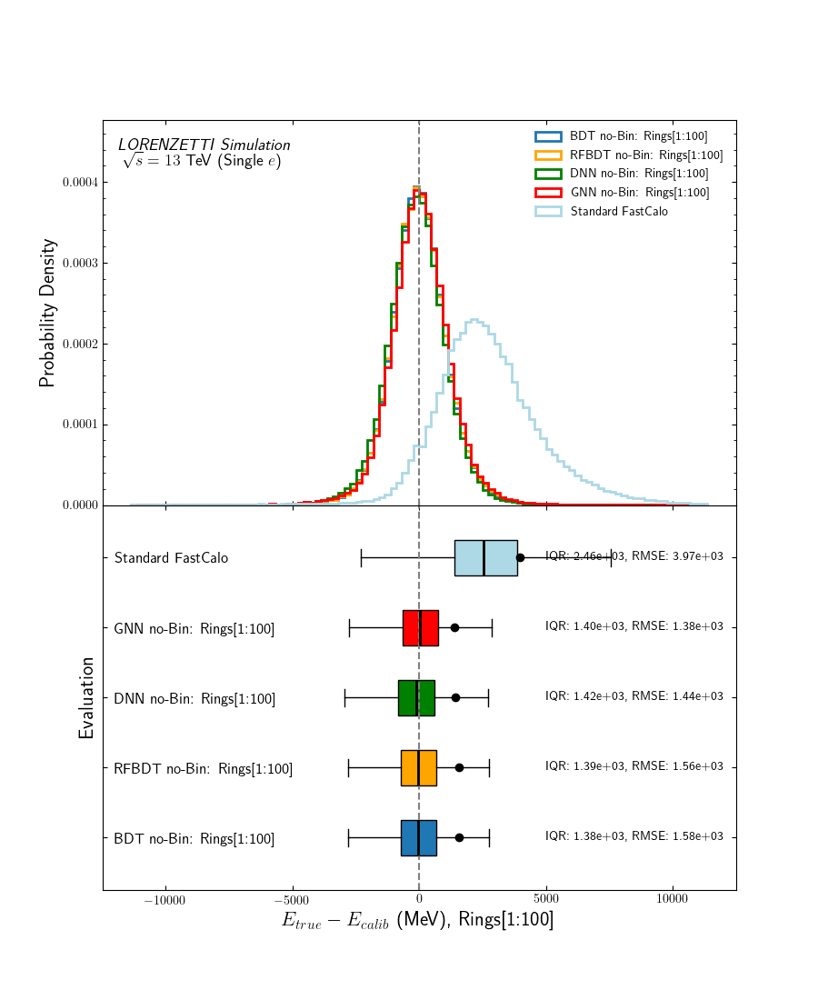

comparison_by_family_rings_cell747_01.png


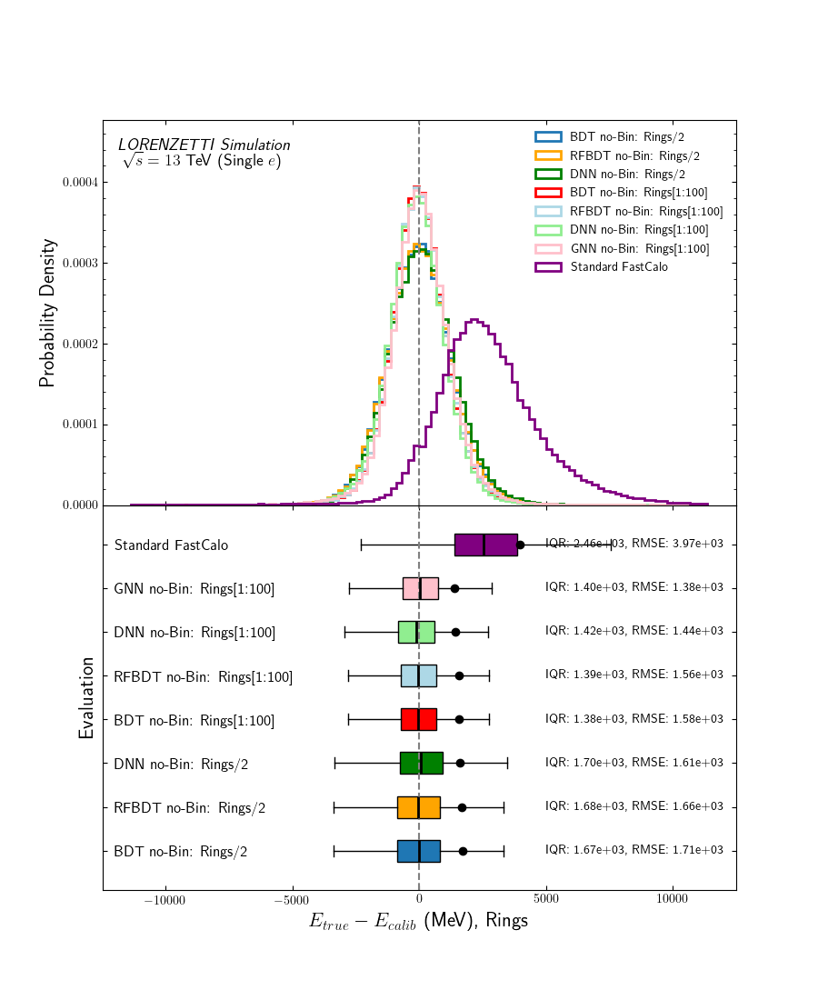

comparison_by_family_corr_cell747_01.png


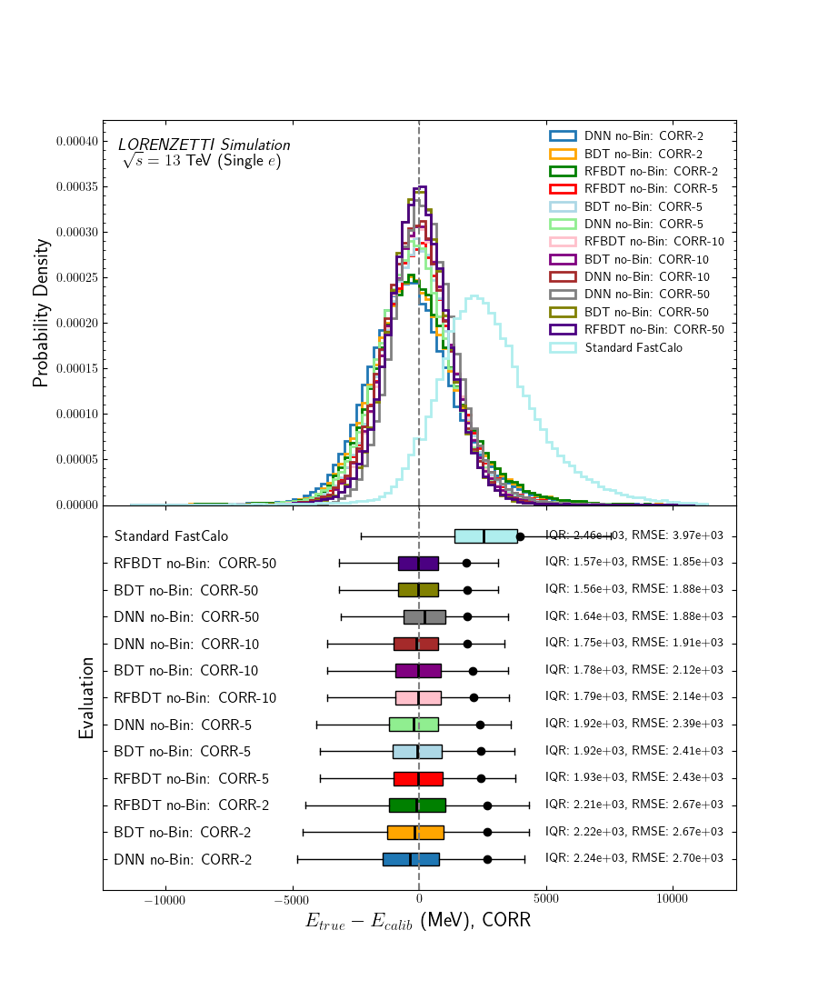

comparison_by_family_muti_cell747_01.png


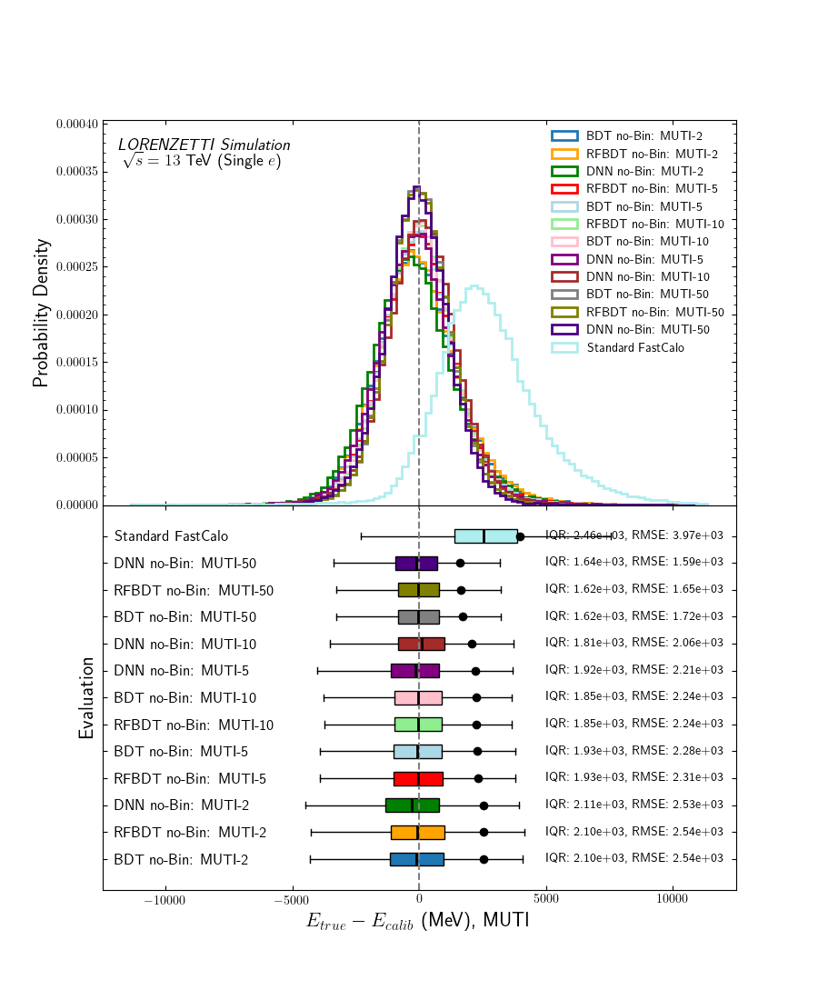

comparison_by_family_pca_cell747_01.png


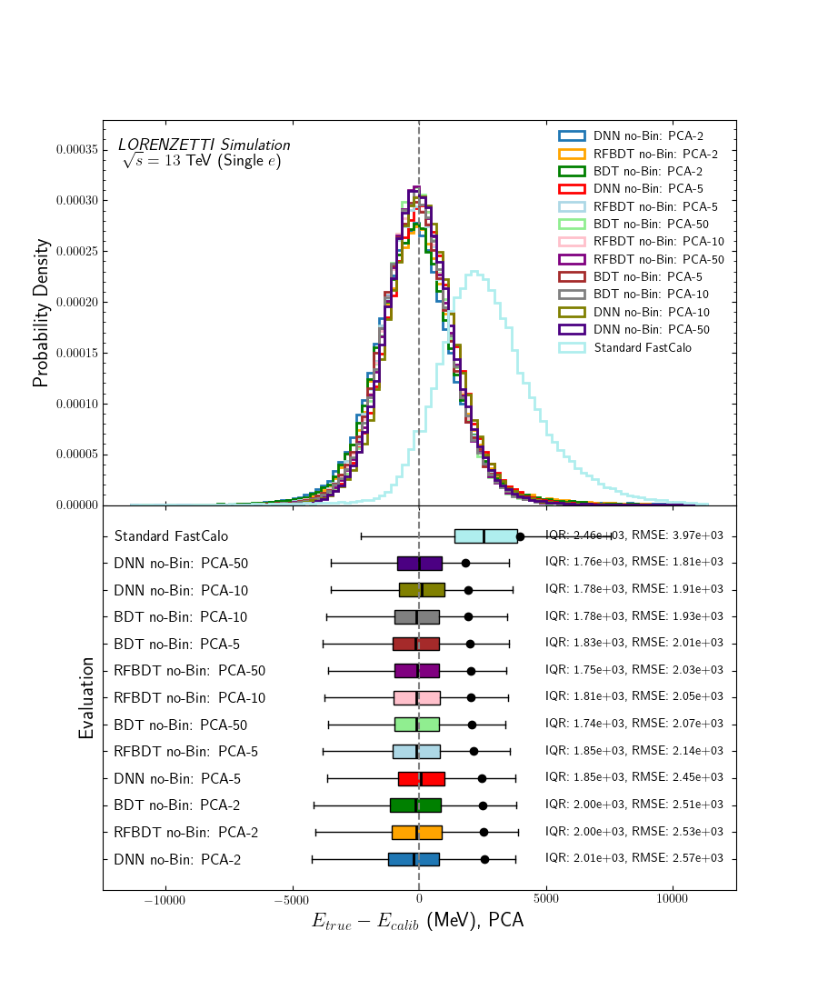

comparison_by_family_ica_cell747_01.png


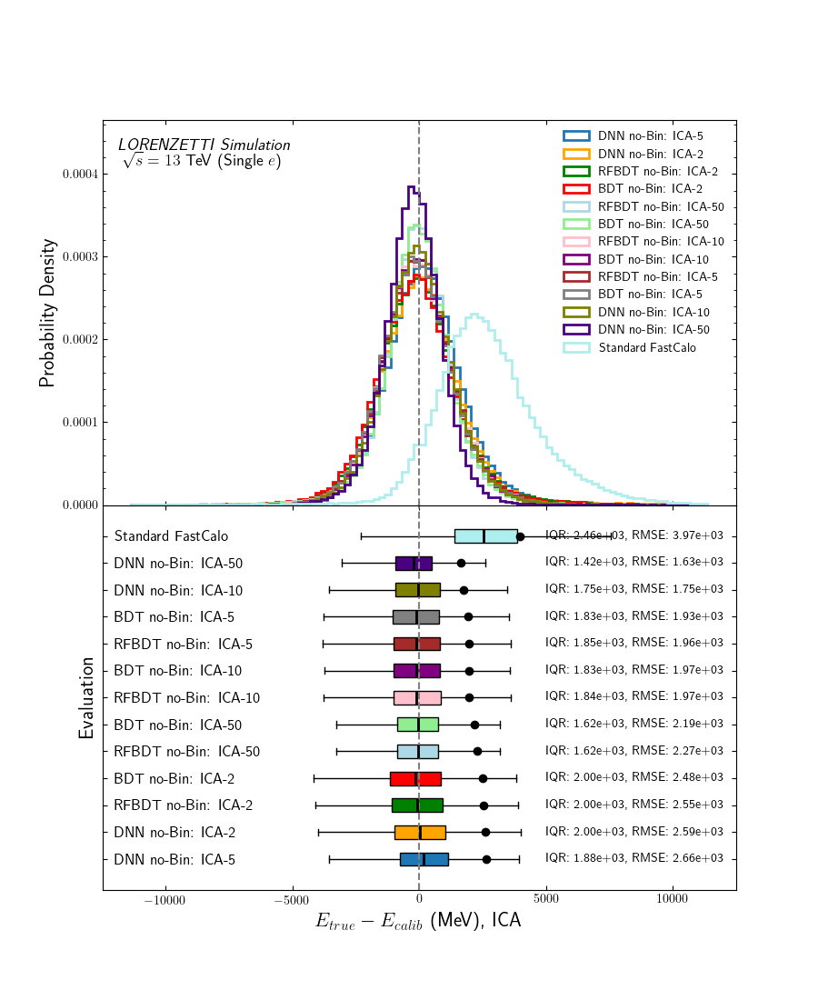

processing_times_cell708_01.png


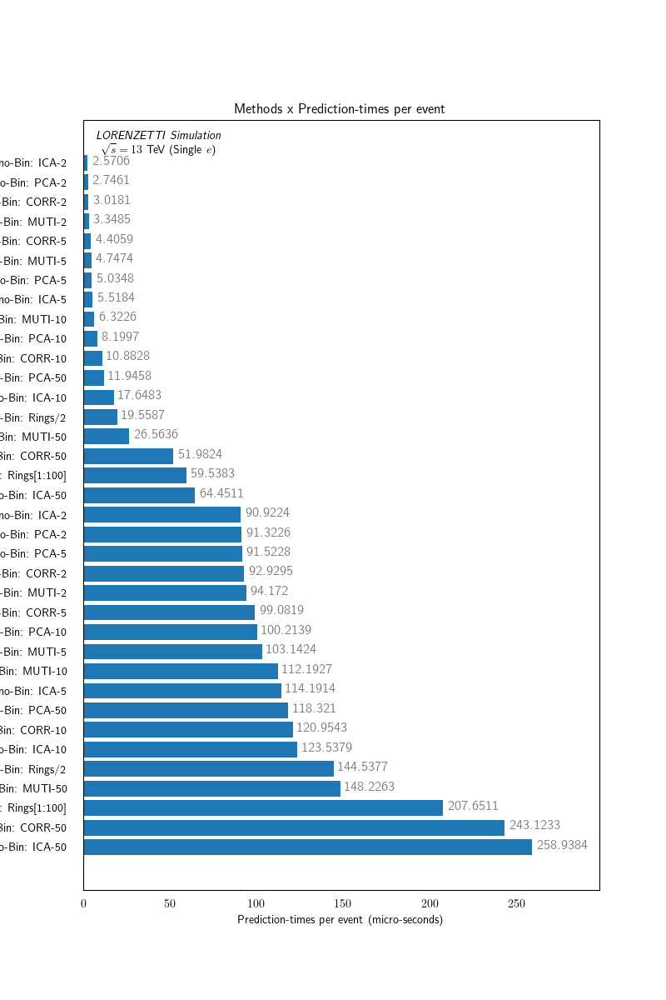

d0_vs_prediction_time_cell713_01.png


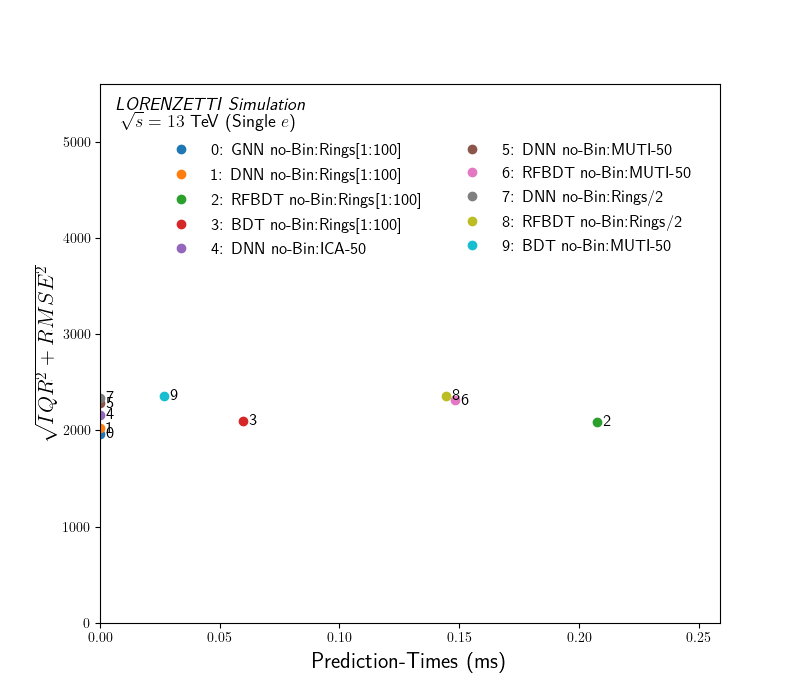

d0_vs_feature_count_cell722_01.png


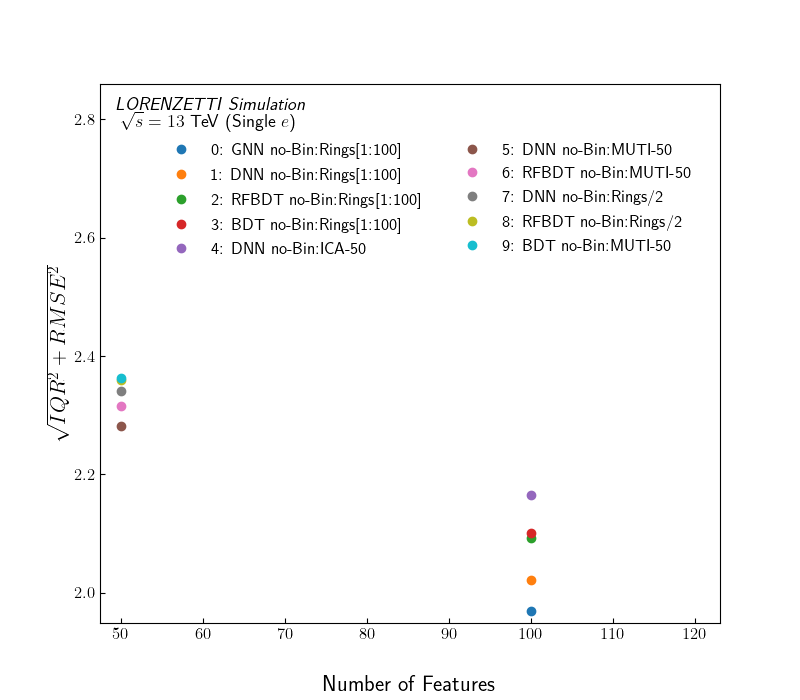

D0_ranked_cell733_01.png


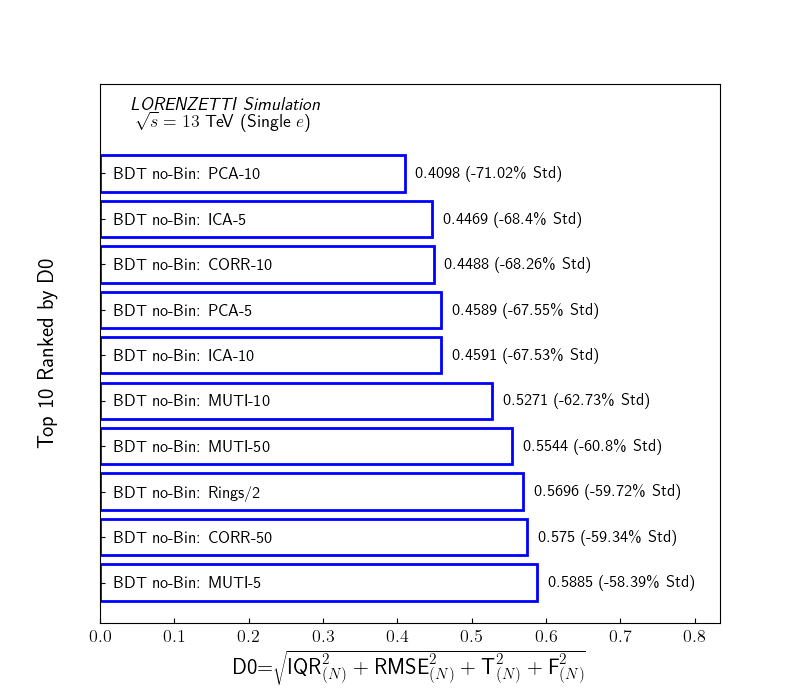

d0_ordered_by_D0_cell734_01.png


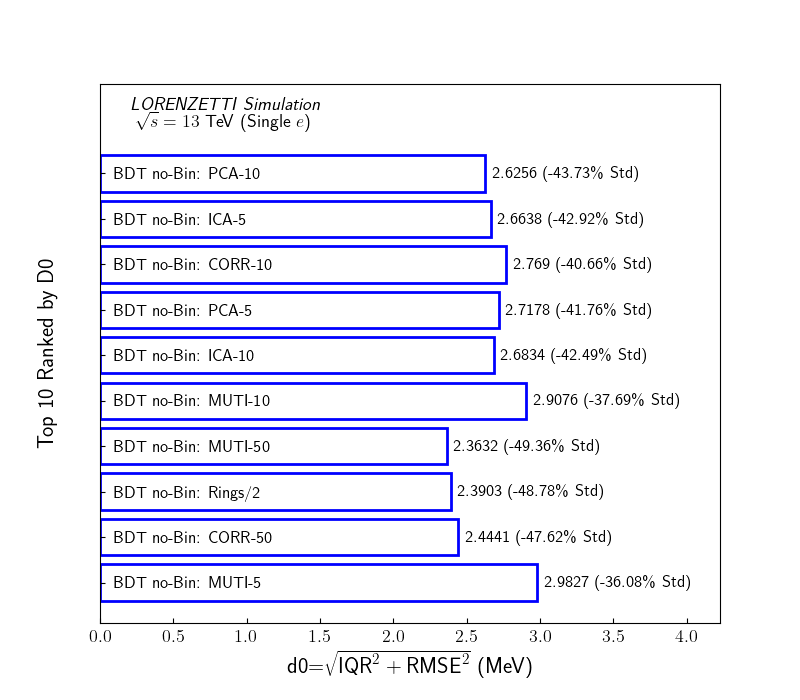

D0_ordered_by_d0_cell735_01.png


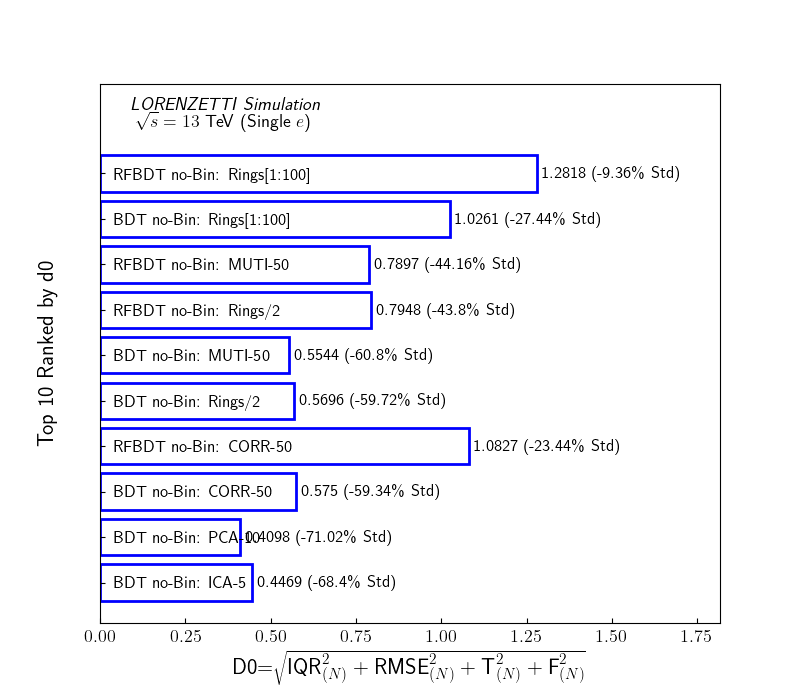

top_ten_by_d0_cells756_757_01.png


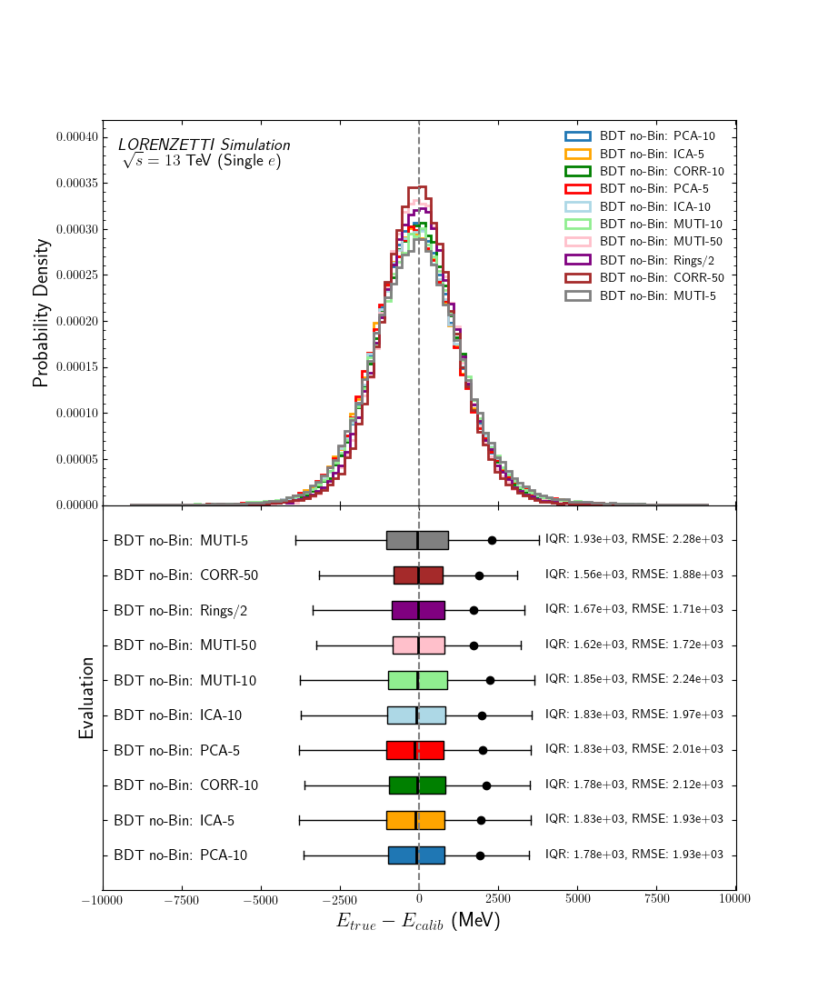

paired_difference_qq_cell789_01.png


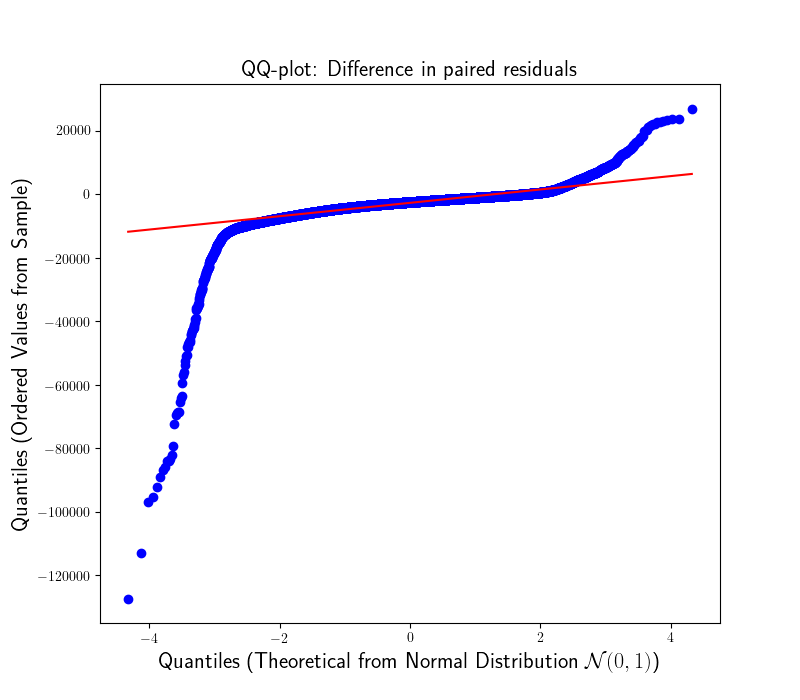

paired_qq_001_cell805_01.png


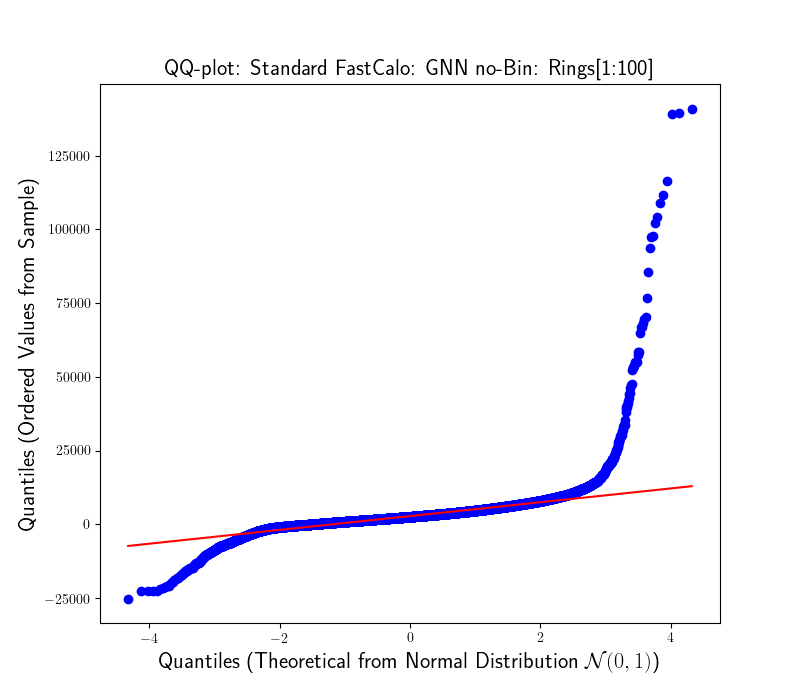

paired_qq_001_cell805_02.png


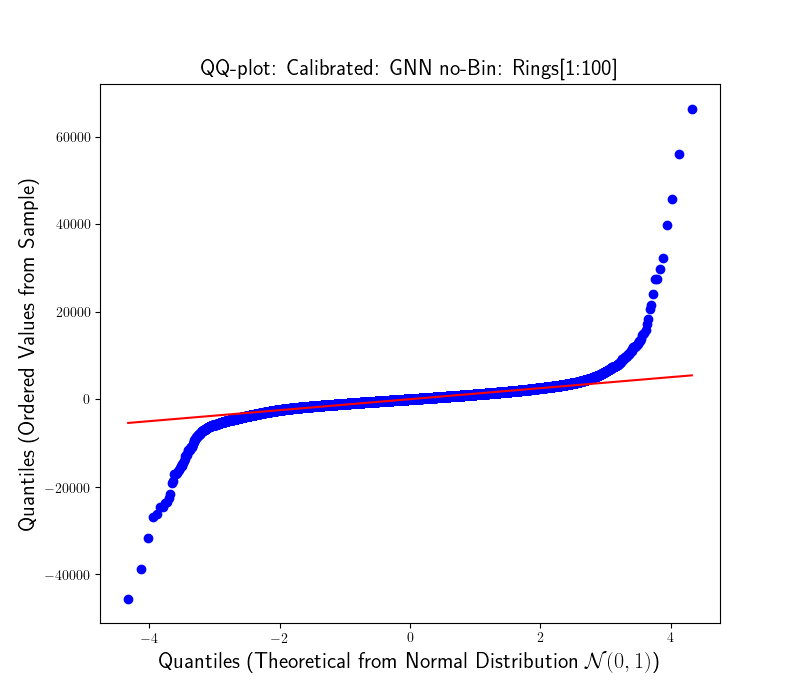

paired_qq_001_cell805_03.png


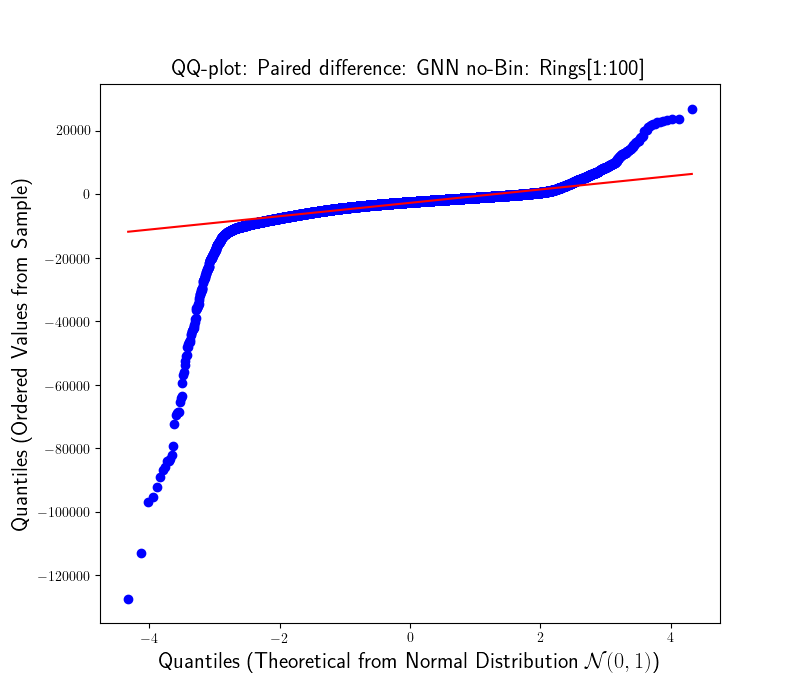

paired_qq_002_cell805_01.png


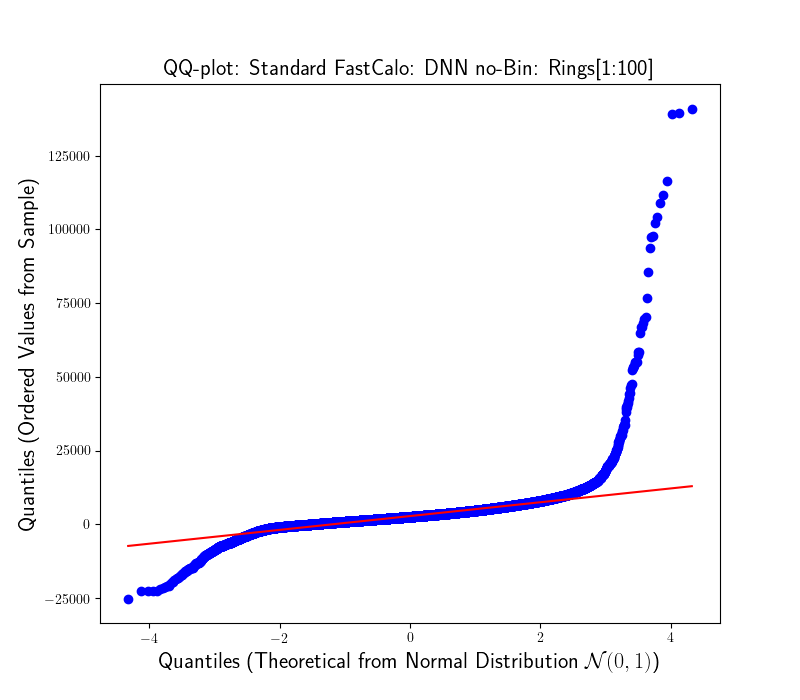

paired_qq_002_cell805_02.png


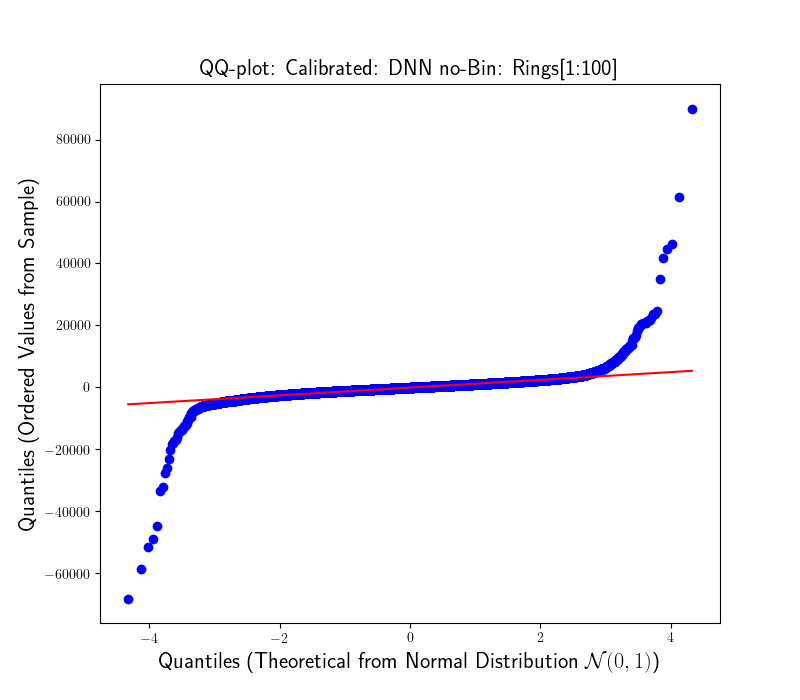

paired_qq_002_cell805_03.png


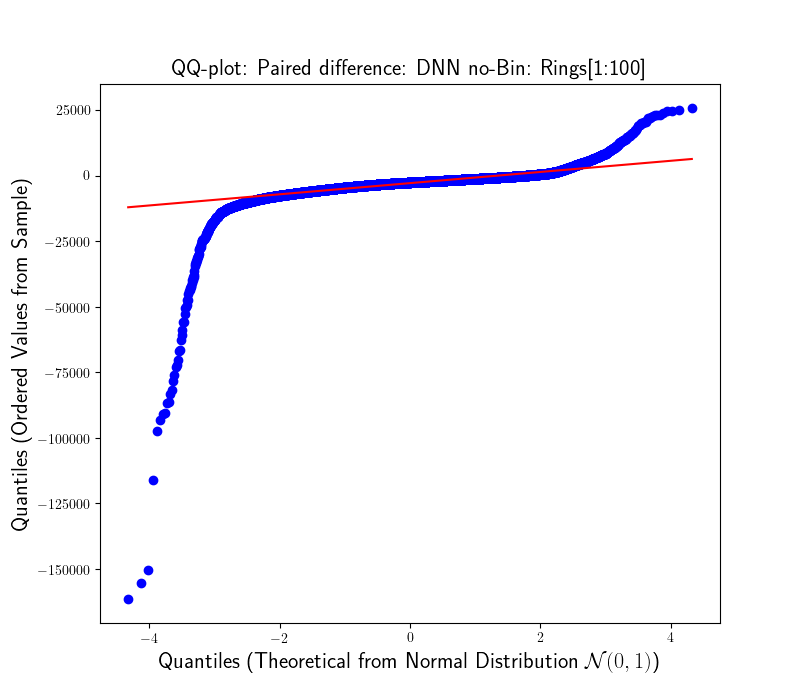

paired_qq_003_cell805_01.png


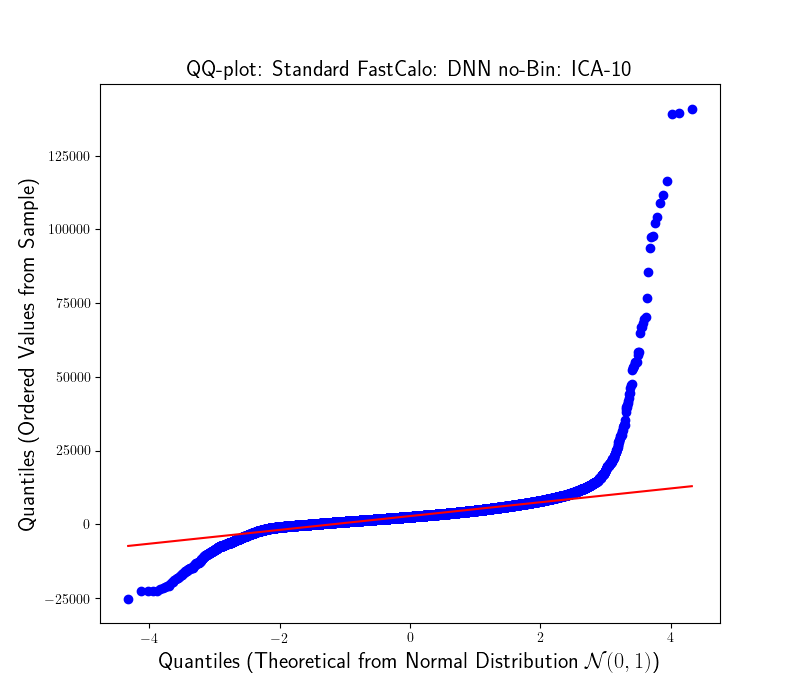

paired_qq_003_cell805_02.png


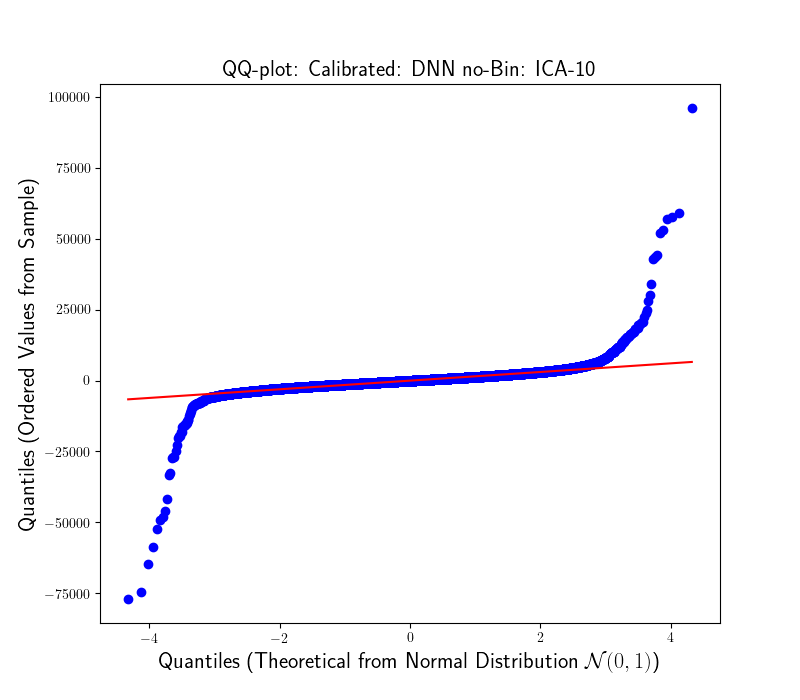

paired_qq_003_cell805_03.png


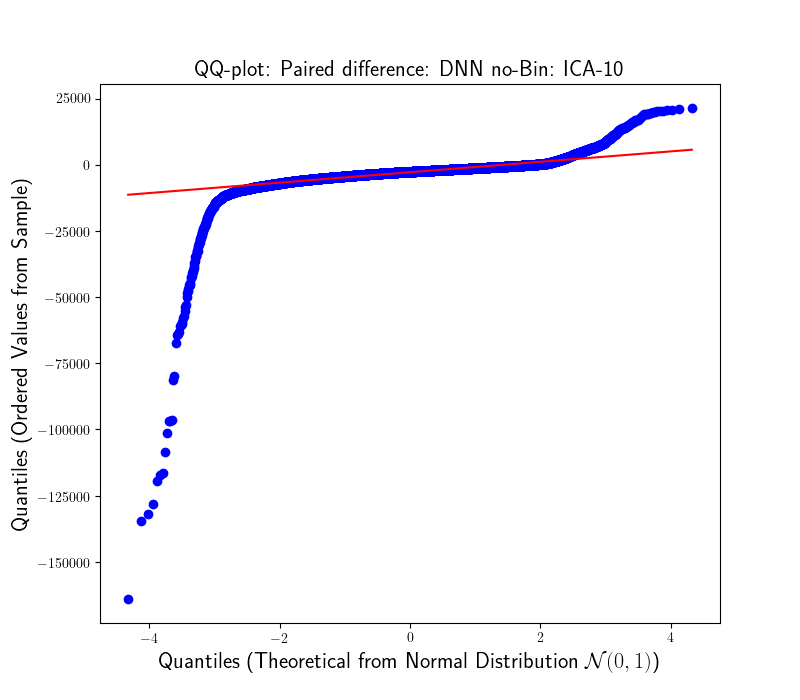

paired_qq_004_cell805_01.png


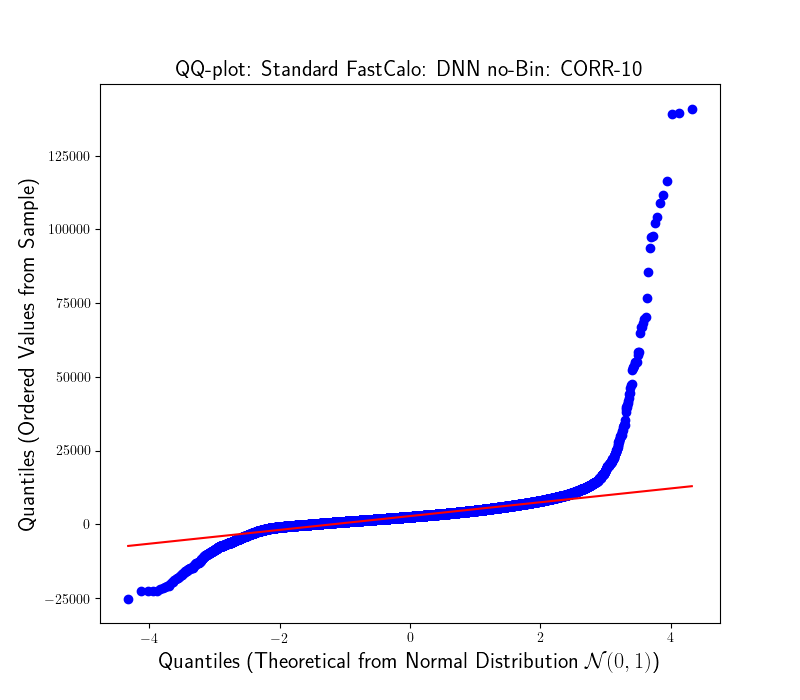

paired_qq_004_cell805_02.png


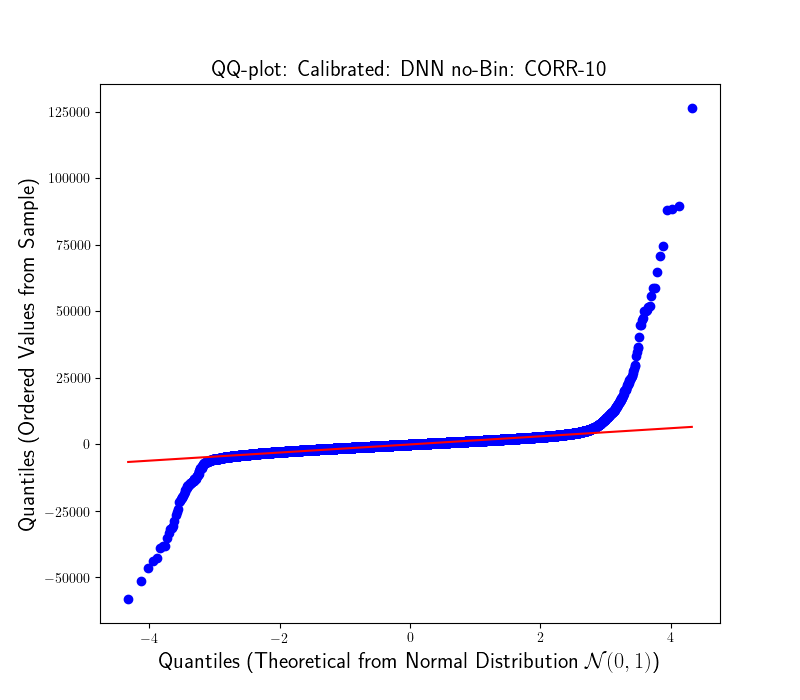

paired_qq_004_cell805_03.png


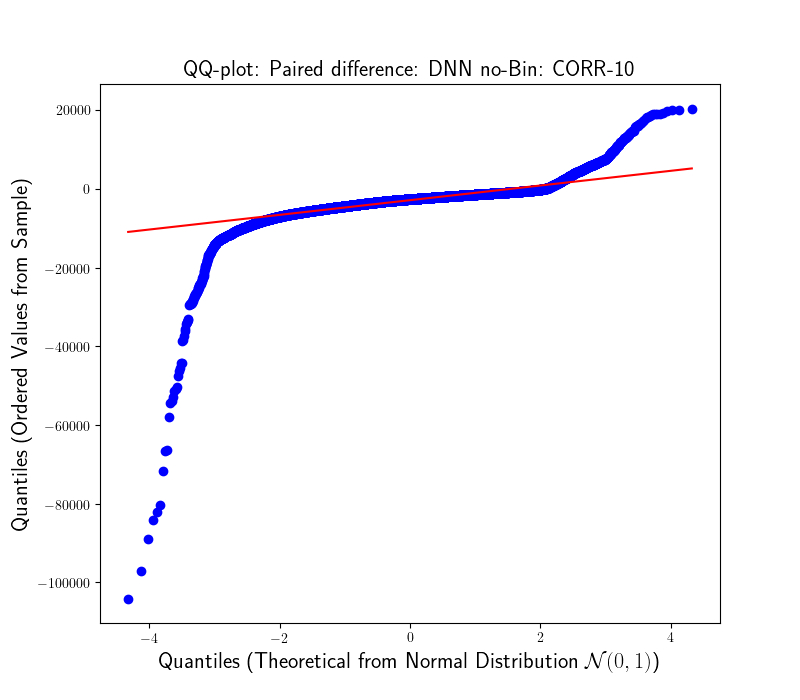

Displayed image files: 142


In [6]:
# Display every available data-generated panel by its article figure number.
# Original figure size, fonts, legends and color schemes come from source code.
from IPython.display import display, Image, Markdown
from pathlib import Path
FIGURE_ROWS=PAPER_REPORT['coverage']
seen=set()
for _,figure in FIGURE_ROWS.iterrows():
    display(Markdown(f"### Figure {int(figure['figure'])} — {figure['description']}"))
    if figure['status'] != 'generated':
        print('Status:', figure['status'])
        print('Unresolved inputs:', figure['missing_source_groups'])
    if figure['files']:
        for file in figure['files'].split(' | '):
            path=PLOT_OUTPUT/file
            if path.is_file():
                display(Image(filename=str(path)))
                seen.add(path.resolve())
# All other experimental configurations are still accessible; no models are
# silently dropped simply because they are not featured in the paper.
MORE_FIGURES=[p for p in PAPER_REPORT['files'] if p.resolve() not in seen]
if MORE_FIGURES:
    display(Markdown('### Additional archived configurations'))
    for path in MORE_FIGURES:
        print(path.name)
        display(Image(filename=str(path)))
print('Displayed image files:',len(PAPER_REPORT['files']))


## 6. Figure coverage and reproducibility checks


In [7]:
# A paper result figure is complete only when all its required source groups exist.
display(PAPER_REPORT['coverage'])
remaining=PAPER_REPORT['coverage'].query("status != 'generated'")
if len(remaining):
    display(Markdown(f"**{len(remaining)} paper figures have missing or partial inputs.**"))
    display(remaining[['figure','description','status','missing_source_groups','error']])
else:
    print('Every indexed paper result figure was produced from archived predictions and/or source events.')
print('Coverage index:', PLOT_OUTPUT/'paper_figure_coverage.csv')
print('Generated PNGs:',len(PAPER_REPORT['files']))
if not PAPER_REPORT['files']:
    raise FileNotFoundError('No figures generated. Inspect the saved result pickle directory and Lorenzetti dataset path.')


,paper,figure,description,status,files,missing_source_groups,error
0,information_fusion,5,Energy distributions and true/fast scatter,generated,source_diagnostics\original_true_fast_histogra...,,
1,information_fusion,6,Standardized error and distribution goodness-o...,generated,source_diagnostics\original_standardized_error...,,
2,information_fusion,7,True calibration factor vs eta and ET,generated,source_diagnostics\original_true_alpha_eta_01....,,
3,information_fusion,8,100 ring distributions,generated,source_diagnostics\original_100_ring_boxplot_0...,,
4,information_fusion,9,"CORR, MI, PCA and ICA feature map",generated,source_diagnostics\original_feature_relevance_...,,
5,information_fusion,10,Calibration residual distributions by represen...,generated,trained_model_figures\original_hist_boxplot_co...,,
6,information_fusion,11,Joint error and complexity ranking,generated,trained_model_figures\original_d0_ranking_01.png,,
7,information_fusion,12,IQR in eta and energy regions,generated,trained_model_figures\original_segmented_01.pn...,,
8,information_fusion,13,MAE and RMSE in eta and energy regions,generated,trained_model_figures\original_segmented_03.pn...,,
9,information_fusion,14,Calibration-factor regional boxplots,generated,trained_model_figures\original_segmented_boxpl...,,


**1 paper figures have missing or partial inputs.**

,figure,description,status,missing_source_groups,error
14,19,Neural accuracy–efficiency trade-off,missing_input,original_Fig38,Missing measured CPU times for all four config...


Coverage index: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\results\replayed\information_fusion\paper_figures\paper_figure_coverage.csv
Generated PNGs: 142
